# [14.2] V-JEPA and Video World Models (solutions)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter14_jepa_world_models/exercises/part2_vjepa/14.2_V-JEPA_and_Video_World_Models_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter14_jepa_world_models/exercises/part2_vjepa/14.2_V-JEPA_and_Video_World_Models_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

## Predict what would distinguish a world model from a similarity shortcut

Before opening either lesson, predict which evidence would separate learned dynamics from
a representation that preserves clip identity. First fix the scratch lab's spatial tube pretraining
and future-mask stress test; then separately fix the frozen V-JEPA 2 generated world.

## Content & Learning Objectives

### 1️⃣ Paper mechanics and persistence

> ##### Learning Objectives
>
> - Implement unique physical clip keys, tubelets, spatial tube masks and visible-only encoding.
> - Implement stop-gradient targets, plain L1, EMA, training and all evaluation subfunctions.
> - Challenge future-mask retrieval with persistence, blank future, exact dynamics and tie audits.

### 2️⃣ Frozen world-state controls

> ##### Learning Objectives
>
> - Build the exact shape-video world and map object boxes to latent tokens.
> - Write held-out probe, transition, occlusion and targeted-versus-random patch gates.
> - Inspect the full frozen-model feature, head-training and intervention code inline.

### Distinct protocols and honest gaps

The scratch curriculum trains a tiny V-JEPA on toroidal one-object clips and asks whether it beats
persistence on an out-of-distribution future mask. The frozen curriculum uses a pinned V-JEPA 2
ViT-L on a different 200-video world and trains small heads on its fixed features. The first
negative dynamics result and the second scoped state-readout controls answer different questions.
Keep their splits, masks, losses, labels, margins, galleries and histories separate.

These sources do not implement a controlled object-permanence comparison between scratch V-JEPA and
released V-JEPA 2. The scratch world has no occlusion. The released-model source does not establish
V-JEPA 2-AC action-token control, dense V-JEPA 2.1 features, real-video permanence, planning, or
superiority to other model families. Those broader syllabus claims remain gaps.

In [1]:
from __future__ import annotations

MAIN = __name__ == "__main__"

In [2]:
from torch import Tensor
from dataclasses import dataclass

@dataclass(frozen=True)
class VideoWorldBatch:
    videos: Tensor
    state_labels: Tensor
    color_labels: Tensor
    direction_labels: Tensor
    start_xy: Tensor
    velocity_xy: Tensor
    clip_keys: Tensor


@dataclass(frozen=True)
class DuplicateAudit:
    train_examples: int
    test_examples: int
    train_unique: int
    test_unique: int
    train_duplicates: int
    test_duplicates: int
    train_test_overlap: int
    is_disjoint: bool


@dataclass(frozen=True)
class ReversalCollisionAudit:
    reversed_examples: int
    reversed_unique: int
    reversed_duplicates: int
    reversed_pretraining_overlap: int
    reversed_probe_fit_overlap: int
    reversed_test_overlap: int
    collision_free: bool


@dataclass(frozen=True)
class RetrievalDetails:
    accuracy: float
    top1_indices: Tensor
    true_indices: Tensor
    true_ranks: Tensor
    tie_counts: Tensor
    matched_cosines: Tensor


@dataclass(frozen=True)
class PredictorMetrics:
    teacher_latent_cosine: float
    retrieval_accuracy: float
    tied_queries: int
    max_tie_count: int


@dataclass(frozen=True)
class MetricInterval:
    mean: float
    minimum: float
    maximum: float


@dataclass(frozen=True)
class CollapseDiagnostics:
    feature_std: float
    mean_pairwise_cosine: float
    effective_rank: float
    non_collapsed: bool


@dataclass(frozen=True)
class VJEPAMetrics:
    initial_train_loss: float
    final_train_loss: float
    train_loss_ratio: float
    color_probe_accuracy: float
    direction_probe_accuracy: float
    state_probe_accuracy: float
    random_label_state_accuracy: float
    reversed_color_accuracy: float
    reversed_original_direction_accuracy: float
    reversed_physical_direction_accuracy: float
    reversed_original_state_accuracy: float
    reversed_physical_state_accuracy: float
    random_encoder_color_accuracy: float
    random_encoder_direction_accuracy: float
    random_encoder_state_accuracy: float
    predictors: dict[str, PredictorMetrics]
    feature_std: float
    mean_pairwise_cosine: float
    effective_rank: float
    effective_rank_max: int
    non_collapsed: bool
    duplicate_audit: DuplicateAudit
    reversal_audit: ReversalCollisionAudit

# 1️⃣ Paper mechanics and persistence

> ##### Learning Objectives
>
> - Implement unique physical clip keys, tubelets, spatial tube masks and visible-only encoding.
> - Implement stop-gradient targets, plain L1, EMA, training and all evaluation subfunctions.
> - Challenge future-mask retrieval with persistence, blank future, exact dynamics and tie audits.

### [14.3] V-JEPA from Scratch: A Persistence-Shortcut Lab

This notebook asks one deliberately adversarial question: **does a paper-mechanics V-JEPA trained on
a tiny moving-object world learn enough dynamics to beat persistence on an unseen future mask?**

You will implement the released method's core mechanics, then try to falsify the stronger
world-model claim. The checked result is a negative result: this toy protocol can verify masked
latent learning, but it does not establish dynamics beyond copy-last-frame.

The evidence chain is visible and learner-owned:

> canonical clips -> collision-free splits -> tubelets -> spatial tube masks -> stop-gradient target -> L1 predictor -> EMA teacher -> future-mask stress test

The future-only mask is explicitly out of distribution relative to pretraining. Exact dynamics is an
oracle, persistence is the serious shortcut baseline, and all predictors are scored in the same
EMA-teacher space. A blank-future control tests whether the teacher's final-slice features retain
context even when every future pixel is erased.

## Learning goals

You will be able to:

- construct unique clip keys and physically canonical reversed keys;
- exclude forward and reversed collisions from pretraining, probe-fit, and held-out splits;
- implement Conv3D tubelets and spatial blocks repeated through time;
- verify that masked pixels cannot enter the online encoder;
- implement stop-gradient, target layer normalization, plain L1 prediction, and EMA;
- write and test the full `train_small_vjepa` loop yourself;
- separate an in-distribution spatial-tube task from an out-of-distribution future-mask stress test;
- fit balanced probe suites and score temporal reversal under physical labels;
- report tie-aware retrieval and tie counts against persistence, exact dynamics, and random controls;
- prove why the redundant 96-column temporal summary has effective-rank maximum 72.

In [3]:
import copy
import hashlib
import inspect
import json
import math
import os
import random
import sys
from dataclasses import asdict, dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import torch as t
import torch.nn.functional as F
from IPython.display import Markdown, display
from torch import Tensor, nn

scratch_chapter = "chapter14_jepa_world_models"
scratch_section = "part3_vjepa_from_scratch"
if MAIN:
    scratch_root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / scratch_chapter).exists())
if MAIN:
    scratch_section_dir = scratch_root_dir / scratch_chapter / "exercises" / scratch_section
if MAIN:
    scratch_assets_dir = scratch_root_dir / scratch_chapter / "exercises" / "part2_vjepa" / "media"
if MAIN:
    if str(scratch_root_dir) not in sys.path:
        sys.path.append(str(scratch_root_dir))
if MAIN:
    if str(scratch_section_dir) not in sys.path:
        sys.path.insert(0, str(scratch_section_dir))
if MAIN:

    from chapter14_jepa_world_models.exercises.part3_vjepa_from_scratch import tests as scratch_tests
if MAIN:
    from chapter14_jepa_world_models.exercises.part3_vjepa_from_scratch import solutions as scratch_reference
if MAIN:
    scratch_tests.solutions = scratch_reference
if MAIN:

    t.set_num_threads(min(8, os.cpu_count() or 1))
if MAIN:
    device = t.device(os.environ.get("VJEPA_DEVICE", "cpu"))
if MAIN:
    print(f"device={device}; torch={t.__version__}")

scratch_GT_TIER = "GT-1"
scratch_EXERCISE_ID = "14_3_vjepa_from_scratch"
scratch_DIFFICULTY = 4
scratch_IMPORTANCE = 5
scratch_EXPECTED_RUNTIME = "three 1,000-step reference seeds; typically under five minutes on CPU"
scratch_REQUIRES_GPU = False
EVALUATION_PROTOCOL_VERSION = "vjepa-14.3-paper-l1-tube-mask-v4"
if MAIN:

    DIRECTIONS = t.tensor([[1, 0], [-1, 0], [0, 1], [0, -1]], dtype=t.long)
if MAIN:
    REVERSED_DIRECTIONS = t.tensor([1, 0, 3, 2], dtype=t.long)

device=cpu; torch=2.15.0+cu134


## Part 1: Implement Paper Mechanics

Will excluding forward clip keys also exclude their physical reverses? Predict a failure of key-only
splitting.

### Exercise 1: Build Canonical, Collision-Free Video Worlds

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

A clip key is `(color, direction, start_x, start_y)`. Its physical reverse starts at the original
final position and moves in the opposite direction. Implement both key systems, then construct the
held-out world so forward and reversed test keys avoid pretraining keys and avoid each other.

<details><summary>Expected output</summary>

```text
train duplicates=0; test duplicates=0; train/test overlap=0
reversed/test and reversed/pretraining overlap=0
```
</details>

<details><summary>Help</summary>

For key `(c, d, x, y)`, the reversed start is `(x, y) + (frames - 1) * velocity[d]` modulo image
size. Reversal is an involution: applying it twice must recover the original key.
</details>


<details>
<summary>Solution</summary>

```python
def reverse_canonical_keys(
    clip_keys: Tensor,
    *,
    frames: int,
    image_size: int,
    speed: int = 1,
) -> Tensor:
    """Return physical keys for clips played backward.

    A reversed clip starts at the original final position and moves in the
    opposite direction. This is a canonical physical key, not a relabeled copy
    of the original key.
    """

    if clip_keys.ndim != 2 or clip_keys.shape[1] != 4:
        raise ValueError("clip_keys must have shape (examples, 4).")
    if frames < 2 or image_size < 1 or speed < 1:
        raise ValueError("frames, image_size, and speed must define a valid moving clip.")
    keys = clip_keys.long()
    direction = keys[:, 1]
    if not ((0 <= direction) & (direction < 4)).all():
        raise ValueError("direction keys must lie in [0, 3].")
    velocity = DIRECTIONS.to(keys.device)[direction] * speed
    reversed_start = (keys[:, 2:] + (frames - 1) * velocity) % image_size
    reversed_direction = REVERSED_DIRECTIONS.to(keys.device)[direction]
    return t.stack([keys[:, 0], reversed_direction, reversed_start[:, 0], reversed_start[:, 1]], dim=1)

def make_moving_object_batch(
    n_samples: int,
    *,
    frames: int = 6,
    image_size: int = 16,
    object_size: int = 4,
    speed: int = 1,
    seed: int = 0,
    excluded_clip_keys: Tensor | None = None,
    excluded_reverse_against_keys: Tensor | None = None,
    disallow_reverse_pairs: bool = False,
    device: t.device | str = "cpu",
) -> VideoWorldBatch:
    """Generate balanced videos with unique ``(color, direction, x, y)`` keys."""

    if n_samples < 8:
        raise ValueError("n_samples must be at least 8 so every state is represented.")
    if frames < 4 or image_size < object_size + 2:
        raise ValueError("The requested world is too small for the motion horizon.")

    generator = t.Generator(device="cpu").manual_seed(seed)
    videos = t.zeros(n_samples, frames, 3, image_size, image_size)
    color_labels = t.arange(n_samples) % 2
    direction_labels = (t.arange(n_samples) // 2) % 4
    start_xy = t.empty(n_samples, 2, dtype=t.long)
    velocity_xy = DIRECTIONS[direction_labels] * speed

    excluded: set[tuple[int, int, int, int]] = set()
    if excluded_clip_keys is not None:
        if excluded_clip_keys.ndim != 2 or excluded_clip_keys.shape[1] != 4:
            raise ValueError("excluded_clip_keys must have shape (examples, 4).")
        excluded = {tuple(int(value) for value in row) for row in excluded_clip_keys.cpu().tolist()}

    reverse_excluded: set[tuple[int, int, int, int]] = set()
    if excluded_reverse_against_keys is not None:
        if excluded_reverse_against_keys.ndim != 2 or excluded_reverse_against_keys.shape[1] != 4:
            raise ValueError("excluded_reverse_against_keys must have shape (examples, 4).")
        reverse_excluded = {
            tuple(int(value) for value in row) for row in excluded_reverse_against_keys.cpu().tolist()
        }

    selected: set[tuple[int, int, int, int]] = set()

    for color in range(2):
        for direction in range(4):
            sample_indices = ((color_labels == color) & (direction_labels == direction)).nonzero().flatten()
            available = []
            dx, dy = (int(value) for value in DIRECTIONS[direction].tolist())
            reversed_direction = int(REVERSED_DIRECTIONS[direction])
            for position in range(image_size * image_size):
                x, y = position % image_size, position // image_size
                key = (color, direction, x, y)
                reversed_key = (
                    color,
                    reversed_direction,
                    (x + (frames - 1) * speed * dx) % image_size,
                    (y + (frames - 1) * speed * dy) % image_size,
                )
                if key in excluded or reversed_key in reverse_excluded:
                    continue
                if disallow_reverse_pairs and (key in selected or reversed_key in selected):
                    continue
                available.append(position)
            if len(sample_indices) > len(available):
                raise ValueError("Not enough unique clip keys remain after exclusions.")
            order = t.randperm(len(available), generator=generator)[: len(sample_indices)]
            chosen = t.tensor(available, dtype=t.long)[order]
            start_xy[sample_indices, 0] = chosen % image_size
            start_xy[sample_indices, 1] = chosen // image_size
            for position in chosen.tolist():
                selected.add((color, direction, position % image_size, position // image_size))

    for index in range(n_samples):
        dx, dy = velocity_xy[index].tolist()
        x0, y0 = (int(value) for value in start_xy[index].tolist())

        color = t.tensor([1.0, 0.12, 0.12]) if color_labels[index] == 0 else t.tensor([0.1, 0.7, 1.0])
        for frame in range(frames):
            x = (x0 + frame * dx) % image_size
            y = (y0 + frame * dy) % image_size
            for offset_y in range(object_size):
                for offset_x in range(object_size):
                    videos[index, frame, :, (y + offset_y) % image_size, (x + offset_x) % image_size] = color

    state_labels = color_labels * 4 + direction_labels
    clip_keys = t.stack([color_labels, direction_labels, start_xy[:, 0], start_xy[:, 1]], dim=1)
    return VideoWorldBatch(
        videos=videos.to(device),
        state_labels=state_labels.to(device),
        color_labels=color_labels.to(device),
        direction_labels=direction_labels.to(device),
        start_xy=start_xy.to(device),
        velocity_xy=velocity_xy.to(device),
        clip_keys=clip_keys.to(device),
    )

def make_disjoint_worlds(
    train_samples: int,
    test_samples: int,
    *,
    seed: int = 0,
    test_seed: int | None = None,
    device: t.device | str = "cpu",
) -> tuple[VideoWorldBatch, VideoWorldBatch]:
    """Build balanced train/test worlds whose clip keys cannot overlap."""

    train_world = make_moving_object_batch(train_samples, seed=seed, device=device)
    test_world = make_moving_object_batch(
        test_samples,
        seed=seed + 10_000 if test_seed is None else test_seed,
        excluded_clip_keys=train_world.clip_keys,
        excluded_reverse_against_keys=train_world.clip_keys,
        disallow_reverse_pairs=True,
        device=device,
    )
    audit = audit_clip_splits(train_world, test_world)
    if not audit.is_disjoint:
        raise RuntimeError(f"Clip split construction failed: {audit}")
    return train_world, test_world

def audit_clip_splits(train_world: VideoWorldBatch, test_world: VideoWorldBatch) -> DuplicateAudit:
    """Count within-split duplicates and cross-split overlap from explicit keys."""

    train_keys = {tuple(int(value) for value in row) for row in train_world.clip_keys.cpu().tolist()}
    test_keys = {tuple(int(value) for value in row) for row in test_world.clip_keys.cpu().tolist()}
    train_duplicates = len(train_world.clip_keys) - len(train_keys)
    test_duplicates = len(test_world.clip_keys) - len(test_keys)
    overlap = len(train_keys & test_keys)
    return DuplicateAudit(
        train_examples=len(train_world.clip_keys),
        test_examples=len(test_world.clip_keys),
        train_unique=len(train_keys),
        test_unique=len(test_keys),
        train_duplicates=train_duplicates,
        test_duplicates=test_duplicates,
        train_test_overlap=overlap,
        is_disjoint=train_duplicates == 0 and test_duplicates == 0 and overlap == 0,
    )
```

</details>

In [4]:
def reverse_canonical_keys(
    clip_keys: Tensor,
    *,
    frames: int,
    image_size: int,
    speed: int = 1,
) -> Tensor:
    """Return physical keys for clips played backward.

    A reversed clip starts at the original final position and moves in the
    opposite direction. This is a canonical physical key, not a relabeled copy
    of the original key.
    """

    if clip_keys.ndim != 2 or clip_keys.shape[1] != 4:
        raise ValueError("clip_keys must have shape (examples, 4).")
    if frames < 2 or image_size < 1 or speed < 1:
        raise ValueError("frames, image_size, and speed must define a valid moving clip.")
    keys = clip_keys.long()
    direction = keys[:, 1]
    if not ((0 <= direction) & (direction < 4)).all():
        raise ValueError("direction keys must lie in [0, 3].")
    velocity = DIRECTIONS.to(keys.device)[direction] * speed
    reversed_start = (keys[:, 2:] + (frames - 1) * velocity) % image_size
    reversed_direction = REVERSED_DIRECTIONS.to(keys.device)[direction]
    return t.stack([keys[:, 0], reversed_direction, reversed_start[:, 0], reversed_start[:, 1]], dim=1)

def make_moving_object_batch(
    n_samples: int,
    *,
    frames: int = 6,
    image_size: int = 16,
    object_size: int = 4,
    speed: int = 1,
    seed: int = 0,
    excluded_clip_keys: Tensor | None = None,
    excluded_reverse_against_keys: Tensor | None = None,
    disallow_reverse_pairs: bool = False,
    device: t.device | str = "cpu",
) -> VideoWorldBatch:
    """Generate balanced videos with unique ``(color, direction, x, y)`` keys."""

    if n_samples < 8:
        raise ValueError("n_samples must be at least 8 so every state is represented.")
    if frames < 4 or image_size < object_size + 2:
        raise ValueError("The requested world is too small for the motion horizon.")

    generator = t.Generator(device="cpu").manual_seed(seed)
    videos = t.zeros(n_samples, frames, 3, image_size, image_size)
    color_labels = t.arange(n_samples) % 2
    direction_labels = (t.arange(n_samples) // 2) % 4
    start_xy = t.empty(n_samples, 2, dtype=t.long)
    velocity_xy = DIRECTIONS[direction_labels] * speed

    excluded: set[tuple[int, int, int, int]] = set()
    if excluded_clip_keys is not None:
        if excluded_clip_keys.ndim != 2 or excluded_clip_keys.shape[1] != 4:
            raise ValueError("excluded_clip_keys must have shape (examples, 4).")
        excluded = {tuple(int(value) for value in row) for row in excluded_clip_keys.cpu().tolist()}

    reverse_excluded: set[tuple[int, int, int, int]] = set()
    if excluded_reverse_against_keys is not None:
        if excluded_reverse_against_keys.ndim != 2 or excluded_reverse_against_keys.shape[1] != 4:
            raise ValueError("excluded_reverse_against_keys must have shape (examples, 4).")
        reverse_excluded = {
            tuple(int(value) for value in row) for row in excluded_reverse_against_keys.cpu().tolist()
        }

    selected: set[tuple[int, int, int, int]] = set()

    for color in range(2):
        for direction in range(4):
            sample_indices = ((color_labels == color) & (direction_labels == direction)).nonzero().flatten()
            available = []
            dx, dy = (int(value) for value in DIRECTIONS[direction].tolist())
            reversed_direction = int(REVERSED_DIRECTIONS[direction])
            for position in range(image_size * image_size):
                x, y = position % image_size, position // image_size
                key = (color, direction, x, y)
                reversed_key = (
                    color,
                    reversed_direction,
                    (x + (frames - 1) * speed * dx) % image_size,
                    (y + (frames - 1) * speed * dy) % image_size,
                )
                if key in excluded or reversed_key in reverse_excluded:
                    continue
                if disallow_reverse_pairs and (key in selected or reversed_key in selected):
                    continue
                available.append(position)
            if len(sample_indices) > len(available):
                raise ValueError("Not enough unique clip keys remain after exclusions.")
            order = t.randperm(len(available), generator=generator)[: len(sample_indices)]
            chosen = t.tensor(available, dtype=t.long)[order]
            start_xy[sample_indices, 0] = chosen % image_size
            start_xy[sample_indices, 1] = chosen // image_size
            for position in chosen.tolist():
                selected.add((color, direction, position % image_size, position // image_size))

    for index in range(n_samples):
        dx, dy = velocity_xy[index].tolist()
        x0, y0 = (int(value) for value in start_xy[index].tolist())

        color = t.tensor([1.0, 0.12, 0.12]) if color_labels[index] == 0 else t.tensor([0.1, 0.7, 1.0])
        for frame in range(frames):
            x = (x0 + frame * dx) % image_size
            y = (y0 + frame * dy) % image_size
            for offset_y in range(object_size):
                for offset_x in range(object_size):
                    videos[index, frame, :, (y + offset_y) % image_size, (x + offset_x) % image_size] = color

    state_labels = color_labels * 4 + direction_labels
    clip_keys = t.stack([color_labels, direction_labels, start_xy[:, 0], start_xy[:, 1]], dim=1)
    return VideoWorldBatch(
        videos=videos.to(device),
        state_labels=state_labels.to(device),
        color_labels=color_labels.to(device),
        direction_labels=direction_labels.to(device),
        start_xy=start_xy.to(device),
        velocity_xy=velocity_xy.to(device),
        clip_keys=clip_keys.to(device),
    )

def make_disjoint_worlds(
    train_samples: int,
    test_samples: int,
    *,
    seed: int = 0,
    test_seed: int | None = None,
    device: t.device | str = "cpu",
) -> tuple[VideoWorldBatch, VideoWorldBatch]:
    """Build balanced train/test worlds whose clip keys cannot overlap."""

    train_world = make_moving_object_batch(train_samples, seed=seed, device=device)
    test_world = make_moving_object_batch(
        test_samples,
        seed=seed + 10_000 if test_seed is None else test_seed,
        excluded_clip_keys=train_world.clip_keys,
        excluded_reverse_against_keys=train_world.clip_keys,
        disallow_reverse_pairs=True,
        device=device,
    )
    audit = audit_clip_splits(train_world, test_world)
    if not audit.is_disjoint:
        raise RuntimeError(f"Clip split construction failed: {audit}")
    return train_world, test_world

def audit_clip_splits(train_world: VideoWorldBatch, test_world: VideoWorldBatch) -> DuplicateAudit:
    """Count within-split duplicates and cross-split overlap from explicit keys."""

    train_keys = {tuple(int(value) for value in row) for row in train_world.clip_keys.cpu().tolist()}
    test_keys = {tuple(int(value) for value in row) for row in test_world.clip_keys.cpu().tolist()}
    train_duplicates = len(train_world.clip_keys) - len(train_keys)
    test_duplicates = len(test_world.clip_keys) - len(test_keys)
    overlap = len(train_keys & test_keys)
    return DuplicateAudit(
        train_examples=len(train_world.clip_keys),
        test_examples=len(test_world.clip_keys),
        train_unique=len(train_keys),
        test_unique=len(test_keys),
        train_duplicates=train_duplicates,
        test_duplicates=test_duplicates,
        train_test_overlap=overlap,
        is_disjoint=train_duplicates == 0 and test_duplicates == 0 and overlap == 0,
    )
if MAIN:

    scratch_tests.test_make_moving_object_batch_exact(make_moving_object_batch)

if MAIN:
    scratch_tests.test_make_moving_object_batch_rejects_invalid_world(make_moving_object_batch)

if MAIN:
    scratch_tests.test_disjoint_world_splits_and_duplicate_audit(make_disjoint_worlds, audit_clip_splits)

All tests in `test_make_moving_object_batch_exact` passed!
All tests in `test_make_moving_object_batch_rejects_invalid_world` passed!
All tests in `test_disjoint_world_splits_and_duplicate_audit` passed!


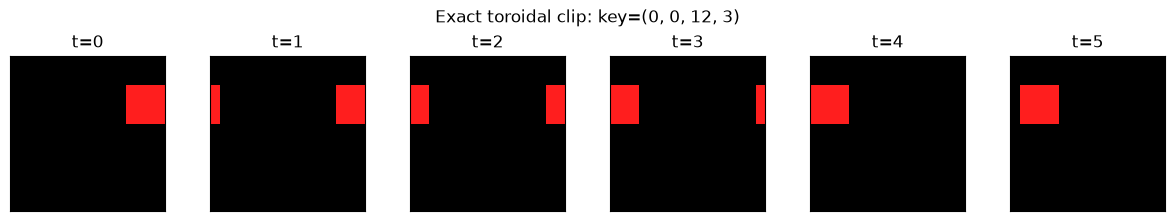

In [5]:
if MAIN:
    _, world_preview = make_disjoint_worlds(64, 64, seed=0)
if MAIN:
    fig, axes = plt.subplots(1, 6, figsize=(12, 2.1), constrained_layout=True)
if MAIN:
    for frame_index, axis in enumerate(axes):
        axis.imshow(world_preview.videos[24, frame_index].cpu().permute(1, 2, 0))
        axis.set_title(f"t={frame_index}")
        axis.set_xticks([])
        axis.set_yticks([])
if MAIN:
    fig.suptitle(f"Exact toroidal clip: key={tuple(world_preview.clip_keys[24].tolist())}")
if MAIN:
    plt.show()

<img src="../../exercises/part2_vjepa/media/vjepa_from_scratch_world.png" alt="Expected exact video world" width="950">

Predict the token count and axis ordering for the stated tubelet shape, and an invalid shape to
reject.

### Exercise 2: Turn Video Into Tubelet Tokens

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Implement the grid calculation and a strided `Conv3d`. For `(6, 16, 16)` video and `(2, 4, 4)`
tubelets, the grid is `(3, 4, 4)`, or 48 tokens.

<details><summary>Help</summary>

PyTorch `Conv3d` expects `(batch, channels, time, height, width)`. Reject indivisible dimensions
instead of silently truncating them.
</details>

<details><summary>Expected output</summary>

A batch of two clips becomes (2, 48, d_model) tokens on a (3, 4, 4) grid.

</details>

<details>
<summary>Solution</summary>

```python
def tubelet_grid(video_shape: tuple[int, int, int], tubelet_size: tuple[int, int, int]) -> tuple[int, int, int]:
    frames, height, width = video_shape
    tubelet_t, patch_h, patch_w = tubelet_size
    if frames % tubelet_t or height % patch_h or width % patch_w:
        raise ValueError("Video dimensions must be divisible by the tubelet dimensions.")
    return frames // tubelet_t, height // patch_h, width // patch_w

class TubeletEmbedding(nn.Module):
    def __init__(
        self,
        in_channels: int = 3,
        d_model: int = 24,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.tubelet_size = tubelet_size
        self.proj = nn.Conv3d(
            in_channels,
            d_model,
            kernel_size=tubelet_size,
            stride=tubelet_size,
        )

    def forward(self, video: Tensor) -> tuple[Tensor, tuple[int, int, int]]:
        if video.ndim != 5:
            raise ValueError("video must have shape (batch, frames, channels, height, width).")
        tubelet_grid((video.shape[1], *video.shape[-2:]), self.tubelet_size)
        features = self.proj(video.permute(0, 2, 1, 3, 4))
        grid = tuple(int(value) for value in features.shape[-3:])
        tokens = features.flatten(2).transpose(1, 2)
        return tokens, grid
```

</details>

In [6]:
def tubelet_grid(video_shape: tuple[int, int, int], tubelet_size: tuple[int, int, int]) -> tuple[int, int, int]:
    frames, height, width = video_shape
    tubelet_t, patch_h, patch_w = tubelet_size
    if frames % tubelet_t or height % patch_h or width % patch_w:
        raise ValueError("Video dimensions must be divisible by the tubelet dimensions.")
    return frames // tubelet_t, height // patch_h, width // patch_w

class TubeletEmbedding(nn.Module):
    def __init__(
        self,
        in_channels: int = 3,
        d_model: int = 24,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.tubelet_size = tubelet_size
        self.proj = nn.Conv3d(
            in_channels,
            d_model,
            kernel_size=tubelet_size,
            stride=tubelet_size,
        )

    def forward(self, video: Tensor) -> tuple[Tensor, tuple[int, int, int]]:
        if video.ndim != 5:
            raise ValueError("video must have shape (batch, frames, channels, height, width).")
        tubelet_grid((video.shape[1], *video.shape[-2:]), self.tubelet_size)
        features = self.proj(video.permute(0, 2, 1, 3, 4))
        grid = tuple(int(value) for value in features.shape[-3:])
        tokens = features.flatten(2).transpose(1, 2)
        return tokens, grid
if MAIN:

    scratch_tests.test_tubelet_grid_and_embedding(tubelet_grid, TubeletEmbedding)

if MAIN:
    scratch_tests.test_tubelet_embedding_rejects_wrong_rank(tubelet_grid, TubeletEmbedding)

All tests in `test_tubelet_grid_and_embedding` passed!
All tests in `test_tubelet_embedding_rejects_wrong_rank` passed!


Predict whether a spatial tube mask repeats through time and whether a future-only mask has the same
distribution.

### Exercise 3: Implement V-JEPA Spatial Tube Masks

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Sample one contiguous spatial target block and repeat exactly the same block through all temporal
tubelets. Also implement a separate full-future mask used only for the later stress test.

> **Paper connection.** Figure 2 of [Bardes et al.](https://arxiv.org/abs/2404.08471) uses spatial blocks
> repeated across the temporal dimension. The [released mask
> generator](https://github.com/facebookresearch/jepa/blob/main/src/masks/multiblock3d.py) defaults its
> temporal prediction scale to the full clip. Our tiny version uses one block rather than the release's
> multi-block sampling.

<details><summary>Expected output</summary>

```text
each 2x2 spatial block contributes 3 * 2 * 2 = 12 target tubelets
all temporal mask slices are identical
```
</details>

<details><summary>Help</summary>

Sample a spatial origin per clip, then broadcast the same block across time.

</details>

<details>
<summary>Solution</summary>

```python
def spatiotemporal_sincos(grid: tuple[int, int, int], d_model: int, *, device: t.device | str) -> Tensor:
    """Return fixed factorized time/y/x positional features with shape (1, tokens, d_model)."""

    if d_model < 6:
        raise ValueError("d_model must be at least 6.")
    coordinates = t.stack(
        t.meshgrid(
            t.arange(grid[0], device=device),
            t.arange(grid[1], device=device),
            t.arange(grid[2], device=device),
            indexing="ij",
        ),
        dim=-1,
    ).reshape(-1, 3)
    axis_dim = max(2, (d_model // 3) // 2 * 2)
    frequencies = t.exp(
        -math.log(10_000.0) * t.arange(0, axis_dim, 2, device=device) / axis_dim
    )
    parts = []
    for axis in range(3):
        angles = coordinates[:, axis : axis + 1].float() * frequencies[None]
        parts.append(t.cat([angles.sin(), angles.cos()], dim=-1))
    position = t.cat(parts, dim=-1)
    if position.shape[-1] < d_model:
        position = F.pad(position, (0, d_model - position.shape[-1]))
    return position[:, :d_model].unsqueeze(0)

def sample_spatial_tube_mask(
    batch_size: int,
    grid: tuple[int, int, int],
    *,
    block_shape: tuple[int, int] = (2, 2),
    generator: t.Generator | None = None,
    device: t.device | str = "cpu",
) -> Tensor:
    """Sample one spatial block per clip and repeat it through every time step."""

    time, height, width = grid
    bh, bw = block_shape
    if not (1 <= bh <= height and 1 <= bw <= width):
        raise ValueError("block_shape must fit inside the spatial tubelet grid.")

    mask = t.zeros(batch_size, time, height, width, dtype=t.bool)
    for batch_index in range(batch_size):
        start_y = int(t.randint(0, height - bh + 1, (), generator=generator))
        start_x = int(t.randint(0, width - bw + 1, (), generator=generator))
        mask[batch_index, :, start_y : start_y + bh, start_x : start_x + bw] = True
    return mask.flatten(1).to(device)

def future_prediction_mask(
    batch_size: int,
    grid: tuple[int, int, int],
    *,
    future_steps: int = 1,
    device: t.device | str = "cpu",
) -> Tensor:
    """Mask full final time slices for the out-of-distribution future diagnostic."""

    time, height, width = grid
    if not 1 <= future_steps < time:
        raise ValueError("future_steps must leave at least one visible temporal slice.")
    mask = t.zeros(batch_size, time, height, width, dtype=t.bool)
    mask[:, -future_steps:] = True
    return mask.flatten(1).to(device)

def expand_tubelet_mask(
    target_mask: Tensor,
    grid: tuple[int, int, int],
    tubelet_size: tuple[int, int, int],
) -> Tensor:
    """Expand a tubelet mask to a per-frame, per-pixel boolean mask."""

    if target_mask.ndim != 2 or target_mask.shape[1] != math.prod(grid):
        raise ValueError("target_mask must match the flattened tubelet grid.")
    expanded = target_mask.reshape(len(target_mask), *grid)
    for dimension, repeats in enumerate(tubelet_size, start=1):
        expanded = expanded.repeat_interleave(repeats, dim=dimension)
    return expanded
```

</details>

In [7]:
def spatiotemporal_sincos(grid: tuple[int, int, int], d_model: int, *, device: t.device | str) -> Tensor:
    """Return fixed factorized time/y/x positional features with shape (1, tokens, d_model)."""

    if d_model < 6:
        raise ValueError("d_model must be at least 6.")
    coordinates = t.stack(
        t.meshgrid(
            t.arange(grid[0], device=device),
            t.arange(grid[1], device=device),
            t.arange(grid[2], device=device),
            indexing="ij",
        ),
        dim=-1,
    ).reshape(-1, 3)
    axis_dim = max(2, (d_model // 3) // 2 * 2)
    frequencies = t.exp(
        -math.log(10_000.0) * t.arange(0, axis_dim, 2, device=device) / axis_dim
    )
    parts = []
    for axis in range(3):
        angles = coordinates[:, axis : axis + 1].float() * frequencies[None]
        parts.append(t.cat([angles.sin(), angles.cos()], dim=-1))
    position = t.cat(parts, dim=-1)
    if position.shape[-1] < d_model:
        position = F.pad(position, (0, d_model - position.shape[-1]))
    return position[:, :d_model].unsqueeze(0)

def sample_spatial_tube_mask(
    batch_size: int,
    grid: tuple[int, int, int],
    *,
    block_shape: tuple[int, int] = (2, 2),
    generator: t.Generator | None = None,
    device: t.device | str = "cpu",
) -> Tensor:
    """Sample one spatial block per clip and repeat it through every time step."""

    time, height, width = grid
    bh, bw = block_shape
    if not (1 <= bh <= height and 1 <= bw <= width):
        raise ValueError("block_shape must fit inside the spatial tubelet grid.")

    mask = t.zeros(batch_size, time, height, width, dtype=t.bool)
    for batch_index in range(batch_size):
        start_y = int(t.randint(0, height - bh + 1, (), generator=generator))
        start_x = int(t.randint(0, width - bw + 1, (), generator=generator))
        mask[batch_index, :, start_y : start_y + bh, start_x : start_x + bw] = True
    return mask.flatten(1).to(device)

def future_prediction_mask(
    batch_size: int,
    grid: tuple[int, int, int],
    *,
    future_steps: int = 1,
    device: t.device | str = "cpu",
) -> Tensor:
    """Mask full final time slices for the out-of-distribution future diagnostic."""

    time, height, width = grid
    if not 1 <= future_steps < time:
        raise ValueError("future_steps must leave at least one visible temporal slice.")
    mask = t.zeros(batch_size, time, height, width, dtype=t.bool)
    mask[:, -future_steps:] = True
    return mask.flatten(1).to(device)

def expand_tubelet_mask(
    target_mask: Tensor,
    grid: tuple[int, int, int],
    tubelet_size: tuple[int, int, int],
) -> Tensor:
    """Expand a tubelet mask to a per-frame, per-pixel boolean mask."""

    if target_mask.ndim != 2 or target_mask.shape[1] != math.prod(grid):
        raise ValueError("target_mask must match the flattened tubelet grid.")
    expanded = target_mask.reshape(len(target_mask), *grid)
    for dimension, repeats in enumerate(tubelet_size, start=1):
        expanded = expanded.repeat_interleave(repeats, dim=dimension)
    return expanded
if MAIN:

    scratch_tests.test_spatiotemporal_sincos_is_factorized(spatiotemporal_sincos)

if MAIN:
    scratch_tests.test_spatial_tube_masks_repeat_through_time(sample_spatial_tube_mask)

if MAIN:
    scratch_tests.test_future_prediction_mask_is_separate_diagnostic(future_prediction_mask)

if MAIN:
    scratch_tests.test_expand_tubelet_mask_matches_pixels(expand_tubelet_mask)

All tests in `test_spatiotemporal_sincos_is_factorized` passed!
All tests in `test_spatial_tube_masks_repeat_through_time` passed!
All tests in `test_future_prediction_mask_is_separate_diagnostic` passed!
All tests in `test_expand_tubelet_mask_matches_pixels` passed!


Predict whether changing only masked pixels can change visible context tokens.

### Exercise 4: Encode Only Visible Context

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Remove target tokens before the online transformer. Then prove masked-pixel invariance: replacing
every masked pixel with random values must leave the visible representation exactly unchanged.

<details><summary>Interpretation</summary>

This semantic intervention catches target leakage that shape tests cannot. It works because the
Conv3D tubelets do not overlap.
</details>

<details><summary>Expected output</summary>

Visible context has 36 tokens; replacing masked pixels changes none of them.

</details>

<details><summary>Help</summary>

Add position vectors before packing. Equal visible counts permit a batched reshape.

</details>

<details>
<summary>Solution</summary>

```python
def pack_visible_tokens(tokens: Tensor, target_mask: Tensor) -> Tensor:
    """Remove masked tokens while preserving batch and raster order."""

    if target_mask.shape != tokens.shape[:2]:
        raise ValueError("target_mask must match the batch and token dimensions.")
    visible_counts = (~target_mask).sum(dim=1)
    if not t.equal(visible_counts, visible_counts[:1].expand_as(visible_counts)):
        raise ValueError("Every sample must expose the same number of visible tokens.")
    return tokens[~target_mask].reshape(tokens.shape[0], int(visible_counts[0]), tokens.shape[-1])

class TokenEncoder(nn.Module):
    def __init__(self, d_model: int = 24, n_heads: int = 3, depth: int = 1, mlp_ratio: int = 2) -> None:
        super().__init__()
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * mlp_ratio,
            dropout=0.0,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.blocks = nn.TransformerEncoder(layer, num_layers=depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, tokens: Tensor) -> Tensor:
        return self.norm(self.blocks(tokens))

class VideoEncoder(nn.Module):
    def __init__(
        self,
        d_model: int = 24,
        n_heads: int = 3,
        depth: int = 1,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.d_model = d_model
        self.tubelet = TubeletEmbedding(d_model=d_model, tubelet_size=tubelet_size)
        self.encoder = TokenEncoder(d_model=d_model, n_heads=n_heads, depth=depth)

    def tokenize(self, video: Tensor) -> tuple[Tensor, Tensor, tuple[int, int, int]]:
        tokens, grid = self.tubelet(video)
        positions = spatiotemporal_sincos(grid, self.d_model, device=tokens.device)
        return tokens, positions, grid

    def encode_all(self, video: Tensor) -> tuple[Tensor, tuple[int, int, int]]:
        tokens, positions, grid = self.tokenize(video)
        return self.encoder(tokens + positions), grid

    def encode_visible(self, video: Tensor, target_mask: Tensor) -> tuple[Tensor, Tensor, tuple[int, int, int]]:
        tokens, positions, grid = self.tokenize(video)
        positioned = tokens + positions
        return self.encoder(pack_visible_tokens(positioned, target_mask)), positions, grid
```

</details>

In [8]:
def pack_visible_tokens(tokens: Tensor, target_mask: Tensor) -> Tensor:
    """Remove masked tokens while preserving batch and raster order."""

    if target_mask.shape != tokens.shape[:2]:
        raise ValueError("target_mask must match the batch and token dimensions.")
    visible_counts = (~target_mask).sum(dim=1)
    if not t.equal(visible_counts, visible_counts[:1].expand_as(visible_counts)):
        raise ValueError("Every sample must expose the same number of visible tokens.")
    return tokens[~target_mask].reshape(tokens.shape[0], int(visible_counts[0]), tokens.shape[-1])

class TokenEncoder(nn.Module):
    def __init__(self, d_model: int = 24, n_heads: int = 3, depth: int = 1, mlp_ratio: int = 2) -> None:
        super().__init__()
        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * mlp_ratio,
            dropout=0.0,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.blocks = nn.TransformerEncoder(layer, num_layers=depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, tokens: Tensor) -> Tensor:
        return self.norm(self.blocks(tokens))

class VideoEncoder(nn.Module):
    def __init__(
        self,
        d_model: int = 24,
        n_heads: int = 3,
        depth: int = 1,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.d_model = d_model
        self.tubelet = TubeletEmbedding(d_model=d_model, tubelet_size=tubelet_size)
        self.encoder = TokenEncoder(d_model=d_model, n_heads=n_heads, depth=depth)

    def tokenize(self, video: Tensor) -> tuple[Tensor, Tensor, tuple[int, int, int]]:
        tokens, grid = self.tubelet(video)
        positions = spatiotemporal_sincos(grid, self.d_model, device=tokens.device)
        return tokens, positions, grid

    def encode_all(self, video: Tensor) -> tuple[Tensor, tuple[int, int, int]]:
        tokens, positions, grid = self.tokenize(video)
        return self.encoder(tokens + positions), grid

    def encode_visible(self, video: Tensor, target_mask: Tensor) -> tuple[Tensor, Tensor, tuple[int, int, int]]:
        tokens, positions, grid = self.tokenize(video)
        positioned = tokens + positions
        return self.encoder(pack_visible_tokens(positioned, target_mask)), positions, grid
if MAIN:

    scratch_tests.test_pack_visible_tokens_preserves_order(pack_visible_tokens)

if MAIN:
    scratch_tests.test_video_encoder_visible_shape(VideoEncoder)

if MAIN:
    scratch_tests.test_masked_pixels_cannot_change_visible_context(VideoEncoder)

All tests in `test_pack_visible_tokens_preserves_order` passed!
All tests in `test_video_encoder_visible_shape` passed!


All tests in `test_masked_pixels_cannot_change_visible_context` passed!


Predict which target parameters can receive gradients and which are updated by EMA.

### Exercise 5: Assemble Online Encoder, Predictor, and Teacher

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Reinsert learned mask tokens in the predictor, freeze a deep-copied target encoder, and
layer-normalize the full target encoder output under `no_grad` before selecting target positions.

> **Paper connection.** The V-JEPA target sees the full unmasked clip; masking is applied after target encoding. The online encoder sees only context tokens. The target path is stop-gradient and follows the online path by EMA.

<details><summary>Expected output</summary>

Predictions and targets have shape (batch, 12, 24); only predictions require gradients.

</details>

<details><summary>Help</summary>

Scatter projected context into visible slots, use mask tokens elsewhere, then select targets.

</details>

<details>
<summary>Solution</summary>

```python
class VideoPredictor(nn.Module):
    def __init__(self, d_model: int = 24, n_heads: int = 3, depth: int = 1) -> None:
        super().__init__()
        self.context_projection = nn.Linear(d_model, d_model)
        self.mask_token = nn.Parameter(t.zeros(1, 1, d_model))
        self.encoder = TokenEncoder(d_model=d_model, n_heads=n_heads, depth=depth)
        self.output_projection = nn.Linear(d_model, d_model)
        nn.init.normal_(self.mask_token, std=0.02)

    def forward(self, visible: Tensor, target_mask: Tensor, positions: Tensor) -> Tensor:
        batch_size, n_tokens = target_mask.shape
        full = self.mask_token.expand(batch_size, n_tokens, -1).clone()
        projected_visible = self.context_projection(visible)
        full[~target_mask] = projected_visible.reshape(-1, projected_visible.shape[-1])
        predicted = self.output_projection(self.encoder(full + positions))
        n_targets = int(target_mask[0].sum())
        return predicted[target_mask].reshape(batch_size, n_targets, -1)

class SmallVJEPA(nn.Module):
    def __init__(
        self,
        d_model: int = 24,
        n_heads: int = 3,
        encoder_depth: int = 1,
        predictor_depth: int = 1,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.context_encoder = VideoEncoder(d_model, n_heads, encoder_depth, tubelet_size)
        self.target_encoder = copy.deepcopy(self.context_encoder)
        for parameter in self.target_encoder.parameters():
            parameter.requires_grad_(False)
        self.predictor = VideoPredictor(d_model, n_heads, predictor_depth)

    def forward(self, video: Tensor, target_mask: Tensor) -> tuple[Tensor, Tensor, Tensor]:
        visible, positions, _ = self.context_encoder.encode_visible(video, target_mask)
        predicted = self.predictor(visible, target_mask, positions)
        with t.no_grad():
            target_all, _ = self.target_encoder.encode_all(video)
            target_all = F.layer_norm(target_all, (target_all.shape[-1],))
            n_targets = int(target_mask[0].sum())
            target = target_all[target_mask].reshape(video.shape[0], n_targets, -1)
        return predicted, target, visible
```

</details>

In [9]:
class VideoPredictor(nn.Module):
    def __init__(self, d_model: int = 24, n_heads: int = 3, depth: int = 1) -> None:
        super().__init__()
        self.context_projection = nn.Linear(d_model, d_model)
        self.mask_token = nn.Parameter(t.zeros(1, 1, d_model))
        self.encoder = TokenEncoder(d_model=d_model, n_heads=n_heads, depth=depth)
        self.output_projection = nn.Linear(d_model, d_model)
        nn.init.normal_(self.mask_token, std=0.02)

    def forward(self, visible: Tensor, target_mask: Tensor, positions: Tensor) -> Tensor:
        batch_size, n_tokens = target_mask.shape
        full = self.mask_token.expand(batch_size, n_tokens, -1).clone()
        projected_visible = self.context_projection(visible)
        full[~target_mask] = projected_visible.reshape(-1, projected_visible.shape[-1])
        predicted = self.output_projection(self.encoder(full + positions))
        n_targets = int(target_mask[0].sum())
        return predicted[target_mask].reshape(batch_size, n_targets, -1)

class SmallVJEPA(nn.Module):
    def __init__(
        self,
        d_model: int = 24,
        n_heads: int = 3,
        encoder_depth: int = 1,
        predictor_depth: int = 1,
        tubelet_size: tuple[int, int, int] = (2, 4, 4),
    ) -> None:
        super().__init__()
        self.context_encoder = VideoEncoder(d_model, n_heads, encoder_depth, tubelet_size)
        self.target_encoder = copy.deepcopy(self.context_encoder)
        for parameter in self.target_encoder.parameters():
            parameter.requires_grad_(False)
        self.predictor = VideoPredictor(d_model, n_heads, predictor_depth)

    def forward(self, video: Tensor, target_mask: Tensor) -> tuple[Tensor, Tensor, Tensor]:
        visible, positions, _ = self.context_encoder.encode_visible(video, target_mask)
        predicted = self.predictor(visible, target_mask, positions)
        with t.no_grad():
            target_all, _ = self.target_encoder.encode_all(video)
            target_all = F.layer_norm(target_all, (target_all.shape[-1],))
            n_targets = int(target_mask[0].sum())
            target = target_all[target_mask].reshape(video.shape[0], n_targets, -1)
        return predicted, target, visible
if MAIN:

    scratch_tests.test_predictor_places_visible_and_mask_tokens(VideoPredictor)

if MAIN:
    scratch_tests.test_small_vjepa_forward_stops_target_grad(SmallVJEPA)

All tests in `test_predictor_places_visible_and_mask_tokens` passed!


All tests in `test_small_vjepa_forward_stops_target_grad` passed!


Predict the exact teacher update and whether L1 should backpropagate into the target.

### Exercise 6: Implement EMA and the Paper L1 Objective

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Implement `target = momentum * target + (1 - momentum) * online` and mean absolute error from
predictor outputs to detached, layer-normalized target features.

> **Paper connection.** The [paper architecture](https://arxiv.org/abs/2404.08471) labels this edge `L1` and
> stop-gradient; the [released training
> loop](https://github.com/facebookresearch/jepa/blob/main/app/vjepa/train.py) computes a power-1 absolute
> feature loss for the V-JEPA term. This lab uses that term alone. There is no variance or covariance penalty
> in the primary objective.

<details><summary>Common bugs</summary>

Normalizing the prediction as well as the target, using Smooth L1, letting gradients enter the
teacher, or applying EMA before the online optimizer step.
</details>

<details><summary>Expected output</summary>

For target=0, online=2, momentum=0.75, EMA gives 0.5. L1 averages absolute errors.

</details>

<details><summary>Help</summary>

Detach target features, leave predictions unnormalized, and update matching parameter names.

</details>

<details>
<summary>Solution</summary>

```python
@t.no_grad()
def ema_update(target_encoder: nn.Module, context_encoder: nn.Module, momentum: float) -> None:
    if not 0.0 <= momentum <= 1.0:
        raise ValueError("EMA momentum must lie in [0, 1].")
    target_parameters = dict(target_encoder.named_parameters())
    context_parameters = dict(context_encoder.named_parameters())
    if target_parameters.keys() != context_parameters.keys():
        raise ValueError("Target and context encoders must have matching parameter names.")
    for name, target_parameter in target_parameters.items():
        target_parameter.mul_(momentum).add_(context_parameters[name], alpha=1.0 - momentum)
    target_buffers = dict(target_encoder.named_buffers())
    for name, target_buffer in target_buffers.items():
        target_buffer.copy_(dict(context_encoder.named_buffers())[name])

def vjepa_l1_loss(predicted: Tensor, target: Tensor) -> Tensor:
    """Paper objective: mean absolute error to stop-gradient teacher targets."""

    if predicted.shape != target.shape:
        raise ValueError("predicted and target latents must have the same shape.")
    return F.l1_loss(predicted, target.detach())
```

</details>

In [10]:
@t.no_grad()
def ema_update(target_encoder: nn.Module, context_encoder: nn.Module, momentum: float) -> None:
    if not 0.0 <= momentum <= 1.0:
        raise ValueError("EMA momentum must lie in [0, 1].")
    target_parameters = dict(target_encoder.named_parameters())
    context_parameters = dict(context_encoder.named_parameters())
    if target_parameters.keys() != context_parameters.keys():
        raise ValueError("Target and context encoders must have matching parameter names.")
    for name, target_parameter in target_parameters.items():
        target_parameter.mul_(momentum).add_(context_parameters[name], alpha=1.0 - momentum)
    target_buffers = dict(target_encoder.named_buffers())
    for name, target_buffer in target_buffers.items():
        target_buffer.copy_(dict(context_encoder.named_buffers())[name])


def vjepa_l1_loss(predicted: Tensor, target: Tensor) -> Tensor:
    """Paper objective: mean absolute error to stop-gradient teacher targets."""

    if predicted.shape != target.shape:
        raise ValueError("predicted and target latents must have the same shape.")
    return F.l1_loss(predicted, target.detach())
if MAIN:

    scratch_tests.test_ema_update_exact(ema_update)

if MAIN:
    scratch_tests.test_vjepa_l1_loss_is_exact_and_stops_target_grad(vjepa_l1_loss)

All tests in `test_ema_update_exact` passed!


All tests in `test_vjepa_l1_loss_is_exact_and_stops_target_grad` passed!


Predict which online and target weights can change during one training step.

### Exercise 7: Write the Training Step and Loop

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

This is the P0 method exercise. Implement one optimizer/EMA step and `train_small_vjepa`; do not
import either from `solutions.py`. The history has one key, `vjepa_l1`, because there is only one
active loss.

<details><summary>Expected output</summary>

```text
history keys: {'vjepa_l1'}
short-run L1 decreases by at least 20 percent
the recorded training mask repeats through all three temporal slices
```
</details>

<details><summary>Help</summary>

Clear gradients, compute L1, backpropagate, clip and step online weights, then update EMA.

</details>

<details>
<summary>Solution</summary>

```python
def set_seed(seed: int) -> None:
    random.seed(seed)
    t.manual_seed(seed)
    if t.cuda.is_available():
        t.cuda.manual_seed_all(seed)

def vjepa_train_step(
    model: SmallVJEPA,
    video: Tensor,
    optimizer: t.optim.Optimizer,
    *,
    generator: t.Generator,
    ema_momentum: float,
    block_shape: tuple[int, int] = (2, 2),
) -> float:
    """Run one label-free L1/EMA update with a spatial mask repeated through time."""

    with t.no_grad():
        _, grid = model.context_encoder.tubelet(video[:1])
    mask = sample_spatial_tube_mask(
        len(video),
        grid,
        block_shape=block_shape,
        generator=generator,
        device=video.device,
    )
    predicted, target, _ = model(video, mask)
    loss = vjepa_l1_loss(predicted, target)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    ema_update(model.target_encoder, model.context_encoder, ema_momentum)
    return float(loss.detach())

def train_small_vjepa(
    train_world: VideoWorldBatch,
    *,
    steps: int = 240,
    batch_size: int = 32,
    learning_rate: float = 2e-3,
    ema_momentum: float = 0.97,
    block_shape: tuple[int, int] = (2, 2),
    seed: int = 0,
    model: SmallVJEPA | None = None,
) -> tuple[SmallVJEPA, dict[str, list[float]]]:
    """Train with only the V-JEPA L1 objective; no labels or auxiliary penalties."""

    set_seed(seed)
    device = train_world.videos.device
    model = (model or SmallVJEPA()).to(device)
    optimizer = t.optim.AdamW(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=learning_rate,
        weight_decay=1e-4,
    )
    generator = t.Generator(device="cpu").manual_seed(seed + 1)
    history = {"vjepa_l1": []}

    model.train()
    for _ in range(steps):
        indices = t.randint(0, len(train_world.videos), (batch_size,), generator=generator).to(device)
        video = train_world.videos[indices]
        loss = vjepa_train_step(
            model,
            video,
            optimizer,
            generator=generator,
            ema_momentum=ema_momentum,
            block_shape=block_shape,
        )
        history["vjepa_l1"].append(loss)

    model.eval()
    return model, history
```

</details>

In [11]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    t.manual_seed(seed)
    if t.cuda.is_available():
        t.cuda.manual_seed_all(seed)

def vjepa_train_step(
    model: SmallVJEPA,
    video: Tensor,
    optimizer: t.optim.Optimizer,
    *,
    generator: t.Generator,
    ema_momentum: float,
    block_shape: tuple[int, int] = (2, 2),
) -> float:
    """Run one label-free L1/EMA update with a spatial mask repeated through time."""

    with t.no_grad():
        _, grid = model.context_encoder.tubelet(video[:1])
    mask = sample_spatial_tube_mask(
        len(video),
        grid,
        block_shape=block_shape,
        generator=generator,
        device=video.device,
    )
    predicted, target, _ = model(video, mask)
    loss = vjepa_l1_loss(predicted, target)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    ema_update(model.target_encoder, model.context_encoder, ema_momentum)
    return float(loss.detach())

def train_small_vjepa(
    train_world: VideoWorldBatch,
    *,
    steps: int = 240,
    batch_size: int = 32,
    learning_rate: float = 2e-3,
    ema_momentum: float = 0.97,
    block_shape: tuple[int, int] = (2, 2),
    seed: int = 0,
    model: SmallVJEPA | None = None,
) -> tuple[SmallVJEPA, dict[str, list[float]]]:
    """Train with only the V-JEPA L1 objective; no labels or auxiliary penalties."""

    set_seed(seed)
    device = train_world.videos.device
    model = (model or SmallVJEPA()).to(device)
    optimizer = t.optim.AdamW(
        [parameter for parameter in model.parameters() if parameter.requires_grad],
        lr=learning_rate,
        weight_decay=1e-4,
    )
    generator = t.Generator(device="cpu").manual_seed(seed + 1)
    history = {"vjepa_l1": []}

    model.train()
    for _ in range(steps):
        indices = t.randint(0, len(train_world.videos), (batch_size,), generator=generator).to(device)
        video = train_world.videos[indices]
        loss = vjepa_train_step(
            model,
            video,
            optimizer,
            generator=generator,
            ema_momentum=ema_momentum,
            block_shape=block_shape,
        )
        history["vjepa_l1"].append(loss)

    model.eval()
    return model, history
if MAIN:

    scratch_tests.test_training_updates_online_not_target_directly(train_small_vjepa, vjepa_train_step)

if MAIN:
    scratch_tests.test_training_contract_is_l1_only(train_small_vjepa, vjepa_train_step)

if MAIN:
    scratch_tests.test_short_training_improves_latent_objective(train_small_vjepa, SmallVJEPA)

All tests in `test_training_updates_online_not_target_directly` passed!
All tests in `test_training_contract_is_l1_only` passed!
All tests in `test_short_training_improves_latent_objective` passed!


Predict why the 96-column summary cannot attain rank 96 and what all-zero features should show.

### Exercise 8: Diagnose Collapse and Prove the Rank Bound

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Average spatial tokens separately at each of three temporal slices, flatten those `3 * 24 = 72`
coordinates, then append `final - initial` as a useful but redundant 24-column summary.

The resulting matrix has 96 columns but maximum rank 72: every appended coordinate is exactly one
final-slice coordinate minus one initial-slice coordinate. Feature-wise centering and nonzero
rescaling preserve that linear dependence.

<details><summary>Expected output</summary>

State features have 96 columns and rank at most 72; constant features have rank zero.

</details>

<details><summary>Help</summary>

Compute rank entropy from normalized squared singular values; handle the zero matrix explicitly.

</details>

<details>
<summary>Solution</summary>

```python
def collapse_diagnostics(features: Tensor, *, min_std: float = 0.05, min_rank: float = 2.0) -> CollapseDiagnostics:
    if features.ndim != 2 or features.shape[0] < 2:
        raise ValueError("features must have shape (examples, features) with at least two examples.")
    centered = features.float() - features.float().mean(dim=0, keepdim=True)
    feature_std = float(centered.std(dim=0, unbiased=False).mean())
    standardized = centered / centered.std(dim=0, unbiased=False, keepdim=True).clamp_min(1e-5)
    normalized = F.normalize(standardized, dim=-1)
    cosine = normalized @ normalized.T
    off_diagonal = cosine[~t.eye(cosine.shape[0], dtype=t.bool, device=cosine.device)]
    mean_pairwise_cosine = float(off_diagonal.abs().mean())
    singular_values = t.linalg.svdvals(standardized)
    probabilities = singular_values.square() / singular_values.square().sum().clamp_min(1e-12)
    effective_rank = float(t.exp(-(probabilities * probabilities.clamp_min(1e-12).log()).sum()))
    if not bool(singular_values.any()):
        effective_rank = 0.0  # The zero matrix has no represented direction.
    return CollapseDiagnostics(
        feature_std=feature_std,
        mean_pairwise_cosine=mean_pairwise_cosine,
        effective_rank=effective_rank,
        non_collapsed=feature_std >= min_std and effective_rank >= min_rank,
    )

def temporal_state_features(tokens: Tensor, grid: tuple[int, int, int]) -> Tensor:
    batch, _, d_model = tokens.shape
    time, height, width = grid
    by_time = tokens.reshape(batch, time, height * width, d_model).mean(dim=2)
    return t.cat([by_time.flatten(1), by_time[:, -1] - by_time[:, 0]], dim=-1)

def temporal_state_feature_rank_bound(grid: tuple[int, int, int], d_model: int) -> int:
    """Maximum rank before the redundant final-minus-initial summary is appended."""

    time, _, _ = grid
    if time < 1 or d_model < 1:
        raise ValueError("grid time and d_model must be positive.")
    return time * d_model
```

</details>

In [12]:
def collapse_diagnostics(features: Tensor, *, min_std: float = 0.05, min_rank: float = 2.0) -> CollapseDiagnostics:
    if features.ndim != 2 or features.shape[0] < 2:
        raise ValueError("features must have shape (examples, features) with at least two examples.")
    centered = features.float() - features.float().mean(dim=0, keepdim=True)
    feature_std = float(centered.std(dim=0, unbiased=False).mean())
    standardized = centered / centered.std(dim=0, unbiased=False, keepdim=True).clamp_min(1e-5)
    normalized = F.normalize(standardized, dim=-1)
    cosine = normalized @ normalized.T
    off_diagonal = cosine[~t.eye(cosine.shape[0], dtype=t.bool, device=cosine.device)]
    mean_pairwise_cosine = float(off_diagonal.abs().mean())
    singular_values = t.linalg.svdvals(standardized)
    probabilities = singular_values.square() / singular_values.square().sum().clamp_min(1e-12)
    effective_rank = float(t.exp(-(probabilities * probabilities.clamp_min(1e-12).log()).sum()))
    if not bool(singular_values.any()):
        effective_rank = 0.0  # The zero matrix has no represented direction.
    return CollapseDiagnostics(
        feature_std=feature_std,
        mean_pairwise_cosine=mean_pairwise_cosine,
        effective_rank=effective_rank,
        non_collapsed=feature_std >= min_std and effective_rank >= min_rank,
    )

def temporal_state_features(tokens: Tensor, grid: tuple[int, int, int]) -> Tensor:
    batch, _, d_model = tokens.shape
    time, height, width = grid
    by_time = tokens.reshape(batch, time, height * width, d_model).mean(dim=2)
    return t.cat([by_time.flatten(1), by_time[:, -1] - by_time[:, 0]], dim=-1)

def temporal_state_feature_rank_bound(grid: tuple[int, int, int], d_model: int) -> int:
    """Maximum rank before the redundant final-minus-initial summary is appended."""

    time, _, _ = grid
    if time < 1 or d_model < 1:
        raise ValueError("grid time and d_model must be positive.")
    return time * d_model
if MAIN:

    scratch_tests.test_collapse_diagnostics_exact(collapse_diagnostics)

if MAIN:
    scratch_tests.test_temporal_state_features_keep_order(temporal_state_features, temporal_state_feature_rank_bound)

All tests in `test_collapse_diagnostics_exact` passed!
All tests in `test_temporal_state_features_keep_order` passed!


Predict the role of shuffled training labels when scoring held-out probes.

### Exercise 9: Implement Ridge Probes

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Keep color, direction, and combined state separate. A perfect color probe is not evidence of motion
understanding.

<details><summary>Expected output</summary>

An exact one-hot fixture is classified perfectly; a permuted label mapping fails.

</details>

<details><summary>Help</summary>

Append a bias column and solve the regularized normal equations; do not penalize the bias.

</details>

<details>
<summary>Solution</summary>

```python
def fit_ridge_probe(features: Tensor, labels: Tensor, n_classes: int, ridge: float = 1e-2) -> Tensor:
    x = t.cat([features.float(), t.ones(features.shape[0], 1, device=features.device)], dim=1)
    y = F.one_hot(labels.long(), n_classes).float()
    identity = t.eye(x.shape[1], device=x.device)
    identity[-1, -1] = 0.0
    return t.linalg.solve(x.T @ x + ridge * identity, x.T @ y)

def probe_accuracy(features: Tensor, labels: Tensor, weights: Tensor) -> float:
    x = t.cat([features.float(), t.ones(features.shape[0], 1, device=features.device)], dim=1)
    return float((x @ weights).argmax(dim=-1).eq(labels).float().mean())
```

</details>

In [13]:
def fit_ridge_probe(features: Tensor, labels: Tensor, n_classes: int, ridge: float = 1e-2) -> Tensor:
    x = t.cat([features.float(), t.ones(features.shape[0], 1, device=features.device)], dim=1)
    y = F.one_hot(labels.long(), n_classes).float()
    identity = t.eye(x.shape[1], device=x.device)
    identity[-1, -1] = 0.0
    return t.linalg.solve(x.T @ x + ridge * identity, x.T @ y)

def probe_accuracy(features: Tensor, labels: Tensor, weights: Tensor) -> float:
    x = t.cat([features.float(), t.ones(features.shape[0], 1, device=features.device)], dim=1)
    return float((x @ weights).argmax(dim=-1).eq(labels).float().mean())
if MAIN:

    scratch_tests.test_ridge_probe_and_random_labels(fit_ridge_probe, probe_accuracy)

All tests in `test_ridge_probe_and_random_labels` passed!


Predict how a representation tie differs from a duplicated physical clip key.

### Exercise 10: Implement Key-Matched, Tie-Aware Retrieval

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Each query key must occur exactly once in the gallery. Award fractional credit when the true target
shares the top score, and retain every per-query tie count for reporting.

<details><summary>Expected output</summary>

Two equal top scores give 1/2 credit only when the true key is one of them.

</details>

<details><summary>Help</summary>

Match keys first. Reordering the gallery must not change accuracy.

</details>

<details>
<summary>Solution</summary>

```python
def retrieval_details(
    query: Tensor,
    gallery: Tensor,
    query_keys: Tensor,
    gallery_keys: Tensor,
    *,
    tie_atol: float = 1e-7,
) -> RetrievalDetails:
    """Evaluate key-matched retrieval with fractional credit for exact top-score ties."""

    if query.ndim != 2 or gallery.ndim != 2 or query.shape[1] != gallery.shape[1]:
        raise ValueError("query and gallery must be rank-two tensors with matching feature dimensions.")
    query_keys = query_keys.reshape(len(query), -1)
    gallery_keys = gallery_keys.reshape(len(gallery), -1)
    if query_keys.shape[1] != gallery_keys.shape[1]:
        raise ValueError("query_keys and gallery_keys must have matching key dimensions.")
    key_matches = (query_keys[:, None, :] == gallery_keys[None, :, :]).all(dim=-1)
    if not (key_matches.sum(dim=1) == 1).all():
        raise ValueError("Every query key must appear exactly once in the unique gallery.")

    similarities = F.normalize(query.float(), dim=-1) @ F.normalize(gallery.float(), dim=-1).T
    true_indices = key_matches.float().argmax(dim=1)
    row_indices = t.arange(len(query), device=query.device)
    true_scores = similarities[row_indices, true_indices]
    maximum_scores = similarities.max(dim=1).values
    tied_for_first = t.isclose(similarities, maximum_scores[:, None], rtol=0.0, atol=tie_atol)
    tie_counts = tied_for_first.sum(dim=1)
    true_tied = tied_for_first[row_indices, true_indices]
    tie_credit = true_tied.float() / tie_counts.float()
    true_ranks = 1 + (similarities > true_scores[:, None] + tie_atol).sum(dim=1)
    return RetrievalDetails(
        accuracy=float(tie_credit.mean()),
        top1_indices=similarities.argmax(dim=1),
        true_indices=true_indices,
        true_ranks=true_ranks,
        tie_counts=tie_counts,
        matched_cosines=true_scores,
    )

def retrieval_accuracy(query: Tensor, gallery: Tensor, query_keys: Tensor, gallery_keys: Tensor) -> float:
    return retrieval_details(query, gallery, query_keys, gallery_keys).accuracy
```

</details>

In [14]:
def retrieval_details(
    query: Tensor,
    gallery: Tensor,
    query_keys: Tensor,
    gallery_keys: Tensor,
    *,
    tie_atol: float = 1e-7,
) -> RetrievalDetails:
    """Evaluate key-matched retrieval with fractional credit for exact top-score ties."""

    if query.ndim != 2 or gallery.ndim != 2 or query.shape[1] != gallery.shape[1]:
        raise ValueError("query and gallery must be rank-two tensors with matching feature dimensions.")
    query_keys = query_keys.reshape(len(query), -1)
    gallery_keys = gallery_keys.reshape(len(gallery), -1)
    if query_keys.shape[1] != gallery_keys.shape[1]:
        raise ValueError("query_keys and gallery_keys must have matching key dimensions.")
    key_matches = (query_keys[:, None, :] == gallery_keys[None, :, :]).all(dim=-1)
    if not (key_matches.sum(dim=1) == 1).all():
        raise ValueError("Every query key must appear exactly once in the unique gallery.")

    similarities = F.normalize(query.float(), dim=-1) @ F.normalize(gallery.float(), dim=-1).T
    true_indices = key_matches.float().argmax(dim=1)
    row_indices = t.arange(len(query), device=query.device)
    true_scores = similarities[row_indices, true_indices]
    maximum_scores = similarities.max(dim=1).values
    tied_for_first = t.isclose(similarities, maximum_scores[:, None], rtol=0.0, atol=tie_atol)
    tie_counts = tied_for_first.sum(dim=1)
    true_tied = tied_for_first[row_indices, true_indices]
    tie_credit = true_tied.float() / tie_counts.float()
    true_ranks = 1 + (similarities > true_scores[:, None] + tie_atol).sum(dim=1)
    return RetrievalDetails(
        accuracy=float(tie_credit.mean()),
        top1_indices=similarities.argmax(dim=1),
        true_indices=true_indices,
        true_ranks=true_ranks,
        tie_counts=tie_counts,
        matched_cosines=true_scores,
    )

def retrieval_accuracy(query: Tensor, gallery: Tensor, query_keys: Tensor, gallery_keys: Tensor) -> float:
    return retrieval_details(query, gallery, query_keys, gallery_keys).accuracy
if MAIN:

    scratch_tests.test_retrieval_is_key_matched_and_tie_aware(retrieval_details, retrieval_accuracy)

All tests in `test_retrieval_is_key_matched_and_tie_aware` passed!


## Part 2: Falsify the Dynamics Claim

Predict whether blank-future and copy-last-frame can retain identity in the teacher target space.

### Exercise 11: Encode Future Targets and Physical Baselines

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

The future-only mask is an out-of-distribution diagnostic, not the pretraining mask. Convert the
learned predictor, blank-future, copy-last-frame, exact dynamics, and a random predictor into the
same final-slice EMA-teacher latent space.

**Why blank the future?** The teacher attends to the entire clip before we select its final tokens.
Those tokens can identify a clip from the past. Keep frames 0–3, zero frames 4–5, and measure how
much retrieval survives. This control has no future image prediction at all.

The exact-dynamics oracle may read the generator's velocity labels; the learned predictor,
blank-future, and persistence controls may only use visible pixels. An oracle score of one checks
the evaluator, not a learned capability.

<details><summary>Expected output</summary>

Exact dynamics reproduces every future pixel; blank-future keeps only frames 0–3.

</details>

<details><summary>Help</summary>

The final two frames form one temporal tubelet. Normalize teacher features before selecting it.

</details>

<details>
<summary>Solution</summary>

```python
@t.no_grad()
def encode_state_features(encoder: VideoEncoder, videos: Tensor, batch_size: int = 64) -> Tensor:
    parts = []
    for start in range(0, len(videos), batch_size):
        tokens, grid = encoder.encode_all(videos[start : start + batch_size])
        parts.append(temporal_state_features(tokens, grid))
    return t.cat(parts)

@t.no_grad()
def future_teacher_latents(encoder: VideoEncoder, videos: Tensor, batch_size: int = 64) -> Tensor:
    """Extract the final temporal tubelet slice from the EMA teacher."""

    parts = []
    for start in range(0, len(videos), batch_size):
        tokens, grid = encoder.encode_all(videos[start : start + batch_size])
        tokens = F.layer_norm(tokens, (tokens.shape[-1],))
        time, height, width = grid
        final_slice = tokens.reshape(len(tokens), time, height * width, -1)[:, -1]
        parts.append(final_slice.flatten(1))
    return t.cat(parts)

@t.no_grad()
def predict_future_features(model: SmallVJEPA, videos: Tensor, batch_size: int = 64) -> tuple[Tensor, Tensor]:
    predicted_parts, target_parts = [], []
    for start in range(0, len(videos), batch_size):
        batch = videos[start : start + batch_size]
        _, grid = model.target_encoder.encode_all(batch[:1])
        mask = future_prediction_mask(len(batch), grid, device=batch.device)
        predicted, target, _ = model(batch, mask)
        predicted_parts.append(predicted.flatten(1))
        target_parts.append(target.flatten(1))
    return t.cat(predicted_parts), t.cat(target_parts)

@t.no_grad()
def blank_future_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Keep context and erase all future pixels; never read the true future."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave a visible prefix and a future.")
    result = t.zeros_like(world.videos)
    result[:, :context_frames] = world.videos[:, :context_frames]
    return result

@t.no_grad()
def copy_last_frame_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Fill every future frame with the last visible context frame."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave at least one future frame.")
    predicted_video = world.videos.clone()
    predicted_video[:, context_frames:] = world.videos[:, context_frames - 1 : context_frames]
    return predicted_video

@t.no_grad()
def exact_dynamics_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Roll the last context frame forward by the known physical velocity."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave at least one future frame.")
    predicted_video = world.videos.clone()
    context_last = world.videos[:, context_frames - 1]
    for index, (frame, velocity) in enumerate(zip(context_last, world.velocity_xy)):
        dx, dy = (int(value) for value in velocity.tolist())
        for future_index in range(context_frames, world.videos.shape[1]):
            steps = future_index - context_frames + 1
            predicted_video[index, future_index] = t.roll(
                frame,
                shifts=(steps * dy, steps * dx),
                dims=(-2, -1),
            )
    return predicted_video

@t.no_grad()
def exact_dynamics_prediction(world: VideoWorldBatch) -> Tensor:
    """Return the final frame from the exact two-frame future rollout."""

    return exact_dynamics_video(world)[:, -1]

def reverse_direction_labels(direction_labels: Tensor) -> Tensor:
    """Map right/left and down/up labels to the direction seen after reversal."""

    if not ((0 <= direction_labels) & (direction_labels < 4)).all():
        raise ValueError("direction labels must lie in [0, 3].")
    return REVERSED_DIRECTIONS.to(direction_labels.device)[direction_labels.long()]
```

</details>

In [15]:
@t.no_grad()
def encode_state_features(encoder: VideoEncoder, videos: Tensor, batch_size: int = 64) -> Tensor:
    parts = []
    for start in range(0, len(videos), batch_size):
        tokens, grid = encoder.encode_all(videos[start : start + batch_size])
        parts.append(temporal_state_features(tokens, grid))
    return t.cat(parts)


@t.no_grad()
def future_teacher_latents(encoder: VideoEncoder, videos: Tensor, batch_size: int = 64) -> Tensor:
    """Extract the final temporal tubelet slice from the EMA teacher."""

    parts = []
    for start in range(0, len(videos), batch_size):
        tokens, grid = encoder.encode_all(videos[start : start + batch_size])
        tokens = F.layer_norm(tokens, (tokens.shape[-1],))
        time, height, width = grid
        final_slice = tokens.reshape(len(tokens), time, height * width, -1)[:, -1]
        parts.append(final_slice.flatten(1))
    return t.cat(parts)


@t.no_grad()
def predict_future_features(model: SmallVJEPA, videos: Tensor, batch_size: int = 64) -> tuple[Tensor, Tensor]:
    predicted_parts, target_parts = [], []
    for start in range(0, len(videos), batch_size):
        batch = videos[start : start + batch_size]
        _, grid = model.target_encoder.encode_all(batch[:1])
        mask = future_prediction_mask(len(batch), grid, device=batch.device)
        predicted, target, _ = model(batch, mask)
        predicted_parts.append(predicted.flatten(1))
        target_parts.append(target.flatten(1))
    return t.cat(predicted_parts), t.cat(target_parts)


@t.no_grad()
def blank_future_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Keep context and erase all future pixels; never read the true future."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave a visible prefix and a future.")
    result = t.zeros_like(world.videos)
    result[:, :context_frames] = world.videos[:, :context_frames]
    return result


@t.no_grad()
def copy_last_frame_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Fill every future frame with the last visible context frame."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave at least one future frame.")
    predicted_video = world.videos.clone()
    predicted_video[:, context_frames:] = world.videos[:, context_frames - 1 : context_frames]
    return predicted_video


@t.no_grad()
def exact_dynamics_video(world: VideoWorldBatch, context_frames: int = 4) -> Tensor:
    """Roll the last context frame forward by the known physical velocity."""

    if not 1 <= context_frames < world.videos.shape[1]:
        raise ValueError("context_frames must leave at least one future frame.")
    predicted_video = world.videos.clone()
    context_last = world.videos[:, context_frames - 1]
    for index, (frame, velocity) in enumerate(zip(context_last, world.velocity_xy)):
        dx, dy = (int(value) for value in velocity.tolist())
        for future_index in range(context_frames, world.videos.shape[1]):
            steps = future_index - context_frames + 1
            predicted_video[index, future_index] = t.roll(
                frame,
                shifts=(steps * dy, steps * dx),
                dims=(-2, -1),
            )
    return predicted_video


@t.no_grad()
def exact_dynamics_prediction(world: VideoWorldBatch) -> Tensor:
    """Return the final frame from the exact two-frame future rollout."""

    return exact_dynamics_video(world)[:, -1]


def reverse_direction_labels(direction_labels: Tensor) -> Tensor:
    """Map right/left and down/up labels to the direction seen after reversal."""

    if not ((0 <= direction_labels) & (direction_labels < 4)).all():
        raise ValueError("direction labels must lie in [0, 3].")
    return REVERSED_DIRECTIONS.to(direction_labels.device)[direction_labels.long()]
if MAIN:

    scratch_tests.test_encode_and_future_helpers_match_direct_model_calls(
        encode_state_features, future_teacher_latents, predict_future_features
    )

if MAIN:
    scratch_tests.test_future_video_baselines_are_semantic(
        copy_last_frame_video, exact_dynamics_video, exact_dynamics_prediction
    )

if MAIN:
    scratch_tests.test_reverse_direction_labels_are_physical(reverse_direction_labels)

if MAIN:
    scratch_tests.test_blank_future_removes_future_without_mutation(blank_future_video)

if MAIN:
    scratch_tests.test_future_teacher_features_can_retain_context(future_teacher_latents)

All tests in `test_encode_and_future_helpers_match_direct_model_calls` passed!


All tests in `test_future_video_baselines_are_semantic` passed!
All tests in `test_reverse_direction_labels_are_physical` passed!
All tests in `test_blank_future_removes_future_without_mutation` passed!
All tests in `test_future_teacher_features_can_retain_context` passed!


Predict which label direction changes on physical reversal, and which collision sets matter.

### Exercise 12: Audit Physical Reversal Before Scoring It

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Derive reversed keys from actual start positions and velocities. Reject the run unless reversed
held-out keys are unique and have zero overlap with pretraining, the explicit probe-fit subset, and
forward held-out keys.

<details><summary>Expected output</summary>

Reversing keys twice recovers the original keys; all required intersections are empty.

</details>

<details><summary>Help</summary>

The reversed start is the forward final position, and the velocity changes sign.

</details>

<details>
<summary>Solution</summary>

```python
def physical_reverse_keys(world: VideoWorldBatch) -> Tensor:
    """Canonical keys of ``world.videos.flip(1)`` from observed physical state."""

    final_xy = (world.start_xy + (world.videos.shape[1] - 1) * world.velocity_xy) % world.videos.shape[-1]
    reversed_direction = REVERSED_DIRECTIONS.to(world.direction_labels.device)[world.direction_labels]
    return t.stack(
        [world.color_labels, reversed_direction, final_xy[:, 0], final_xy[:, 1]],
        dim=1,
    )

def audit_reversal_collisions(
    pretraining_world: VideoWorldBatch,
    probe_fit_keys: Tensor,
    test_world: VideoWorldBatch,
) -> ReversalCollisionAudit:
    """Audit reversed test clips against every split that could leak labels."""

    reversed_keys = physical_reverse_keys(test_world)

    def key_set(keys: Tensor) -> set[tuple[int, int, int, int]]:
        return {tuple(int(value) for value in row) for row in keys.cpu().tolist()}

    reverse_set = key_set(reversed_keys)
    pretraining_set = key_set(pretraining_world.clip_keys)
    probe_fit_set = key_set(probe_fit_keys)
    test_set = key_set(test_world.clip_keys)
    reversed_duplicates = len(reversed_keys) - len(reverse_set)
    pretraining_overlap = len(reverse_set & pretraining_set)
    probe_fit_overlap = len(reverse_set & probe_fit_set)
    test_overlap = len(reverse_set & test_set)
    return ReversalCollisionAudit(
        reversed_examples=len(reversed_keys),
        reversed_unique=len(reverse_set),
        reversed_duplicates=reversed_duplicates,
        reversed_pretraining_overlap=pretraining_overlap,
        reversed_probe_fit_overlap=probe_fit_overlap,
        reversed_test_overlap=test_overlap,
        collision_free=(
            reversed_duplicates == 0
            and pretraining_overlap == 0
            and probe_fit_overlap == 0
            and test_overlap == 0
        ),
    )
```

</details>

In [16]:
def physical_reverse_keys(world: VideoWorldBatch) -> Tensor:
    """Canonical keys of ``world.videos.flip(1)`` from observed physical state."""

    final_xy = (world.start_xy + (world.videos.shape[1] - 1) * world.velocity_xy) % world.videos.shape[-1]
    reversed_direction = REVERSED_DIRECTIONS.to(world.direction_labels.device)[world.direction_labels]
    return t.stack(
        [world.color_labels, reversed_direction, final_xy[:, 0], final_xy[:, 1]],
        dim=1,
    )

def audit_reversal_collisions(
    pretraining_world: VideoWorldBatch,
    probe_fit_keys: Tensor,
    test_world: VideoWorldBatch,
) -> ReversalCollisionAudit:
    """Audit reversed test clips against every split that could leak labels."""

    reversed_keys = physical_reverse_keys(test_world)

    def key_set(keys: Tensor) -> set[tuple[int, int, int, int]]:
        return {tuple(int(value) for value in row) for row in keys.cpu().tolist()}

    reverse_set = key_set(reversed_keys)
    pretraining_set = key_set(pretraining_world.clip_keys)
    probe_fit_set = key_set(probe_fit_keys)
    test_set = key_set(test_world.clip_keys)
    reversed_duplicates = len(reversed_keys) - len(reverse_set)
    pretraining_overlap = len(reverse_set & pretraining_set)
    probe_fit_overlap = len(reverse_set & probe_fit_set)
    test_overlap = len(reverse_set & test_set)
    return ReversalCollisionAudit(
        reversed_examples=len(reversed_keys),
        reversed_unique=len(reverse_set),
        reversed_duplicates=reversed_duplicates,
        reversed_pretraining_overlap=pretraining_overlap,
        reversed_probe_fit_overlap=probe_fit_overlap,
        reversed_test_overlap=test_overlap,
        collision_free=(
            reversed_duplicates == 0
            and pretraining_overlap == 0
            and probe_fit_overlap == 0
            and test_overlap == 0
        ),
    )
if MAIN:

    scratch_tests.test_physical_reverse_keys_and_collision_audit(
        reverse_canonical_keys, physical_reverse_keys, audit_reversal_collisions
    )

All tests in `test_physical_reverse_keys_and_collision_audit` passed!


Predict which probe outcomes a random encoder can achieve without learned dynamics.

### Exercise 13: Build the Evaluation in Tested Probe Subfunctions

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Select a balanced, explicit probe-fit subset; fit and score the three probes; then run
shuffled-label, reversal, and random-encoder controls as separate functions.

<details><summary>Expected output</summary>

The fit subset has equal counts for all eight states; score color, direction, and state separately.

</details>

<details><summary>Help</summary>

Fit on training features only. Derive reverse physical labels before computing accuracy.

</details>

<details>
<summary>Solution</summary>

```python
def balanced_probe_fit_indices(world: VideoWorldBatch, examples: int) -> Tensor:
    """Select an explicit, balanced subset of pretraining keys for probe fitting."""

    if examples < 8 or examples % 8:
        raise ValueError("probe-fit examples must be a positive multiple of 8.")
    per_state = examples // 8
    selected = []
    for state in range(8):
        candidates = (world.state_labels == state).nonzero().flatten()
        if len(candidates) < per_state:
            raise ValueError("not enough examples in every state for a balanced probe fit.")
        selected.append(candidates[:per_state])
    return t.cat(selected)

def fit_probe_suite(features: Tensor, world: VideoWorldBatch, fit_indices: Tensor) -> dict[str, Tensor]:
    """Fit separate color, direction, and joint-state ridge probes."""

    specs = {
        "color": (world.color_labels, 2),
        "direction": (world.direction_labels, 4),
        "state": (world.state_labels, 8),
    }
    return {
        name: fit_ridge_probe(features[fit_indices], labels[fit_indices], n_classes)
        for name, (labels, n_classes) in specs.items()
    }

def score_probe_suite(features: Tensor, world: VideoWorldBatch, probes: dict[str, Tensor]) -> dict[str, float]:
    """Score a fitted probe suite without conflating its three label spaces."""

    labels = {
        "color": world.color_labels,
        "direction": world.direction_labels,
        "state": world.state_labels,
    }
    if probes.keys() != labels.keys():
        raise ValueError("probes must contain color, direction, and state weights.")
    return {name: probe_accuracy(features, labels[name], probes[name]) for name in labels}

def shuffled_state_probe_accuracy(
    train_features: Tensor,
    train_world: VideoWorldBatch,
    fit_indices: Tensor,
    test_features: Tensor,
    test_world: VideoWorldBatch,
    *,
    seed: int,
) -> float:
    generator = t.Generator(device="cpu").manual_seed(seed)
    labels = train_world.state_labels[fit_indices]
    permutation = t.randperm(len(labels), generator=generator).to(labels.device)
    weights = fit_ridge_probe(train_features[fit_indices], labels[permutation], n_classes=8)
    return probe_accuracy(test_features, test_world.state_labels, weights)

@t.no_grad()
def score_reversed_probes(
    encoder: VideoEncoder,
    test_world: VideoWorldBatch,
    probes: dict[str, Tensor],
) -> dict[str, float]:
    """Score reversed clips under original and physically canonical labels."""

    reversed_features = encode_state_features(encoder, test_world.videos.flip(1))
    physical_direction = reverse_direction_labels(test_world.direction_labels)
    physical_state = test_world.color_labels * 4 + physical_direction
    return {
        "color": probe_accuracy(reversed_features, test_world.color_labels, probes["color"]),
        "original_direction": probe_accuracy(
            reversed_features, test_world.direction_labels, probes["direction"]
        ),
        "physical_direction": probe_accuracy(reversed_features, physical_direction, probes["direction"]),
        "original_state": probe_accuracy(reversed_features, test_world.state_labels, probes["state"]),
        "physical_state": probe_accuracy(reversed_features, physical_state, probes["state"]),
    }

def _model_shape(model: SmallVJEPA) -> dict[str, object]:
    encoder_layer = model.context_encoder.encoder.blocks.layers[0]
    return {
        "d_model": model.context_encoder.d_model,
        "n_heads": encoder_layer.self_attn.num_heads,
        "encoder_depth": len(model.context_encoder.encoder.blocks.layers),
        "predictor_depth": len(model.predictor.encoder.blocks.layers),
        "tubelet_size": model.context_encoder.tubelet.tubelet_size,
    }

@t.no_grad()
def random_encoder_probe_scores(
    model: SmallVJEPA,
    train_world: VideoWorldBatch,
    test_world: VideoWorldBatch,
    fit_indices: Tensor,
    *,
    seed: int,
) -> dict[str, float]:
    devices = [test_world.videos.device.index or 0] if test_world.videos.is_cuda else []
    with t.random.fork_rng(devices=devices):
        set_seed(seed)
        random_model = SmallVJEPA(**_model_shape(model)).to(test_world.videos.device).eval()
    random_train = encode_state_features(random_model.target_encoder, train_world.videos)
    random_test = encode_state_features(random_model.target_encoder, test_world.videos)
    random_probes = fit_probe_suite(random_train, train_world, fit_indices)
    return score_probe_suite(random_test, test_world, random_probes)
```

</details>

In [17]:
def balanced_probe_fit_indices(world: VideoWorldBatch, examples: int) -> Tensor:
    """Select an explicit, balanced subset of pretraining keys for probe fitting."""

    if examples < 8 or examples % 8:
        raise ValueError("probe-fit examples must be a positive multiple of 8.")
    per_state = examples // 8
    selected = []
    for state in range(8):
        candidates = (world.state_labels == state).nonzero().flatten()
        if len(candidates) < per_state:
            raise ValueError("not enough examples in every state for a balanced probe fit.")
        selected.append(candidates[:per_state])
    return t.cat(selected)

def fit_probe_suite(features: Tensor, world: VideoWorldBatch, fit_indices: Tensor) -> dict[str, Tensor]:
    """Fit separate color, direction, and joint-state ridge probes."""

    specs = {
        "color": (world.color_labels, 2),
        "direction": (world.direction_labels, 4),
        "state": (world.state_labels, 8),
    }
    return {
        name: fit_ridge_probe(features[fit_indices], labels[fit_indices], n_classes)
        for name, (labels, n_classes) in specs.items()
    }

def score_probe_suite(features: Tensor, world: VideoWorldBatch, probes: dict[str, Tensor]) -> dict[str, float]:
    """Score a fitted probe suite without conflating its three label spaces."""

    labels = {
        "color": world.color_labels,
        "direction": world.direction_labels,
        "state": world.state_labels,
    }
    if probes.keys() != labels.keys():
        raise ValueError("probes must contain color, direction, and state weights.")
    return {name: probe_accuracy(features, labels[name], probes[name]) for name in labels}

def shuffled_state_probe_accuracy(
    train_features: Tensor,
    train_world: VideoWorldBatch,
    fit_indices: Tensor,
    test_features: Tensor,
    test_world: VideoWorldBatch,
    *,
    seed: int,
) -> float:
    generator = t.Generator(device="cpu").manual_seed(seed)
    labels = train_world.state_labels[fit_indices]
    permutation = t.randperm(len(labels), generator=generator).to(labels.device)
    weights = fit_ridge_probe(train_features[fit_indices], labels[permutation], n_classes=8)
    return probe_accuracy(test_features, test_world.state_labels, weights)

@t.no_grad()
def score_reversed_probes(
    encoder: VideoEncoder,
    test_world: VideoWorldBatch,
    probes: dict[str, Tensor],
) -> dict[str, float]:
    """Score reversed clips under original and physically canonical labels."""

    reversed_features = encode_state_features(encoder, test_world.videos.flip(1))
    physical_direction = reverse_direction_labels(test_world.direction_labels)
    physical_state = test_world.color_labels * 4 + physical_direction
    return {
        "color": probe_accuracy(reversed_features, test_world.color_labels, probes["color"]),
        "original_direction": probe_accuracy(
            reversed_features, test_world.direction_labels, probes["direction"]
        ),
        "physical_direction": probe_accuracy(reversed_features, physical_direction, probes["direction"]),
        "original_state": probe_accuracy(reversed_features, test_world.state_labels, probes["state"]),
        "physical_state": probe_accuracy(reversed_features, physical_state, probes["state"]),
    }


def _model_shape(model: SmallVJEPA) -> dict[str, object]:
    encoder_layer = model.context_encoder.encoder.blocks.layers[0]
    return {
        "d_model": model.context_encoder.d_model,
        "n_heads": encoder_layer.self_attn.num_heads,
        "encoder_depth": len(model.context_encoder.encoder.blocks.layers),
        "predictor_depth": len(model.predictor.encoder.blocks.layers),
        "tubelet_size": model.context_encoder.tubelet.tubelet_size,
    }

@t.no_grad()
def random_encoder_probe_scores(
    model: SmallVJEPA,
    train_world: VideoWorldBatch,
    test_world: VideoWorldBatch,
    fit_indices: Tensor,
    *,
    seed: int,
) -> dict[str, float]:
    devices = [test_world.videos.device.index or 0] if test_world.videos.is_cuda else []
    with t.random.fork_rng(devices=devices):
        set_seed(seed)
        random_model = SmallVJEPA(**_model_shape(model)).to(test_world.videos.device).eval()
    random_train = encode_state_features(random_model.target_encoder, train_world.videos)
    random_test = encode_state_features(random_model.target_encoder, test_world.videos)
    random_probes = fit_probe_suite(random_train, train_world, fit_indices)
    return score_probe_suite(random_test, test_world, random_probes)

if MAIN:

    scratch_tests.test_probe_suite_progression(balanced_probe_fit_indices, fit_probe_suite, score_probe_suite)

All tests in `test_probe_suite_progression` passed!


Predict which predictor controls must share teacher space and gallery for a fair comparison.

### Exercise 14: Score Predictor Controls in One Space

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Use an independently initialized predictor receiving the trained visible context. For every method,
report matched teacher cosine, tie-aware retrieval, number of tied queries, and maximum tie size.

<details><summary>Expected output</summary>

Five methods use the same 128-key gallery; exact dynamics has cosine and retrieval one.

</details>

<details><summary>Help</summary>

Encode pixel baselines through the frozen teacher. Do not substitute a different gallery per method.

</details>

<details>
<summary>Solution</summary>

```python
@t.no_grad()
def random_predictor_features(
    model: SmallVJEPA,
    videos: Tensor,
    *,
    seed: int,
    batch_size: int = 64,
) -> Tensor:
    """Run an independently initialized predictor on the trained context features."""

    d_model = model.context_encoder.d_model
    predictor_layer = model.predictor.encoder.blocks.layers[0]
    n_heads = predictor_layer.self_attn.num_heads
    depth = len(model.predictor.encoder.blocks.layers)
    devices = [videos.device.index or 0] if videos.is_cuda else []
    with t.random.fork_rng(devices=devices):
        set_seed(seed)
        random_predictor = VideoPredictor(d_model=d_model, n_heads=n_heads, depth=depth).to(videos.device).eval()
    predicted_parts = []
    for start in range(0, len(videos), batch_size):
        batch = videos[start : start + batch_size]
        _, grid = model.target_encoder.encode_all(batch[:1])
        mask = future_prediction_mask(len(batch), grid, device=batch.device)
        visible, positions, _ = model.context_encoder.encode_visible(batch, mask)
        predicted_parts.append(random_predictor(visible, mask, positions).flatten(1))
    return t.cat(predicted_parts)

@t.no_grad()
def score_future_predictors(
    model: SmallVJEPA,
    world: VideoWorldBatch,
    *,
    seed: int,
) -> tuple[dict[str, PredictorMetrics], RetrievalDetails]:
    """Score every future predictor against one EMA-teacher latent gallery."""

    vjepa, target = predict_future_features(model, world.videos)
    teacher_target = future_teacher_latents(model.target_encoder, world.videos)
    t.testing.assert_close(target, teacher_target)
    predictions = {
        "vjepa": vjepa,
        "blank_future": future_teacher_latents(model.target_encoder, blank_future_video(world)),
        "copy_last_frame": future_teacher_latents(model.target_encoder, copy_last_frame_video(world)),
        "exact_dynamics": future_teacher_latents(model.target_encoder, exact_dynamics_video(world)),
        "random_predictor": random_predictor_features(model, world.videos, seed=seed + 211),
    }
    scores = {}
    for name, prediction in predictions.items():
        details = retrieval_details(prediction, teacher_target, world.clip_keys, world.clip_keys)
        scores[name] = PredictorMetrics(
            teacher_latent_cosine=float(F.cosine_similarity(prediction, teacher_target, dim=-1).mean()),
            retrieval_accuracy=details.accuracy,
            tied_queries=int((details.tie_counts > 1).sum()),
            max_tie_count=int(details.tie_counts.max()),
        )
    return scores, retrieval_details(vjepa, teacher_target, world.clip_keys, world.clip_keys)
```

</details>

In [18]:
@t.no_grad()
def random_predictor_features(
    model: SmallVJEPA,
    videos: Tensor,
    *,
    seed: int,
    batch_size: int = 64,
) -> Tensor:
    """Run an independently initialized predictor on the trained context features."""

    d_model = model.context_encoder.d_model
    predictor_layer = model.predictor.encoder.blocks.layers[0]
    n_heads = predictor_layer.self_attn.num_heads
    depth = len(model.predictor.encoder.blocks.layers)
    devices = [videos.device.index or 0] if videos.is_cuda else []
    with t.random.fork_rng(devices=devices):
        set_seed(seed)
        random_predictor = VideoPredictor(d_model=d_model, n_heads=n_heads, depth=depth).to(videos.device).eval()
    predicted_parts = []
    for start in range(0, len(videos), batch_size):
        batch = videos[start : start + batch_size]
        _, grid = model.target_encoder.encode_all(batch[:1])
        mask = future_prediction_mask(len(batch), grid, device=batch.device)
        visible, positions, _ = model.context_encoder.encode_visible(batch, mask)
        predicted_parts.append(random_predictor(visible, mask, positions).flatten(1))
    return t.cat(predicted_parts)


@t.no_grad()
def score_future_predictors(
    model: SmallVJEPA,
    world: VideoWorldBatch,
    *,
    seed: int,
) -> tuple[dict[str, PredictorMetrics], RetrievalDetails]:
    """Score every future predictor against one EMA-teacher latent gallery."""

    vjepa, target = predict_future_features(model, world.videos)
    teacher_target = future_teacher_latents(model.target_encoder, world.videos)
    t.testing.assert_close(target, teacher_target)
    predictions = {
        "vjepa": vjepa,
        "blank_future": future_teacher_latents(model.target_encoder, blank_future_video(world)),
        "copy_last_frame": future_teacher_latents(model.target_encoder, copy_last_frame_video(world)),
        "exact_dynamics": future_teacher_latents(model.target_encoder, exact_dynamics_video(world)),
        "random_predictor": random_predictor_features(model, world.videos, seed=seed + 211),
    }
    scores = {}
    for name, prediction in predictions.items():
        details = retrieval_details(prediction, teacher_target, world.clip_keys, world.clip_keys)
        scores[name] = PredictorMetrics(
            teacher_latent_cosine=float(F.cosine_similarity(prediction, teacher_target, dim=-1).mean()),
            retrieval_accuracy=details.accuracy,
            tied_queries=int((details.tie_counts > 1).sum()),
            max_tie_count=int(details.tie_counts.max()),
        )
    return scores, retrieval_details(vjepa, teacher_target, world.clip_keys, world.clip_keys)

if MAIN:

    scratch_tests.test_random_predictor_and_shared_teacher_scoring(random_predictor_features, score_future_predictors)

All tests in `test_random_predictor_and_shared_teacher_scoring` passed!


Predict whether the combined evaluator can accept a hidden reference fallback.

### Exercise 15: Assemble and Validate the Protocol

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

The final evaluator now composes the tested pieces above. The dependency validator checks object
identity and required call edges, so the long final run cannot silently fall back to imported
reference functions.

<details><summary>Expected output</summary>

The dependency check rejects imported method implementations; each interval is mean and observed
range.

</details>

<details><summary>Help</summary>

Compose your tested functions. Audit split and reversal keys before interpreting any probe score.

</details>

<details>
<summary>Solution</summary>

```python
@t.no_grad()
def evaluate_small_vjepa(
    model: SmallVJEPA,
    train_world: VideoWorldBatch,
    test_world: VideoWorldBatch,
    history: dict[str, list[float]],
    *,
    seed: int = 0,
    probe_train_examples: int = 64,
) -> VJEPAMetrics:
    """Evaluate probes and predictors on one disjoint, unique held-out gallery."""

    audit = audit_clip_splits(train_world, test_world)
    if not audit.is_disjoint:
        raise ValueError(f"Evaluation requires unique, disjoint clip keys; got {audit}.")
    if not history.get("vjepa_l1"):
        raise ValueError("history must contain at least one V-JEPA L1 loss.")

    model.eval()
    train_features = encode_state_features(model.target_encoder, train_world.videos)
    test_features = encode_state_features(model.target_encoder, test_world.videos)
    fit_indices = balanced_probe_fit_indices(train_world, min(probe_train_examples, len(train_features)))
    reversal_audit = audit_reversal_collisions(train_world, train_world.clip_keys[fit_indices], test_world)
    if not reversal_audit.collision_free:
        raise ValueError(f"Reversed evaluation clips collide with an evaluation split: {reversal_audit}.")
    probes = fit_probe_suite(train_features, train_world, fit_indices)
    probe_scores = score_probe_suite(test_features, test_world, probes)
    reversed_scores = score_reversed_probes(model.target_encoder, test_world, probes)
    random_label_accuracy = shuffled_state_probe_accuracy(
        train_features,
        train_world,
        fit_indices,
        test_features,
        test_world,
        seed=seed + 19,
    )
    random_scores = random_encoder_probe_scores(
        model,
        train_world,
        test_world,
        fit_indices,
        seed=seed + 101,
    )

    predictor_scores, _ = score_future_predictors(model, test_world, seed=seed)
    collapse = collapse_diagnostics(test_features)
    _, grid = model.target_encoder.encode_all(test_world.videos[:1])
    rank_max = temporal_state_feature_rank_bound(grid, model.context_encoder.d_model)
    initial_train_loss = float(sum(history["vjepa_l1"][:10]) / min(10, len(history["vjepa_l1"])))
    final_train_loss = float(sum(history["vjepa_l1"][-10:]) / min(10, len(history["vjepa_l1"])))
    return VJEPAMetrics(
        initial_train_loss=initial_train_loss,
        final_train_loss=final_train_loss,
        train_loss_ratio=final_train_loss / max(initial_train_loss, 1e-12),
        color_probe_accuracy=probe_scores["color"],
        direction_probe_accuracy=probe_scores["direction"],
        state_probe_accuracy=probe_scores["state"],
        random_label_state_accuracy=random_label_accuracy,
        reversed_color_accuracy=reversed_scores["color"],
        reversed_original_direction_accuracy=reversed_scores["original_direction"],
        reversed_physical_direction_accuracy=reversed_scores["physical_direction"],
        reversed_original_state_accuracy=reversed_scores["original_state"],
        reversed_physical_state_accuracy=reversed_scores["physical_state"],
        random_encoder_color_accuracy=random_scores["color"],
        random_encoder_direction_accuracy=random_scores["direction"],
        random_encoder_state_accuracy=random_scores["state"],
        predictors=predictor_scores,
        feature_std=collapse.feature_std,
        mean_pairwise_cosine=collapse.mean_pairwise_cosine,
        effective_rank=collapse.effective_rank,
        effective_rank_max=rank_max,
        non_collapsed=collapse.non_collapsed,
        duplicate_audit=audit,
        reversal_audit=reversal_audit,
    )

def _flatten_numeric_metrics(metrics: VJEPAMetrics) -> dict[str, float]:
    flattened: dict[str, float] = {}

    def visit(prefix: str, value: object) -> None:
        if isinstance(value, dict):
            for key, child in value.items():
                visit(f"{prefix}.{key}" if prefix else key, child)
        elif isinstance(value, bool):
            return
        elif isinstance(value, (int, float)):
            flattened[prefix] = float(value)

    visit("", asdict(metrics))
    return flattened

def summarize_multiseed(metrics_by_seed: dict[int, VJEPAMetrics]) -> dict[str, MetricInterval]:
    """Return mean and observed range for every numeric metric."""

    if len(metrics_by_seed) < 2:
        raise ValueError("At least two seeds are required for an interval.")
    flattened = {seed: _flatten_numeric_metrics(metrics) for seed, metrics in metrics_by_seed.items()}
    names = set.intersection(*(set(values) for values in flattened.values()))
    return {
        name: MetricInterval(
            mean=sum(values) / len(values),
            minimum=min(values),
            maximum=max(values),
        )
        for name in sorted(names)
        for values in [[seed_metrics[name] for seed_metrics in flattened.values()]]
    }

def evaluation_fingerprint(metrics: VJEPAMetrics | dict[str, object]) -> str:
    payload = asdict(metrics) if isinstance(metrics, VJEPAMetrics) else metrics
    serialized = json.dumps(payload, sort_keys=True, separators=(",", ":"), allow_nan=False)
    return hashlib.sha256(serialized.encode()).hexdigest()

def validate_learner_pipeline_dependencies(namespace: dict[str, object], reference_module: object) -> None:
    """Reject a final result that silently falls back to reference implementations."""

    required = set(LEARNER_DEPENDENCY_GRAPH)
    required.update(dependency for values in LEARNER_DEPENDENCY_GRAPH.values() for dependency in values)
    required.update({"make_disjoint_worlds", "summarize_multiseed", "make_signature_figure"})
    missing = sorted(name for name in required if name not in namespace)
    if missing:
        raise RuntimeError(f"Missing learner definitions: {missing}")

    imported = []
    for name in sorted(required):
        learner_object = namespace[name]
        if learner_object is getattr(reference_module, name, None) or getattr(learner_object, "__module__", None) == "solutions":
            imported.append(name)
    if imported:
        raise RuntimeError(f"Reference implementations reached the learner pipeline: {imported}")

    for caller_name, dependencies in LEARNER_DEPENDENCY_GRAPH.items():
        caller = inspect.unwrap(namespace[caller_name])
        code_names = set(caller.__code__.co_names)
        missing_edges = sorted(name for name in dependencies if name not in code_names)
        if missing_edges:
            raise RuntimeError(f"{caller_name} does not call required learner functions: {missing_edges}")
```

</details>

In [19]:
@t.no_grad()
def evaluate_small_vjepa(
    model: SmallVJEPA,
    train_world: VideoWorldBatch,
    test_world: VideoWorldBatch,
    history: dict[str, list[float]],
    *,
    seed: int = 0,
    probe_train_examples: int = 64,
) -> VJEPAMetrics:
    """Evaluate probes and predictors on one disjoint, unique held-out gallery."""

    audit = audit_clip_splits(train_world, test_world)
    if not audit.is_disjoint:
        raise ValueError(f"Evaluation requires unique, disjoint clip keys; got {audit}.")
    if not history.get("vjepa_l1"):
        raise ValueError("history must contain at least one V-JEPA L1 loss.")

    model.eval()
    train_features = encode_state_features(model.target_encoder, train_world.videos)
    test_features = encode_state_features(model.target_encoder, test_world.videos)
    fit_indices = balanced_probe_fit_indices(train_world, min(probe_train_examples, len(train_features)))
    reversal_audit = audit_reversal_collisions(train_world, train_world.clip_keys[fit_indices], test_world)
    if not reversal_audit.collision_free:
        raise ValueError(f"Reversed evaluation clips collide with an evaluation split: {reversal_audit}.")
    probes = fit_probe_suite(train_features, train_world, fit_indices)
    probe_scores = score_probe_suite(test_features, test_world, probes)
    reversed_scores = score_reversed_probes(model.target_encoder, test_world, probes)
    random_label_accuracy = shuffled_state_probe_accuracy(
        train_features,
        train_world,
        fit_indices,
        test_features,
        test_world,
        seed=seed + 19,
    )
    random_scores = random_encoder_probe_scores(
        model,
        train_world,
        test_world,
        fit_indices,
        seed=seed + 101,
    )

    predictor_scores, _ = score_future_predictors(model, test_world, seed=seed)
    collapse = collapse_diagnostics(test_features)
    _, grid = model.target_encoder.encode_all(test_world.videos[:1])
    rank_max = temporal_state_feature_rank_bound(grid, model.context_encoder.d_model)
    initial_train_loss = float(sum(history["vjepa_l1"][:10]) / min(10, len(history["vjepa_l1"])))
    final_train_loss = float(sum(history["vjepa_l1"][-10:]) / min(10, len(history["vjepa_l1"])))
    return VJEPAMetrics(
        initial_train_loss=initial_train_loss,
        final_train_loss=final_train_loss,
        train_loss_ratio=final_train_loss / max(initial_train_loss, 1e-12),
        color_probe_accuracy=probe_scores["color"],
        direction_probe_accuracy=probe_scores["direction"],
        state_probe_accuracy=probe_scores["state"],
        random_label_state_accuracy=random_label_accuracy,
        reversed_color_accuracy=reversed_scores["color"],
        reversed_original_direction_accuracy=reversed_scores["original_direction"],
        reversed_physical_direction_accuracy=reversed_scores["physical_direction"],
        reversed_original_state_accuracy=reversed_scores["original_state"],
        reversed_physical_state_accuracy=reversed_scores["physical_state"],
        random_encoder_color_accuracy=random_scores["color"],
        random_encoder_direction_accuracy=random_scores["direction"],
        random_encoder_state_accuracy=random_scores["state"],
        predictors=predictor_scores,
        feature_std=collapse.feature_std,
        mean_pairwise_cosine=collapse.mean_pairwise_cosine,
        effective_rank=collapse.effective_rank,
        effective_rank_max=rank_max,
        non_collapsed=collapse.non_collapsed,
        duplicate_audit=audit,
        reversal_audit=reversal_audit,
    )


def _flatten_numeric_metrics(metrics: VJEPAMetrics) -> dict[str, float]:
    flattened: dict[str, float] = {}

    def visit(prefix: str, value: object) -> None:
        if isinstance(value, dict):
            for key, child in value.items():
                visit(f"{prefix}.{key}" if prefix else key, child)
        elif isinstance(value, bool):
            return
        elif isinstance(value, (int, float)):
            flattened[prefix] = float(value)

    visit("", asdict(metrics))
    return flattened

def summarize_multiseed(metrics_by_seed: dict[int, VJEPAMetrics]) -> dict[str, MetricInterval]:
    """Return mean and observed range for every numeric metric."""

    if len(metrics_by_seed) < 2:
        raise ValueError("At least two seeds are required for an interval.")
    flattened = {seed: _flatten_numeric_metrics(metrics) for seed, metrics in metrics_by_seed.items()}
    names = set.intersection(*(set(values) for values in flattened.values()))
    return {
        name: MetricInterval(
            mean=sum(values) / len(values),
            minimum=min(values),
            maximum=max(values),
        )
        for name in sorted(names)
        for values in [[seed_metrics[name] for seed_metrics in flattened.values()]]
    }

def evaluation_fingerprint(metrics: VJEPAMetrics | dict[str, object]) -> str:
    payload = asdict(metrics) if isinstance(metrics, VJEPAMetrics) else metrics
    serialized = json.dumps(payload, sort_keys=True, separators=(",", ":"), allow_nan=False)
    return hashlib.sha256(serialized.encode()).hexdigest()

LEARNER_DEPENDENCY_GRAPH = {'train_small_vjepa': ('vjepa_train_step',),
 'vjepa_train_step': ('sample_spatial_tube_mask', 'vjepa_l1_loss', 'ema_update'),
 'evaluate_small_vjepa': ('balanced_probe_fit_indices',
                          'audit_reversal_collisions',
                          'fit_probe_suite',
                          'score_probe_suite',
                          'score_reversed_probes',
                          'shuffled_state_probe_accuracy',
                          'random_encoder_probe_scores',
                          'score_future_predictors',
                          'collapse_diagnostics',
                          'temporal_state_feature_rank_bound'),
 'score_future_predictors': ('predict_future_features',
                             'future_teacher_latents',
                             'retrieval_details',
                             'blank_future_video',
                             'copy_last_frame_video',
                             'exact_dynamics_video',
                             'random_predictor_features'),
 'audit_reversal_collisions': ('physical_reverse_keys',)}


def validate_learner_pipeline_dependencies(namespace: dict[str, object], reference_module: object) -> None:
    """Reject a final result that silently falls back to reference implementations."""

    required = set(LEARNER_DEPENDENCY_GRAPH)
    required.update(dependency for values in LEARNER_DEPENDENCY_GRAPH.values() for dependency in values)
    required.update({"make_disjoint_worlds", "summarize_multiseed", "make_signature_figure"})
    missing = sorted(name for name in required if name not in namespace)
    if missing:
        raise RuntimeError(f"Missing learner definitions: {missing}")

    imported = []
    for name in sorted(required):
        learner_object = namespace[name]
        if learner_object is getattr(reference_module, name, None) or getattr(learner_object, "__module__", None) == "solutions":
            imported.append(name)
    if imported:
        raise RuntimeError(f"Reference implementations reached the learner pipeline: {imported}")

    for caller_name, dependencies in LEARNER_DEPENDENCY_GRAPH.items():
        caller = inspect.unwrap(namespace[caller_name])
        code_names = set(caller.__code__.co_names)
        missing_edges = sorted(name for name in dependencies if name not in code_names)
        if missing_edges:
            raise RuntimeError(f"{caller_name} does not call required learner functions: {missing_edges}")
if MAIN:

    scratch_tests.test_complete_evaluator_intervals_and_fingerprint(
        evaluate_small_vjepa, summarize_multiseed, evaluation_fingerprint
    )

if MAIN:
    scratch_tests.test_dependency_validator_rejects_reference_fallback()

All tests in `test_complete_evaluator_intervals_and_fingerprint` passed!
All tests in `test_dependency_validator_rejects_reference_fallback` passed!


## Signature Result: The Persistence-Shortcut Stress Test

Run three complete CPU seeds. The image row selects the worst seed-0 future-mask retrieval by true
rank and matched cosine. Bars show means and observed ranges, not confidence intervals. Predictor
differences are descriptive only; three seeds do not support a population claim.

In [20]:
def make_signature_figure(
    history: dict[str, list[float]],
    metrics: VJEPAMetrics,
    world: VideoWorldBatch,
    retrieval: RetrievalDetails,
    intervals: dict[str, MetricInterval] | None = None,
) -> plt.Figure:
    """Build an example-level signature result with like-for-like metric panels."""

    worst_rank = retrieval.true_ranks.max()
    worst_candidates = (retrieval.true_ranks == worst_rank).nonzero().flatten()
    worst_index = int(worst_candidates[retrieval.matched_cosines[worst_candidates].argmin()])
    retrieved_index = int(retrieval.top1_indices[worst_index])

    def values_and_errors(names: list[str], fallback: list[float]) -> tuple[list[float], list[list[float]] | None]:
        if intervals is None:
            return fallback, None
        selected = [intervals[name] for name in names]
        means = [item.mean for item in selected]
        errors = [
            [item.mean - item.minimum for item in selected],
            [item.maximum - item.mean for item in selected],
        ]
        return means, errors

    fig = plt.figure(figsize=(17.5, 8.4), constrained_layout=True)
    grid = fig.add_gridspec(2, 5, height_ratios=(0.92, 1.08))
    example_grid = grid[0, :].subgridspec(1, 8, wspace=0.04)
    panels = [
        *(world.videos[worst_index, frame] for frame in range(4)),
        world.videos[worst_index, 4],
        world.videos[worst_index, 5],
        world.videos[retrieved_index, 4],
        world.videos[retrieved_index, 5],
    ]
    titles = ["query t=0", "query t=1", "query t=2", "query t=3", "true t=4", "true t=5", "top-1 t=4", "top-1 t=5"]
    for column, (frame, title) in enumerate(zip(panels, titles)):
        axis = fig.add_subplot(example_grid[0, column])
        axis.imshow(frame.detach().cpu().permute(1, 2, 0).clamp(0, 1))
        axis.set_title(title, fontsize=9)
        axis.set_xticks([])
        axis.set_yticks([])

    loss_axis = fig.add_subplot(grid[1, 0])
    loss_axis.plot(history["vjepa_l1"], color="#2457a6", linewidth=1.8)
    loss_axis.axhline(history["vjepa_l1"][0], color="#9c3d3d", linestyle="--", label="initial loss")
    loss_axis.legend(frameon=False, fontsize=7)
    loss_axis.set_title("A. Training objective")
    loss_axis.set_xlabel("optimizer step")
    loss_axis.set_ylabel("V-JEPA L1")

    probe_axis = fig.add_subplot(grid[1, 1])
    probe_names = ["color", "direction", "state", "reverse /\noriginal", "reverse /\nphysical"]
    trained_fallback = [
        metrics.color_probe_accuracy,
        metrics.direction_probe_accuracy,
        metrics.state_probe_accuracy,
        metrics.reversed_original_state_accuracy,
        metrics.reversed_physical_state_accuracy,
    ]
    trained_values, trained_errors = values_and_errors(
        [
            "color_probe_accuracy",
            "direction_probe_accuracy",
            "state_probe_accuracy",
            "reversed_original_state_accuracy",
            "reversed_physical_state_accuracy",
        ],
        trained_fallback,
    )
    random_fallback = [
        metrics.random_encoder_color_accuracy,
        metrics.random_encoder_direction_accuracy,
        metrics.random_encoder_state_accuracy,
    ]
    random_values, random_errors = values_and_errors(
        [
            "random_encoder_color_accuracy",
            "random_encoder_direction_accuracy",
            "random_encoder_state_accuracy",
        ],
        random_fallback,
    )
    x = t.arange(len(probe_names)).numpy()
    probe_axis.bar(
        x - 0.18,
        trained_values,
        0.36,
        yerr=trained_errors,
        capsize=2,
        color="#167c5a",
        label="trained encoder",
    )
    probe_axis.bar(
        x[:3] + 0.18,
        random_values,
        0.36,
        yerr=random_errors,
        capsize=2,
        color="#b26a2e",
        label="random encoder",
    )
    probe_axis.scatter(x, [0.5, 0.25, 0.125, 0.125, 0.125], marker="_", color="black", label="chance")
    probe_axis.set_xticks(x, probe_names, fontsize=7)
    probe_axis.set_ylim(0, 1.05)
    probe_axis.set_ylabel("held-out accuracy")
    probe_axis.set_title("B. Probe metrics")
    probe_axis.legend(frameon=False, fontsize=7)

    predictor_names = ["V-JEPA", "blank future", "copy last", "exact", "random"]
    predictor_keys = ["vjepa", "blank_future", "copy_last_frame", "exact_dynamics", "random_predictor"]
    predictor_colors = ["#167c5a", "#7b4f9d", "#b26a2e", "#2457a6", "#9c3d3d"]
    cosine_axis = fig.add_subplot(grid[1, 2])
    cosine_fallback = [metrics.predictors[key].teacher_latent_cosine for key in predictor_keys]
    cosine_values, cosine_errors = values_and_errors(
        [f"predictors.{key}.teacher_latent_cosine" for key in predictor_keys],
        cosine_fallback,
    )
    cosine_axis.bar(
        range(len(predictor_keys)),
        cosine_values,
        yerr=cosine_errors,
        capsize=2,
        color=predictor_colors,
    )
    cosine_axis.set_xticks(range(len(predictor_keys)), predictor_names, rotation=40, ha="right", fontsize=8)
    cosine_axis.set_ylim(min(-0.1, min(cosine_values) - 0.05), 1.05)
    cosine_axis.set_ylabel("matched teacher-latent cosine")
    cosine_axis.set_title("C. Cosine, same target")

    retrieval_axis = fig.add_subplot(grid[1, 3])
    retrieval_fallback = [metrics.predictors[key].retrieval_accuracy for key in predictor_keys]
    retrieval_values, retrieval_errors = values_and_errors(
        [f"predictors.{key}.retrieval_accuracy" for key in predictor_keys],
        retrieval_fallback,
    )
    retrieval_axis.bar(
        range(len(predictor_keys)),
        retrieval_values,
        yerr=retrieval_errors,
        capsize=2,
        color=predictor_colors,
    )
    if intervals is None:
        tie_labels = [str(metrics.predictors[key].tied_queries) for key in predictor_keys]
    else:
        tie_labels = [
            f"{intervals[f'predictors.{key}.tied_queries'].mean:.1f}"
            for key in predictor_keys
        ]
    retrieval_axis.axhline(1.0 / len(world.videos), color="black", linestyle="--", linewidth=1, label="1 / gallery")
    retrieval_axis.set_xticks(
        range(len(predictor_keys)),
        [f"{name}\nties={ties}" for name, ties in zip(predictor_names, tie_labels)],
        rotation=40,
        ha="right",
        fontsize=8,
    )
    retrieval_axis.set_ylim(0, 1.05)
    retrieval_axis.set_ylabel("tie-aware top-1 accuracy")
    retrieval_axis.set_title("D. Retrieval, same gallery")
    retrieval_axis.legend(frameon=False, fontsize=7)

    rank_axis = fig.add_subplot(grid[1, 4])
    rank_values, rank_errors = values_and_errors(["effective_rank"], [metrics.effective_rank])
    rank_axis.bar([0], rank_values, yerr=rank_errors, capsize=3, color="#7b4f9d", width=0.55)
    collapsed_rank = collapse_diagnostics(t.zeros(8, 24)).effective_rank
    rank_axis.bar([1], [collapsed_rank], color="#9c3d3d", width=0.55)
    rank_axis.scatter([1], [collapsed_rank], color="#9c3d3d", marker="_", s=100, zorder=3)
    rank_axis.annotate(f"rank={collapsed_rank:.0f}", (1, collapsed_rank), xytext=(0, 8),
                       textcoords="offset points", ha="center", fontsize=8)
    rank_axis.set_xticks([0, 1], ["EMA teacher\nstate features", "all-zero\ncontrol"], fontsize=8)
    rank_axis.set_ylim(0, metrics.effective_rank_max)
    rank_axis.set_ylabel(f"effective rank (max {metrics.effective_rank_max})")
    rank_axis.set_title("E. Collapse check")

    query_key = tuple(int(value) for value in world.clip_keys[worst_index].tolist())
    retrieved_key = tuple(int(value) for value in world.clip_keys[retrieved_index].tolist())
    audit = metrics.duplicate_audit
    reversal_audit = metrics.reversal_audit
    interval_note = "bars show three-seed mean and observed range; " if intervals is not None else ""
    fig.suptitle(
        "V-JEPA out-of-distribution future-mask stress test\n"
        f"{interval_note}"
        f"query key={query_key}; top-1 key={retrieved_key}; true rank={int(retrieval.true_ranks[worst_index])}; "
        f"train/test overlap={audit.train_test_overlap}; reversed/pretrain={reversal_audit.reversed_pretraining_overlap}; "
        f"reversed/probe-fit={reversal_audit.reversed_probe_fit_overlap}; reversed/test={reversal_audit.reversed_test_overlap}",
        fontsize=13,
        fontweight="bold",
    )
    return fig
if MAIN:

    scratch_tests.test_signature_figure_uses_honest_axes(make_signature_figure)

All tests in `test_signature_figure_uses_honest_axes` passed!


| metric | three-seed mean | observed range |
|---|---:|---:|
| final / initial V-JEPA L1 | 0.388 | [0.343, 0.456] |
| color probe | 1.000 | [1.000, 1.000] |
| direction probe | 0.555 | [0.484, 0.617] |
| combined-state probe | 0.549 | [0.500, 0.641] |
| random-encoder direction | 0.458 | [0.422, 0.500] |
| random-encoder state | 0.438 | [0.391, 0.500] |
| reversed / original state | 0.120 | [0.047, 0.203] |
| reversed / physical state | 0.560 | [0.406, 0.695] |
| future-mask V-JEPA cosine | 0.889 | [0.838, 0.946] |
| blank-future cosine | 0.913 | [0.880, 0.959] |
| copy-last-frame cosine | 0.922 | [0.898, 0.964] |
| exact-dynamics cosine | 1.000 | [1.000, 1.000] |
| random-predictor cosine | -0.022 | [-0.148, 0.075] |
| future-mask V-JEPA retrieval | 0.531 | [0.414, 0.672] |
| blank-future retrieval | 0.721 | [0.602, 0.945] |
| copy-last-frame retrieval | 0.703 | [0.609, 0.852] |
| exact-dynamics retrieval | 1.000 | [1.000, 1.000] |
| random-predictor retrieval | 0.005 | [0.000, 0.008] |
| effective rank / 72 | 9.274 | [7.611, 10.974] |

| method | tied queries mean [range] | maximum tie size [range] |
|---|---:|---:|
| future-mask V-JEPA | 0.0 [0, 0] | 1.0 [1, 1] |
| blank future | 0.0 [0, 0] | 1.0 [1, 1] |
| copy last | 0.0 [0, 0] | 1.0 [1, 1] |
| exact | 0.0 [0, 0] | 1.0 [1, 1] |
| random | 0.0 [0, 0] | 1.0 [1, 1] |

| seed | train/test overlap | reversed/pretrain | reversed/probe-fit | reversed/test | collision free |
|---:|---:|---:|---:|---:|:---:|
| 0 | 0 | 0 | 0 | 0 | True |
| 1 | 0 | 0 | 0 | 0 | True |
| 2 | 0 | 0 | 0 | 0 | True |

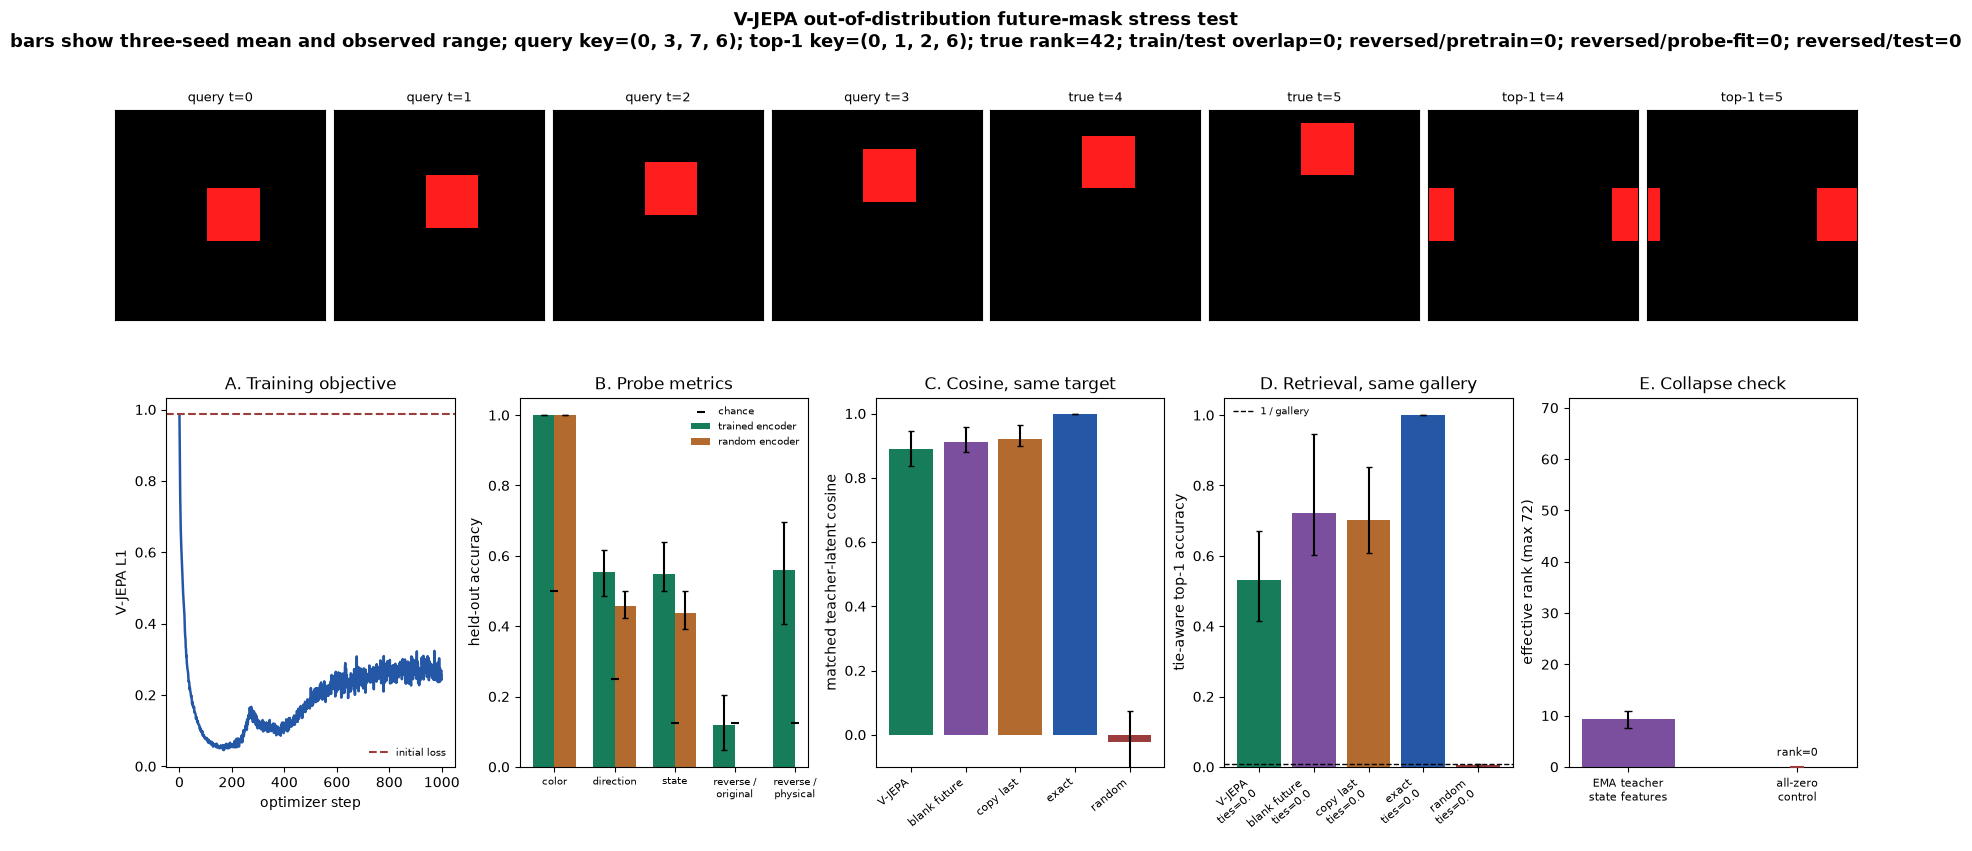

In [21]:
EVAL_SEEDS = (0, 1, 2)
if MAIN:
    validate_learner_pipeline_dependencies(globals(), scratch_reference)

metrics_by_seed = {}
seed_zero_run = None
if MAIN:
    for seed in EVAL_SEEDS:
        train_world, test_world = make_disjoint_worlds(512, 128, seed=seed, device=device)
        model, history = train_small_vjepa(train_world, steps=1_000, batch_size=64, seed=seed)
        metrics = evaluate_small_vjepa(
            model, train_world, test_world, history, seed=seed, probe_train_examples=128
        )
        metrics_by_seed[seed] = metrics
        if seed == 0:
            seed_zero_run = (model, history, metrics, train_world, test_world)
if MAIN:

    intervals = summarize_multiseed(metrics_by_seed)
if MAIN:
    model, history, metrics, train_world, test_world = seed_zero_run

rows = [
    ("final / initial V-JEPA L1", "train_loss_ratio"),
    ("color probe", "color_probe_accuracy"),
    ("direction probe", "direction_probe_accuracy"),
    ("combined-state probe", "state_probe_accuracy"),
    ("random-encoder direction", "random_encoder_direction_accuracy"),
    ("random-encoder state", "random_encoder_state_accuracy"),
    ("reversed / original state", "reversed_original_state_accuracy"),
    ("reversed / physical state", "reversed_physical_state_accuracy"),
    ("future-mask V-JEPA cosine", "predictors.vjepa.teacher_latent_cosine"),
    ("blank-future cosine", "predictors.blank_future.teacher_latent_cosine"),
    ("copy-last-frame cosine", "predictors.copy_last_frame.teacher_latent_cosine"),
    ("exact-dynamics cosine", "predictors.exact_dynamics.teacher_latent_cosine"),
    ("random-predictor cosine", "predictors.random_predictor.teacher_latent_cosine"),
    ("future-mask V-JEPA retrieval", "predictors.vjepa.retrieval_accuracy"),
    ("blank-future retrieval", "predictors.blank_future.retrieval_accuracy"),
    ("copy-last-frame retrieval", "predictors.copy_last_frame.retrieval_accuracy"),
    ("exact-dynamics retrieval", "predictors.exact_dynamics.retrieval_accuracy"),
    ("random-predictor retrieval", "predictors.random_predictor.retrieval_accuracy"),
    ("effective rank / 72", "effective_rank"),
]
table = ["| metric | three-seed mean | observed range |", "|---|---:|---:|"]
if MAIN:
    for label, name in rows:
        interval = intervals[name]
        table.append(f"| {label} | {interval.mean:.3f} | [{interval.minimum:.3f}, {interval.maximum:.3f}] |")
if MAIN:
    display(Markdown("\n".join(table)))

tie_table = ["| method | tied queries mean [range] | maximum tie size [range] |", "|---|---:|---:|"]
if MAIN:
    for label, key in (
        ("future-mask V-JEPA", "vjepa"), ("blank future", "blank_future"),
        ("copy last", "copy_last_frame"), ("exact", "exact_dynamics"), ("random", "random_predictor"),
    ):
        tied = intervals[f"predictors.{key}.tied_queries"]
        maximum = intervals[f"predictors.{key}.max_tie_count"]
        tie_table.append(
            f"| {label} | {tied.mean:.1f} [{tied.minimum:.0f}, {tied.maximum:.0f}] | "
            f"{maximum.mean:.1f} [{maximum.minimum:.0f}, {maximum.maximum:.0f}] |"
        )
if MAIN:
    display(Markdown("\n".join(tie_table)))

audit_table = [
    "| seed | train/test overlap | reversed/pretrain | reversed/probe-fit | reversed/test | collision free |",
    "|---:|---:|---:|---:|---:|:---:|",
]
if MAIN:
    for seed, seed_metrics in metrics_by_seed.items():
        duplicate = seed_metrics.duplicate_audit
        reversal = seed_metrics.reversal_audit
        audit_table.append(
            f"| {seed} | {duplicate.train_test_overlap} | {reversal.reversed_pretraining_overlap} | "
            f"{reversal.reversed_probe_fit_overlap} | {reversal.reversed_test_overlap} | {reversal.collision_free} |"
        )
if MAIN:
    display(Markdown("\n".join(audit_table)))
if MAIN:

    for seed_metrics in metrics_by_seed.values():
        assert seed_metrics.duplicate_audit.is_disjoint
        assert seed_metrics.reversal_audit.collision_free
        assert seed_metrics.effective_rank_max == 72
        assert seed_metrics.predictors["exact_dynamics"].teacher_latent_cosine >= 0.999999
        assert seed_metrics.predictors["exact_dynamics"].retrieval_accuracy == 1.0
if MAIN:

    predicted, target = predict_future_features(model, test_world.videos)
if MAIN:
    retrieval = retrieval_details(predicted, target, test_world.clip_keys, test_world.clip_keys)
if MAIN:
    signature_path = scratch_assets_dir / "vjepa_from_scratch_signature.png"
if MAIN:
    fig = make_signature_figure(history, metrics, test_world, retrieval, intervals)
if MAIN:
    fingerprint_payload = {
        "seed_metrics": asdict(metrics),
        "intervals": {name: asdict(interval) for name, interval in intervals.items()},
    }
if MAIN:
    fig.savefig(
        signature_path,
        dpi=180,
        bbox_inches="tight",
        metadata={
            "EvaluationProtocol": EVALUATION_PROTOCOL_VERSION,
            "EvaluationFingerprint": evaluation_fingerprint(fingerprint_payload),
        },
    )
if MAIN:
    plt.show()

<img src="../../exercises/part2_vjepa/media/vjepa_from_scratch_signature.png" alt="Expected V-JEPA signature result" width="950">

<details open>
<summary>How to interpret the checked result</summary>

- Across seeds 0, 1, and 2, final/initial L1 is `0.388 [0.343, 0.456]`.
- Future-mask V-JEPA reaches cosine `0.889 [0.838, 0.946]` and retrieval `0.531 [0.414, 0.672]`; persistence reaches cosine `0.922 [0.898, 0.964]` and retrieval `0.703 [0.609, 0.852]`.
- Blank-future reaches cosine `0.913 [0.880, 0.959]` and retrieval `0.721 [0.602, 0.945]` despite having no future pixels. This is the strongest warning against interpreting clip retrieval as future prediction.
- Exact dynamics is `1.000` on both metrics. Random-predictor retrieval is `0.005 [0.000, 0.008]`.
- Effective rank is `9.27 [7.61, 10.97]` out of the attainable 72. Every collision count and tied-query count is zero in all checked seeds.
- The training curve verifies optimization of the paper L1 term under spatial tube masking; it does not by itself verify future extrapolation.
- The future-mask V-JEPA bar is an out-of-distribution stress test. Compare it only with controls scored in the same teacher space.
- Blank-future retrieval measures surviving clip identity without any future pixels. High retrieval on this control exposes context carryover; neither teacher cosine nor clip retrieval isolates predictive dynamics.
- Exact dynamics must reach the teacher target exactly. Persistence is the relevant shortcut, not a straw baseline.
- Tie counts are part of every retrieval claim. Zero split collisions do not imply zero representation ties.
- Reversal metrics are admissible only because the canonical-key audit is collision-free against pretraining and probe-fit keys.
- The observed V-JEPA-minus-persistence differences across three seeds are descriptive, not a confidence interval or an aggregate superiority claim.

The lab's conclusion remains negative. A positive follow-up needs to beat persistence and
blank-future controls in a preregistered setting whose targets distinguish futures for matched
contexts; improving these clip-level metrics alone does not establish dynamics.

</details>

Choose tube or future mask, block shape and a query before the play cell; predict retrieval, ties
and control differences.

## Try It Yourself

Switch between the in-distribution spatial tube mask and the out-of-distribution future mask, then
inspect one query, its target pixels, its retrieved clip, true rank, and tie count.

After inspecting a query, compare its last two real frames with the same clip's blank-future and
copy-last-frame controls. None of the teacher-space controls produces a decoded video.

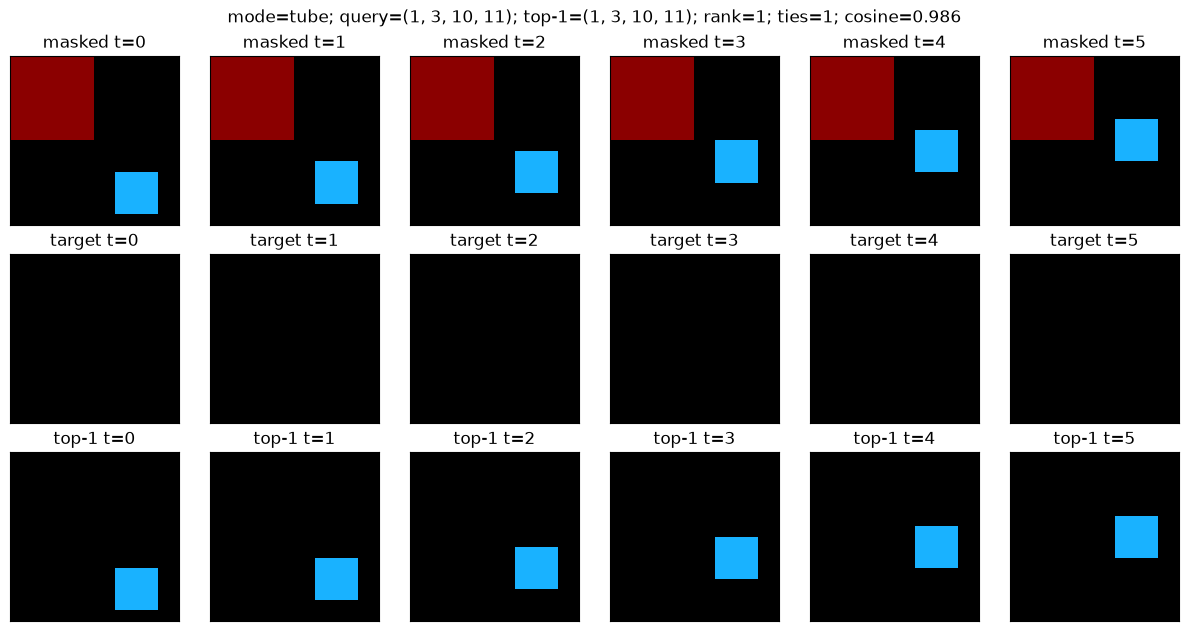

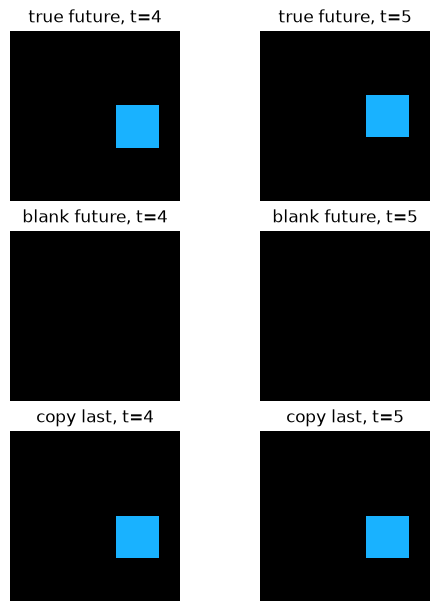

In [22]:
play_mode = "tube"  # "tube" or "future"
play_block = (2, 2)
play_query_index = 7
if MAIN:

    _, play_grid = model.target_encoder.encode_all(test_world.videos[:1])
if MAIN:
    if play_mode == "tube":
        one_mask = sample_spatial_tube_mask(
            1,
            play_grid,
            block_shape=play_block,
            generator=t.Generator().manual_seed(17),
            device=device,
        )
    elif play_mode == "future":
        one_mask = future_prediction_mask(1, play_grid, device=device)
    else:
        raise ValueError("play_mode must be 'tube' or 'future'.")
if MAIN:

    gallery_mask = one_mask.expand(len(test_world.videos), -1).clone()
if MAIN:
    with t.no_grad():
        gallery_prediction, gallery_target, _ = model(test_world.videos, gallery_mask)
if MAIN:
    play_retrieval = retrieval_details(
        gallery_prediction.flatten(1),
        gallery_target.flatten(1),
        test_world.clip_keys,
        test_world.clip_keys,
    )
if MAIN:
    top1_index = int(play_retrieval.top1_indices[play_query_index])
if MAIN:
    pixel_mask = expand_tubelet_mask(one_mask, play_grid, model.context_encoder.tubelet.tubelet_size)[0]
if MAIN:

    fig, axes = plt.subplots(3, 6, figsize=(12, 6.2), constrained_layout=True)
if MAIN:
    for frame_index in range(6):
        axes[0, frame_index].imshow(test_world.videos[play_query_index, frame_index].cpu().permute(1, 2, 0))
        overlay = t.zeros(*pixel_mask[frame_index].shape, 4)
        overlay[..., 0] = 1.0
        overlay[..., 3] = pixel_mask[frame_index].cpu().float() * 0.55
        axes[0, frame_index].imshow(overlay)
        axes[0, frame_index].set_title(f"masked t={frame_index}")

        target_pixels = test_world.videos[play_query_index, frame_index] * pixel_mask[frame_index].to(device)
        axes[1, frame_index].imshow(target_pixels.cpu().permute(1, 2, 0))
        axes[1, frame_index].set_title(f"target t={frame_index}")

        axes[2, frame_index].imshow(test_world.videos[top1_index, frame_index].cpu().permute(1, 2, 0))
        axes[2, frame_index].set_title(f"top-1 t={frame_index}")
if MAIN:

    for axis in axes.flat:
        axis.set_xticks([])
        axis.set_yticks([])
if MAIN:
    fig.suptitle(
        f"mode={play_mode}; query={tuple(test_world.clip_keys[play_query_index].tolist())}; "
        f"top-1={tuple(test_world.clip_keys[top1_index].tolist())}; "
        f"rank={int(play_retrieval.true_ranks[play_query_index])}; "
        f"ties={int(play_retrieval.tie_counts[play_query_index])}; "
        f"cosine={float(play_retrieval.matched_cosines[play_query_index]):.3f}"
    )
if MAIN:
    plt.show()
if MAIN:

    play_controls = {
        "true future": test_world.videos,
        "blank future": blank_future_video(test_world),
        "copy last": copy_last_frame_video(test_world),
    }
if MAIN:
    fig, axes = plt.subplots(3, 2, figsize=(5, 6), constrained_layout=True)
if MAIN:
    for row, (name, video) in enumerate(play_controls.items()):
        for offset, frame in enumerate((4, 5)):
            axes[row, offset].imshow(video[play_query_index, frame].cpu().permute(1, 2, 0))
            axes[row, offset].set_title(f"{name}, t={frame}")
            axes[row, offset].axis("off")
if MAIN:
    plt.show()

<details>
<summary>Interpretation guide</summary>

- Strong tube-mask retrieval with weak future-mask retrieval indicates interpolation without demonstrated extrapolation.
- If persistence matches or wins, keep the negative conclusion; do not rescue the claim with probe accuracy.
- If physical reversal does not outperform original-label reversal, inspect static position shortcuts.
- Inspect ties and wraparound failures rather than averaging them away.

</details>

## Further Research / Anomaly Hunting

A positive follow-up needs a preregistered generated process where the visible context contains a
predictive latent state but a frozen final frame does not. Specify the process, metric, persistence
margin, seed count, and stopping rule before training. That is a new experiment, not evidence
supplied by this notebook.

## Limitations

- This is a tiny one-object toroidal world with four constant velocities, no occlusion, and no interaction.
- Spatial tube pretraining and full-future evaluation use different mask distributions by design.
- The primary method has no variance or covariance penalty; collapse diagnostics observe the result but do not prevent collapse.
- A random encoder can expose appearance and position, so trained-minus-random probe margins remain descriptive.
- The 96-column readout has an attainable rank bound of 72 because its final 24 columns are algebraically dependent.
- Three seeds provide observed ranges only, not uncertainty estimates.
- Teacher final-slice features attend to the context. Blank-future retrieval tests that shortcut; a matched-context counterfactual-future metric is still needed for a positive dynamics claim.
- This notebook does not reproduce V-JEPA scale, multi-block masking, data augmentation, optimizer schedules, or downstream attentive probes.

## Reading

- [V-JEPA paper](https://arxiv.org/abs/2404.08471)
- [Official V-JEPA repository](https://github.com/facebookresearch/jepa)
- [Released V-JEPA training loop](https://github.com/facebookresearch/jepa/blob/main/app/vjepa/train.py)
- [Released 3D mask generator](https://github.com/facebookresearch/jepa/blob/main/src/masks/multiblock3d.py)

# 2️⃣ Frozen world-state controls

> ##### Learning Objectives
>
> - Build the exact shape-video world and map object boxes to latent tokens.
> - Write held-out probe, transition, occlusion and targeted-versus-random patch gates.
> - Inspect the full frozen-model feature, head-training and intervention code inline.

## Inspect the full frozen-model implementation

This is the complete original reference computation, made visible here before the exercise setup.
The typed reports and metric gates below support the original learner exercises; checkpoint feature
extraction, head training, split construction and causal patching remain inspectable functions.
Defining them runs no model or experiment. Later notebook exercises replace their corresponding
functions with your own definitions; the captured reference namespace provides the original
experiment entry points and metadata, without importing hidden taught methods.

In [23]:
"""JEPA and world-model interpretability utilities."""


from dataclasses import dataclass

import torch as t


@dataclass(frozen=True)
class JEPAPredictionReport:
    mean_cosine: float
    mse: float
    predicts_target: bool


@dataclass(frozen=True)
class WorldStateProbeReport:
    accuracy: float
    predicts_state: bool


@dataclass(frozen=True)
class TransitionConsistencyReport:
    mean_cosine: float
    transition_consistent: bool


@dataclass(frozen=True)
class ObjectPermanenceReport:
    visible_mean: float
    occluded_mean: float
    absent_mean: float
    occluded_absent_gap: float
    preserves_occluded_object: bool


@dataclass(frozen=True)
class LossDecreaseReport:
    initial_loss: float
    final_loss: float
    baseline_loss: float
    relative_reduction: float
    beats_baseline: bool
    loss_decreases: bool


@dataclass(frozen=True)
class CollapseDiagnosticsReport:
    finite_features: bool
    feature_std: float
    effective_rank: float
    non_collapsed: bool


@dataclass(frozen=True)
class LatentRolloutReport:
    rollout_loss: float
    copy_baseline_loss: float
    shuffled_action_loss: float
    beats_copy_baseline: bool
    shuffled_action_fails: bool
    rollout_passes: bool


@dataclass(frozen=True)
class CausalLatentPatchReport:
    object_patch_effect: float
    random_patch_effect: float
    patch_random_gap: float
    causal_patch_passes: bool


def _paired_cosine(left: t.Tensor, right: t.Tensor, *, eps: float = 1e-8) -> t.Tensor:
    left_float = left.float()
    right_float = right.float()
    numerator = (left_float * right_float).sum(dim=-1)
    denominator = left_float.norm(dim=-1) * right_float.norm(dim=-1)
    return numerator / denominator.clamp_min(eps)


def jepa_prediction_report(
    predicted_targets: t.Tensor,
    target_embeddings: t.Tensor,
    *,
    min_cosine: float = 0.8,
    max_mse: float = 0.05,
) -> JEPAPredictionReport:
    """Check whether a JEPA-style predictor matches target embeddings."""

    if predicted_targets.shape != target_embeddings.shape:
        raise ValueError("predicted_targets and target_embeddings must match.")
    if predicted_targets.ndim != 2:
        raise ValueError("embeddings must have shape (examples, d_model).")

    mean_cosine = _paired_cosine(predicted_targets, target_embeddings).mean().item()
    mse = (predicted_targets.float() - target_embeddings.float()).pow(2).mean().item()
    return JEPAPredictionReport(
        mean_cosine=mean_cosine,
        mse=mse,
        predicts_target=mean_cosine >= min_cosine and mse <= max_mse,
    )


def world_state_probe_report(
    probe_logits: t.Tensor,
    labels: t.Tensor,
    *,
    min_accuracy: float = 0.9,
) -> WorldStateProbeReport:
    """Check whether a latent world-model state predicts held-out labels."""

    if probe_logits.ndim != 2:
        raise ValueError("probe_logits must have shape (examples, classes).")
    flattened_labels = labels.flatten().long()
    if flattened_labels.numel() != probe_logits.shape[0]:
        raise ValueError("labels must have one value per example.")

    predictions = probe_logits.argmax(dim=-1)
    accuracy = predictions.eq(flattened_labels).float().mean().item()
    return WorldStateProbeReport(
        accuracy=accuracy,
        predicts_state=accuracy >= min_accuracy,
    )


def transition_consistency_report(
    state_embeddings: t.Tensor,
    action_deltas: t.Tensor,
    next_state_embeddings: t.Tensor,
    *,
    min_cosine: float = 0.8,
) -> TransitionConsistencyReport:
    """Check whether state plus action delta predicts the next latent state."""

    if state_embeddings.shape != action_deltas.shape:
        raise ValueError("state_embeddings and action_deltas must match.")
    if state_embeddings.shape != next_state_embeddings.shape:
        raise ValueError("state and next_state embeddings must match.")

    predicted_next = state_embeddings.float() + action_deltas.float()
    mean_cosine = _paired_cosine(predicted_next, next_state_embeddings).mean().item()
    return TransitionConsistencyReport(
        mean_cosine=mean_cosine,
        transition_consistent=mean_cosine >= min_cosine,
    )


def object_permanence_report(
    visible_scores: t.Tensor,
    occluded_scores: t.Tensor,
    absent_scores: t.Tensor,
    *,
    min_occluded_score: float = 0.6,
    min_absent_gap: float = 0.3,
) -> ObjectPermanenceReport:
    """Check whether occluded objects stay represented more than absent objects."""

    visible_mean = visible_scores.float().mean().item()
    occluded_mean = occluded_scores.float().mean().item()
    absent_mean = absent_scores.float().mean().item()
    occluded_absent_gap = occluded_mean - absent_mean
    preserves_occluded_object = (
        occluded_mean >= min_occluded_score
        and occluded_absent_gap >= min_absent_gap
    )
    return ObjectPermanenceReport(
        visible_mean=visible_mean,
        occluded_mean=occluded_mean,
        absent_mean=absent_mean,
        occluded_absent_gap=occluded_absent_gap,
        preserves_occluded_object=preserves_occluded_object,
    )


def loss_decrease_report(
    initial_loss: float,
    final_loss: float,
    baseline_loss: float,
    *,
    min_relative_reduction: float = 0.25,
    max_final_to_baseline: float = 0.8,
) -> LossDecreaseReport:
    """Check whether a trained latent predictor improves over its initial and baseline losses."""

    initial = float(initial_loss)
    final = float(final_loss)
    baseline = float(baseline_loss)
    relative_reduction = (initial - final) / max(initial, 1e-12)
    beats_baseline = final <= baseline * max_final_to_baseline
    return LossDecreaseReport(
        initial_loss=initial,
        final_loss=final,
        baseline_loss=baseline,
        relative_reduction=relative_reduction,
        beats_baseline=beats_baseline,
        loss_decreases=relative_reduction >= min_relative_reduction and beats_baseline,
    )


def collapse_diagnostics_report(
    features: t.Tensor,
    *,
    min_feature_std: float = 0.1,
    min_effective_rank: float = 3.0,
) -> CollapseDiagnosticsReport:
    """Check that a latent representation is finite and not collapsed to one direction."""

    if features.ndim < 2:
        raise ValueError("features must have at least example and feature dimensions.")
    flat = features.float().reshape(features.shape[0], -1)
    finite_features = bool(t.isfinite(flat).all().item())
    feature_std = flat.std().item()
    centered = flat - flat.mean(dim=0, keepdim=True)
    singular_values = t.linalg.svdvals(centered)
    spectrum = singular_values.pow(2)
    probabilities = spectrum / spectrum.sum().clamp_min(1e-12)
    entropy = -(probabilities * probabilities.clamp_min(1e-12).log()).sum()
    effective_rank = entropy.exp().item()
    return CollapseDiagnosticsReport(
        finite_features=finite_features,
        feature_std=feature_std,
        effective_rank=effective_rank,
        non_collapsed=(
            finite_features
            and feature_std >= min_feature_std
            and effective_rank >= min_effective_rank
        ),
    )


def latent_rollout_report(
    rollout_loss: float,
    copy_baseline_loss: float,
    shuffled_action_loss: float,
    *,
    max_rollout_to_copy: float = 0.8,
    max_rollout_to_shuffled: float = 0.8,
) -> LatentRolloutReport:
    """Check that an action-conditioned latent rollout beats copy and shuffled-action baselines."""

    rollout = float(rollout_loss)
    copy = float(copy_baseline_loss)
    shuffled = float(shuffled_action_loss)
    beats_copy = rollout <= copy * max_rollout_to_copy
    shuffled_fails = rollout <= shuffled * max_rollout_to_shuffled
    return LatentRolloutReport(
        rollout_loss=rollout,
        copy_baseline_loss=copy,
        shuffled_action_loss=shuffled,
        beats_copy_baseline=beats_copy,
        shuffled_action_fails=shuffled_fails,
        rollout_passes=beats_copy and shuffled_fails,
    )


def causal_latent_patch_report(
    object_patch_effects: t.Tensor,
    random_patch_effects: t.Tensor,
    *,
    min_object_patch_effect: float = 0.2,
    min_patch_random_gap: float = 0.1,
) -> CausalLatentPatchReport:
    """Compare targeted latent-token patches against same-size random-token patches."""

    if object_patch_effects.numel() == 0 or random_patch_effects.numel() == 0:
        raise ValueError("patch effect tensors must be non-empty.")
    object_effect = object_patch_effects.float().mean().item()
    random_effect = random_patch_effects.float().mean().item()
    gap = object_effect - random_effect
    return CausalLatentPatchReport(
        object_patch_effect=object_effect,
        random_patch_effect=random_effect,
        patch_random_gap=gap,
        causal_patch_passes=(
            object_effect >= min_object_patch_effect and gap >= min_patch_random_gap
        ),
    )

In [24]:
if MAIN:
    # %%
    """Reference solutions for [14.1] JEPA and World-Model Controls."""

import sys
from dataclasses import dataclass
from pathlib import Path

import torch as t
import torch.nn.functional as F

controls_chapter = "chapter14_jepa_world_models"
if MAIN:
    controls_root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / controls_chapter).exists())
if MAIN:
    if str(controls_root_dir) not in sys.path:
        sys.path.append(str(controls_root_dir))

# All original imported metric implementations are visible in the preceding cell.


REAL_VJEPA2_MODEL_ID = "facebook/vjepa2-vitl-fpc64-256"
REAL_VJEPA2_REVISION = "b3c1679b7c34d3255ef3547f27c7b226aefab26f"
VJEPA2_VIDEO_KINDS = (
    "red_square",
    "red_square_shifted",
    "blue_circle",
    "red_square_late_occluded",
    "red_square_absent_occluder",
)
VJEPA2_ACTIONS = (
    (0, 0),
    (8, 0),
    (-8, 0),
    (0, 8),
    (0, -8),
)


def paired_cosine(left: t.Tensor, right: t.Tensor, *, eps: float = 1e-8) -> t.Tensor:
    """Return row-wise cosine similarities for two equally-shaped embedding batches."""

    if left.shape != right.shape:
        raise ValueError("left and right must have the same shape.")
    if left.ndim < 2:
        raise ValueError("left and right must have shape (..., d_model).")
    left_float = left.float()
    right_float = right.float()
    numerator = (left_float * right_float).sum(dim=-1)
    denominator = left_float.norm(dim=-1) * right_float.norm(dim=-1)
    return numerator / denominator.clamp_min(eps)


@dataclass(frozen=True)
class SyntheticVJEPAWorldBatch:
    videos: t.Tensor
    labels: t.Tensor
    x_buckets: t.Tensor
    action_ids: t.Tensor
    next_videos: t.Tensor
    occluded_videos: t.Tensor
    absent_videos: t.Tensor
    bboxes: list[tuple[int, int, int, int]]


# %%
def jepa_prediction_smoke_test() -> dict:
    target_embeddings = t.tensor([[1.0, 0.0], [0.0, 1.0]])
    predicted_targets = target_embeddings.clone()
    return jepa_prediction_report(
        predicted_targets,
        target_embeddings,
        min_cosine=0.99,
        max_mse=0.01,
    ).__dict__


def state_probe_smoke_test() -> dict:
    probe_logits = t.tensor([[3.0, 0.0], [0.0, 4.0], [2.0, 1.0]])
    labels = t.tensor([0, 1, 0])
    return world_state_probe_report(
        probe_logits,
        labels,
        min_accuracy=1.0,
    ).__dict__


def transition_smoke_test() -> dict:
    state_embeddings = t.tensor([[0.0, 0.0], [1.0, 1.0]])
    action_deltas = t.tensor([[1.0, 0.0], [0.0, 1.0]])
    next_state_embeddings = t.tensor([[1.0, 0.0], [1.0, 2.0]])
    return transition_consistency_report(
        state_embeddings,
        action_deltas,
        next_state_embeddings,
        min_cosine=0.99,
    ).__dict__


def object_permanence_smoke_test() -> dict:
    return object_permanence_report(
        visible_scores=t.tensor([0.9, 0.8]),
        occluded_scores=t.tensor([0.75, 0.7]),
        absent_scores=t.tensor([0.1, 0.2]),
        min_occluded_score=0.6,
        min_absent_gap=0.4,
    ).__dict__


def collapse_diagnostics_smoke_test() -> dict:
    structured_features = t.tensor(
        [
            [1.0, 0.0, 0.0, 0.0],
            [0.0, 1.0, 0.0, 0.0],
            [0.0, 0.0, 1.0, 0.0],
            [0.0, 0.0, 0.0, 1.0],
            [1.0, 1.0, 0.0, 0.0],
            [0.0, 1.0, 1.0, 0.0],
        ]
    )
    collapsed_features = t.ones(6, 4)
    structured = collapse_diagnostics_report(
        structured_features,
        min_feature_std=0.1,
        min_effective_rank=2.0,
    )
    collapsed = collapse_diagnostics_report(
        collapsed_features,
        min_feature_std=0.1,
        min_effective_rank=2.0,
    )
    return {
        "structured": structured.__dict__,
        "collapsed": collapsed.__dict__,
        "collapsed_control_rejected": not collapsed.non_collapsed,
    }


def state_probe_control_smoke_test() -> dict:
    probe_logits = t.tensor(
        [
            [4.0, 0.0],
            [3.0, 0.0],
            [0.0, 4.0],
            [0.0, 3.0],
        ]
    )
    labels = t.tensor([0, 0, 1, 1])
    shuffled_labels = t.tensor([1, 1, 0, 0])
    probe = world_state_probe_report(probe_logits, labels, min_accuracy=0.9)
    shuffled = world_state_probe_report(
        probe_logits,
        shuffled_labels,
        min_accuracy=0.9,
    )
    return {
        "probe": probe.__dict__,
        "shuffled": shuffled.__dict__,
        "shuffled_control_rejected": not shuffled.predicts_state,
        "accuracy_margin": probe.accuracy - shuffled.accuracy,
    }


def rollout_control_smoke_test() -> dict:
    rollout = latent_rollout_report(
        rollout_loss=0.10,
        copy_baseline_loss=1.00,
        shuffled_action_loss=0.90,
        max_rollout_to_copy=0.8,
        max_rollout_to_shuffled=0.8,
    )
    failed = latent_rollout_report(
        rollout_loss=0.75,
        copy_baseline_loss=0.80,
        shuffled_action_loss=0.70,
        max_rollout_to_copy=0.8,
        max_rollout_to_shuffled=0.8,
    )
    return {
        "rollout": rollout.__dict__,
        "failed_control": failed.__dict__,
        "copy_and_shuffled_controls_rejected": not failed.rollout_passes,
    }


def object_permanence_control_smoke_test() -> dict:
    preserved = object_permanence_report(
        visible_scores=t.tensor([0.95, 0.9]),
        occluded_scores=t.tensor([0.8, 0.75]),
        absent_scores=t.tensor([0.15, 0.2]),
        min_occluded_score=0.6,
        min_absent_gap=0.4,
    )
    absent_like = object_permanence_report(
        visible_scores=t.tensor([0.95, 0.9]),
        occluded_scores=t.tensor([0.52, 0.48]),
        absent_scores=t.tensor([0.46, 0.44]),
        min_occluded_score=0.6,
        min_absent_gap=0.4,
    )
    different_object = object_permanence_report(
        visible_scores=t.tensor([0.95, 0.9]),
        occluded_scores=t.tensor([0.78, 0.76]),
        absent_scores=t.tensor([0.72, 0.7]),
        min_occluded_score=0.6,
        min_absent_gap=0.4,
    )
    return {
        "preserved": preserved.__dict__,
        "absent_like": absent_like.__dict__,
        "different_object": different_object.__dict__,
        "absent_like_rejected": not absent_like.preserves_occluded_object,
        "different_object_rejected": not different_object.preserves_occluded_object,
    }


def _synthetic_vjepa_video(kind: str, *, frames: int = 8, size: int = 96) -> t.Tensor:
    """Create a deterministic normalized video tensor with shape (frames, channels, height, width)."""

    video_frames = []
    yy, xx = t.meshgrid(t.arange(size), t.arange(size), indexing="ij")
    for frame_index in range(frames):
        image = t.zeros(3, size, size)
        if kind in {"red_square", "red_square_late_occluded"}:
            x0 = 8 + frame_index * 4
            y0 = 32
            image[0, y0 : y0 + 24, x0 : x0 + 24] = 1.0
        elif kind == "red_square_shifted":
            x0 = 10 + frame_index * 4
            y0 = 34
            image[0, y0 : y0 + 24, x0 : x0 + 24] = 1.0
        elif kind == "blue_circle":
            center_x = 48
            center_y = 24 + frame_index * 4
            mask = (xx - center_x).pow(2) + (yy - center_y).pow(2) <= 12**2
            image[2, mask] = 1.0
        elif kind == "red_square_absent_occluder":
            pass
        else:
            raise ValueError(f"Unknown synthetic V-JEPA video kind: {kind}")
        if kind in {"red_square_late_occluded", "red_square_absent_occluder"} and frame_index >= 4:
            image[:, 28:62, 4:66] = 0.5
        video_frames.append((image - 0.5) / 0.5)
    return t.stack(video_frames)


def make_world_video(
    object_kind: str,
    x: int,
    y: int,
    *,
    dx: int = 0,
    dy: int = 0,
    frames: int = 8,
    size: int = 96,
    occlude_late: bool = False,
    absent: bool = False,
) -> t.Tensor:
    """Create a deterministic video for one labeled object/action state."""

    yy, xx = t.meshgrid(t.arange(size), t.arange(size), indexing="ij")
    video_frames = []
    for frame_index in range(frames):
        image = t.zeros(3, size, size)
        if not absent:
            progress = frame_index / max(frames - 1, 1)
            x0 = int(x + dx * progress)
            y0 = int(y + dy * progress)
            if object_kind == "red_square":
                image[0, y0 : y0 + 20, x0 : x0 + 20] = 1.0
            elif object_kind == "blue_circle":
                center_x = x0 + 10
                center_y = y0 + 10
                mask = (xx - center_x).pow(2) + (yy - center_y).pow(2) <= 10**2
                image[2, mask] = 1.0
            else:
                raise ValueError(f"Unknown object kind: {object_kind}")
        if occlude_late and frame_index >= frames // 2:
            image[:, max(0, y - 4) : min(size, y + 28), max(0, x - 4) : min(size, x + 28)] = 0.5
        video_frames.append((image - 0.5) / 0.5)
    return t.stack(video_frames)


def _build_synthetic_vjepa_world_batch(*, size: int = 96) -> SyntheticVJEPAWorldBatch:
    """Build a balanced generated video dataset with exact state/action labels."""

    x_positions = [8, 20, 32, 44, 56]
    y_positions = [12, 28, 44, 60]
    videos = []
    labels = []
    x_buckets = []
    action_ids = []
    next_videos = []
    occluded_videos = []
    absent_videos = []
    bboxes: list[tuple[int, int, int, int]] = []
    for object_kind, label in (("red_square", 0), ("blue_circle", 1)):
        for x_bucket, x in enumerate(x_positions):
            for y in y_positions:
                for action_id, (dx, dy) in enumerate(VJEPA2_ACTIONS):
                    next_x = max(4, min(size - 24, x + dx))
                    next_y = max(4, min(size - 24, y + dy))
                    videos.append(make_world_video(object_kind, x, y, size=size))
                    labels.append(label)
                    x_buckets.append(x_bucket)
                    action_ids.append(action_id)
                    next_videos.append(make_world_video(object_kind, next_x, next_y, size=size))
                    occluded_videos.append(
                        make_world_video(object_kind, x, y, size=size, occlude_late=True)
                    )
                    absent_videos.append(
                        make_world_video(
                            object_kind,
                            x,
                            y,
                            size=size,
                            occlude_late=True,
                            absent=True,
                        )
                    )
                    bboxes.append((x, y, x + 20, y + 20))
    return SyntheticVJEPAWorldBatch(
        videos=t.stack(videos),
        labels=t.tensor(labels, dtype=t.long),
        x_buckets=t.tensor(x_buckets, dtype=t.long),
        action_ids=t.tensor(action_ids, dtype=t.long),
        next_videos=t.stack(next_videos),
        occluded_videos=t.stack(occluded_videos),
        absent_videos=t.stack(absent_videos),
        bboxes=bboxes,
    )


def bbox_to_vjepa_tokens(
    bbox: tuple[int, int, int, int],
    *,
    image_size: int = 96,
    token_grid: int = 12,
    pad: int = 4,
) -> list[int]:
    """Map an image-space object box to the corresponding 12x12 V-JEPA token grid."""

    x0, y0, x1, y1 = bbox
    cell = image_size / token_grid
    tokens = []
    for gy in range(token_grid):
        for gx in range(token_grid):
            cx = (gx + 0.5) * cell
            cy = (gy + 0.5) * cell
            if x0 - pad <= cx <= x1 + pad and y0 - pad <= cy <= y1 + pad:
                tokens.append(gy * token_grid + gx)
    return tokens or [token_grid * token_grid // 2]


def _extract_vjepa2_latents(
    model: t.nn.Module,
    videos: t.Tensor,
    *,
    device: t.device,
    batch_size: int = 16,
) -> t.Tensor:
    """Extract frozen V-JEPA 2 encoder latents for a generated video batch."""

    outputs = []
    for start in range(0, videos.shape[0], batch_size):
        batch = videos[start : start + batch_size].to(device=device, dtype=t.float16)
        with t.inference_mode():
            output = model(pixel_values_videos=batch, skip_predictor=True)
        outputs.append(output.last_hidden_state.detach().float().cpu())
    return t.cat(outputs, dim=0)


def _stratified_split(labels: t.Tensor, *, train_per_label: int = 75) -> tuple[t.Tensor, t.Tensor]:
    """Return deterministic balanced train/test indices."""

    train_indices = []
    test_indices = []
    for label in sorted(labels.unique().tolist()):
        group = t.nonzero(labels == label, as_tuple=False).flatten()
        generator = t.Generator().manual_seed(int(label))
        shuffled = group[t.randperm(group.numel(), generator=generator)]
        train_indices.append(shuffled[:train_per_label])
        test_indices.append(shuffled[train_per_label:])
    return t.cat(train_indices), t.cat(test_indices)


def _nearest_neighbor_accuracy(
    train_features: t.Tensor,
    train_labels: t.Tensor,
    test_features: t.Tensor,
    test_labels: t.Tensor,
) -> float:
    """Classify held-out features with nearest train feature under cosine distance."""

    train_norm = F.normalize(train_features.float(), dim=-1)
    test_norm = F.normalize(test_features.float(), dim=-1)
    nearest = (test_norm @ train_norm.T).argmax(dim=-1)
    predictions = train_labels[nearest]
    return predictions.eq(test_labels).float().mean().item()


def _train_linear_classifier(
    train_features: t.Tensor,
    train_labels: t.Tensor,
    test_features: t.Tensor,
    test_labels: t.Tensor,
    *,
    classes: int,
    steps: int = 240,
    lr: float = 2e-2,
) -> tuple[t.nn.Linear, float]:
    """Train a small held-out probe on frozen latents."""

    probe = t.nn.Linear(train_features.shape[-1], classes, device=train_features.device)
    optimizer = t.optim.AdamW(probe.parameters(), lr=lr, weight_decay=1e-3)
    for _ in range(steps):
        loss = F.cross_entropy(probe(train_features), train_labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    with t.inference_mode():
        accuracy = probe(test_features).argmax(dim=-1).eq(test_labels).float().mean().item()
    return probe, accuracy


def _train_mlp_predictor(
    train_inputs: t.Tensor,
    train_targets: t.Tensor,
    test_inputs: t.Tensor,
    test_targets: t.Tensor,
    *,
    action_count: int | None = None,
    train_actions: t.Tensor | None = None,
    test_actions: t.Tensor | None = None,
    steps: int = 500,
) -> tuple[t.nn.Module, float, float]:
    """Train a small MLP predictor and return initial/final held-out MSE."""

    input_dim = train_inputs.shape[-1] + (action_count or 0)
    predictor = t.nn.Sequential(
        t.nn.Linear(input_dim, 256, device=train_inputs.device),
        t.nn.GELU(),
        t.nn.Linear(256, train_targets.shape[-1], device=train_inputs.device),
    )
    optimizer = t.optim.AdamW(predictor.parameters(), lr=2e-3, weight_decay=1e-4)

    def _concat_actions(features: t.Tensor, actions: t.Tensor | None) -> t.Tensor:
        if action_count is None:
            return features
        if actions is None:
            raise ValueError("actions are required when action_count is set.")
        action_features = F.one_hot(actions, num_classes=action_count).float()
        return t.cat([features, action_features], dim=-1)

    train_x = _concat_actions(train_inputs, train_actions)
    test_x = _concat_actions(test_inputs, test_actions)
    with t.inference_mode():
        initial_loss = F.mse_loss(predictor(test_x), test_targets).item()
    for _ in range(steps):
        loss = F.mse_loss(predictor(train_x), train_targets)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    with t.inference_mode():
        final_loss = F.mse_loss(predictor(test_x), test_targets).item()
    return predictor, initial_loss, final_loss


def vjepa2_feature_extraction_preflight(max_vram_gb: float = 24.0) -> dict:
    """Run pinned V-JEPA 2 ViT-L feature extraction on deterministic synthetic videos."""

    if not t.cuda.is_available():
        raise RuntimeError("14.1 V-JEPA 2 feature extraction preflight requires CUDA.")

    from huggingface_hub import snapshot_download
    from transformers import VJEPA2Model

    device = t.device("cuda")
    t.cuda.reset_peak_memory_stats()
    local_snapshot = snapshot_download(
        REAL_VJEPA2_MODEL_ID,
        revision=REAL_VJEPA2_REVISION,
        allow_patterns=[
            "config.json",
            "model.safetensors",
        ],
    )
    model = VJEPA2Model.from_pretrained(
        local_snapshot,
        dtype=t.float16,
    ).to(device)
    model.eval()
    videos = t.stack([_synthetic_vjepa_video(kind) for kind in VJEPA2_VIDEO_KINDS]).to(
        device=device,
        dtype=t.float16,
    )
    with t.inference_mode():
        output = model(pixel_values_videos=videos, skip_predictor=True)
    features = output.last_hidden_state.detach().float()
    pooled = F.normalize(features.mean(dim=1), dim=-1)
    cosine = pooled @ pooled.T
    same_object_cosine = cosine[0, 1].item()
    different_object_cosine = t.stack([cosine[0, 2], cosine[1, 2]]).max().item()
    same_object_margin = same_object_cosine - different_object_cosine
    late_occluded_cosine = cosine[0, 3].item()
    absent_occluder_cosine = cosine[0, 4].item()
    occluded_vs_absent_gap = late_occluded_cosine - absent_occluder_cosine
    occluded_vs_blue_gap = late_occluded_cosine - cosine[0, 2].item()
    permanence = object_permanence_report(
        visible_scores=t.tensor([same_object_cosine]),
        occluded_scores=t.tensor([late_occluded_cosine]),
        absent_scores=t.tensor([absent_occluder_cosine]),
        min_occluded_score=0.9,
        min_absent_gap=0.2,
    )
    finite_features = bool(t.isfinite(features).all().item())
    feature_std = features.std().item()
    feature_shape = list(features.shape)
    t.cuda.synchronize()
    peak_vram_gb = t.cuda.max_memory_allocated() / 1024**3

    del output, features, pooled, cosine, videos, model
    t.cuda.empty_cache()

    preflight_passed = (
        finite_features
        and feature_std > 0.1
        and same_object_margin >= 0.03
        and permanence.preserves_occluded_object
        and occluded_vs_blue_gap >= 0.03
        and peak_vram_gb <= max_vram_gb
    )
    return {
        "cuda_available": True,
        "model_id": REAL_VJEPA2_MODEL_ID,
        "revision": REAL_VJEPA2_REVISION,
        "local_snapshot": str(local_snapshot),
        "claim_scope": "pinned_vjepa2_vitl_synthetic_video_feature_extraction_preflight",
        "video_kinds": list(VJEPA2_VIDEO_KINDS),
        "video_count": len(VJEPA2_VIDEO_KINDS),
        "frames_per_video": 8,
        "input_size": 96,
        "feature_shape": feature_shape,
        "tokens_per_video": feature_shape[1],
        "hidden_size": feature_shape[2],
        "finite_features": finite_features,
        "feature_std": feature_std,
        "same_object_cosine": same_object_cosine,
        "different_object_cosine": different_object_cosine,
        "same_object_margin": same_object_margin,
        "same_object_beats_different_object": same_object_margin >= 0.03,
        "late_occluded_cosine": late_occluded_cosine,
        "absent_occluder_cosine": absent_occluder_cosine,
        "occluded_vs_absent_gap": occluded_vs_absent_gap,
        "occluded_vs_blue_gap": occluded_vs_blue_gap,
        "synthetic_occlusion_permanence": permanence.__dict__,
        "synthetic_occlusion_permanence_passed": permanence.preserves_occluded_object
        and occluded_vs_blue_gap >= 0.03,
        "peak_vram_gb": peak_vram_gb,
        "within_vram_budget": peak_vram_gb <= max_vram_gb,
        "preflight_passed": preflight_passed,
    }


def vjepa2_world_model_control_preflight(
    max_vram_gb: float = 24.0,
    *,
    include_visuals: bool = False,
) -> dict:
    """Run frozen V-JEPA 2 latent probes, rollout heads, and causal patch controls."""

    if not t.cuda.is_available():
        raise RuntimeError("14.1 V-JEPA 2 world-model control preflight requires CUDA.")

    from huggingface_hub import snapshot_download
    from transformers import VJEPA2Model

    device = t.device("cuda")
    t.manual_seed(0)
    if t.cuda.is_available():
        t.cuda.manual_seed_all(0)
    t.cuda.reset_peak_memory_stats()
    local_snapshot = snapshot_download(
        REAL_VJEPA2_MODEL_ID,
        revision=REAL_VJEPA2_REVISION,
        allow_patterns=[
            "config.json",
            "model.safetensors",
        ],
    )
    model = VJEPA2Model.from_pretrained(local_snapshot, dtype=t.float16).to(device)
    model.eval()

    batch = _build_synthetic_vjepa_world_batch()
    features = _extract_vjepa2_latents(model, batch.videos, device=device)
    next_features = _extract_vjepa2_latents(model, batch.next_videos, device=device)
    occluded_features = _extract_vjepa2_latents(model, batch.occluded_videos, device=device)
    absent_features = _extract_vjepa2_latents(model, batch.absent_videos, device=device)
    del model

    raw_pooled = features.mean(dim=1)
    pooled = F.normalize(raw_pooled, dim=-1)
    next_pooled = F.normalize(next_features.mean(dim=1), dim=-1)
    occluded_pooled = F.normalize(occluded_features.mean(dim=1), dim=-1)
    absent_pooled = F.normalize(absent_features.mean(dim=1), dim=-1)
    train_idx_cpu, test_idx_cpu = _stratified_split(batch.labels)
    train_idx = train_idx_cpu.to(device)
    test_idx = test_idx_cpu.to(device)

    collapse = collapse_diagnostics_report(
        raw_pooled,
        min_feature_std=0.5,
        min_effective_rank=1.5,
    )

    pooled_gpu = pooled.to(device)
    next_pooled_gpu = next_pooled.to(device)
    occluded_pooled_gpu = occluded_pooled.to(device)
    absent_pooled_gpu = absent_pooled.to(device)
    labels = batch.labels.to(device)
    action_ids = batch.action_ids.to(device)
    x_buckets = batch.x_buckets.to(device)

    state_probe, state_probe_accuracy = _train_linear_classifier(
        pooled_gpu[train_idx],
        labels[train_idx],
        pooled_gpu[test_idx],
        labels[test_idx],
        classes=2,
    )
    _ = state_probe
    state_probe_knn_accuracy = _nearest_neighbor_accuracy(
        pooled_gpu[train_idx],
        labels[train_idx],
        pooled_gpu[test_idx],
        labels[test_idx],
    )
    shuffled_train_labels = labels[train_idx][t.randperm(train_idx.numel(), device=device)]
    state_probe_shuffled_knn_accuracy = _nearest_neighbor_accuracy(
        pooled_gpu[train_idx],
        shuffled_train_labels,
        pooled_gpu[test_idx],
        labels[test_idx],
    )
    state_probe_margin = state_probe_knn_accuracy - state_probe_shuffled_knn_accuracy

    masked_predictor, masked_initial_loss, masked_final_loss = _train_mlp_predictor(
        occluded_pooled_gpu[train_idx],
        pooled_gpu[train_idx],
        occluded_pooled_gpu[test_idx],
        pooled_gpu[test_idx],
        steps=500,
    )
    with t.inference_mode():
        masked_copy_loss = F.mse_loss(
            occluded_pooled_gpu[test_idx],
            pooled_gpu[test_idx],
        ).item()
    masked_report = loss_decrease_report(
        masked_initial_loss,
        masked_final_loss,
        masked_copy_loss,
        min_relative_reduction=0.5,
        max_final_to_baseline=0.8,
    )

    transition_head, transition_initial_loss, transition_final_loss = _train_mlp_predictor(
        pooled_gpu[train_idx],
        next_pooled_gpu[train_idx],
        pooled_gpu[test_idx],
        next_pooled_gpu[test_idx],
        action_count=len(VJEPA2_ACTIONS),
        train_actions=action_ids[train_idx],
        test_actions=action_ids[test_idx],
        steps=700,
    )
    with t.inference_mode():
        transition_copy_loss = F.mse_loss(
            pooled_gpu[test_idx],
            next_pooled_gpu[test_idx],
        ).item()
        shuffled_test_actions = action_ids[test_idx][
            t.randperm(test_idx.numel(), device=device)
        ]
        shuffled_inputs = t.cat(
            [
                pooled_gpu[test_idx],
                F.one_hot(shuffled_test_actions, num_classes=len(VJEPA2_ACTIONS)).float(),
            ],
            dim=-1,
        )
        transition_shuffled_loss = F.mse_loss(
            transition_head(shuffled_inputs),
            next_pooled_gpu[test_idx],
        ).item()
    rollout = latent_rollout_report(
        transition_final_loss,
        transition_copy_loss,
        transition_shuffled_loss,
        max_rollout_to_copy=0.8,
        max_rollout_to_shuffled=0.8,
    )

    visible_occluded_cosine = (pooled_gpu * occluded_pooled_gpu).sum(dim=-1)
    visible_absent_cosine = (pooled_gpu * absent_pooled_gpu).sum(dim=-1)
    visible_self_cosine = (pooled_gpu * pooled_gpu).sum(dim=-1)
    permanence = object_permanence_report(
        visible_scores=visible_self_cosine,
        occluded_scores=visible_occluded_cosine,
        absent_scores=visible_absent_cosine,
        min_occluded_score=0.85,
        min_absent_gap=0.05,
    )

    feature_tokens = features.to(device)
    local_position_features = t.stack(
        [
            feature_tokens[index, bbox_to_vjepa_tokens(bbox)].mean(dim=0)
            for index, bbox in enumerate(batch.bboxes)
        ]
    )
    position_probe, position_probe_accuracy = _train_linear_classifier(
        local_position_features[train_idx],
        x_buckets[train_idx],
        local_position_features[test_idx],
        x_buckets[test_idx],
        classes=5,
        steps=320,
    )
    object_patch_effects = []
    random_patch_effects = []
    for object_label in (0, 1):
        for y_position in (12, 28, 44, 60):
            source_candidates = [
                index
                for index, bbox in enumerate(batch.bboxes)
                if batch.labels[index].item() == object_label
                and bbox[0] == 56
                and bbox[1] == y_position
            ]
            target_candidates = [
                index
                for index, bbox in enumerate(batch.bboxes)
                if batch.labels[index].item() == object_label
                and bbox[0] == 8
                and bbox[1] == y_position
            ]
            for source_index, target_index in zip(source_candidates[:2], target_candidates[:2]):
                source_tokens = bbox_to_vjepa_tokens(batch.bboxes[source_index])
                target_tokens = bbox_to_vjepa_tokens(batch.bboxes[target_index])
                token_count = min(len(source_tokens), len(target_tokens))
                source_tokens = source_tokens[:token_count]
                target_tokens = target_tokens[:token_count]
                patched = feature_tokens[target_index].clone()
                patched[target_tokens] = feature_tokens[source_index, source_tokens]
                random_target_tokens = t.randperm(feature_tokens.shape[1], device=device)[
                    :token_count
                ]
                random_source_tokens = t.randperm(feature_tokens.shape[1], device=device)[
                    :token_count
                ]
                random_patched = feature_tokens[target_index].clone()
                random_patched[random_target_tokens] = feature_tokens[
                    source_index,
                    random_source_tokens,
                ]
                with t.inference_mode():
                    base_source_x_prob = F.softmax(
                        position_probe(
                            feature_tokens[target_index, target_tokens]
                            .mean(dim=0, keepdim=True)
                        ),
                        dim=-1,
                    )[0, 4]
                    object_source_x_prob = F.softmax(
                        position_probe(patched[target_tokens].mean(dim=0, keepdim=True)),
                        dim=-1,
                    )[0, 4]
                    random_source_x_prob = F.softmax(
                        position_probe(
                            random_patched[target_tokens].mean(dim=0, keepdim=True)
                        ),
                        dim=-1,
                    )[0, 4]
                object_patch_effects.append(object_source_x_prob - base_source_x_prob)
                random_patch_effects.append(random_source_x_prob - base_source_x_prob)
    patching = causal_latent_patch_report(
        t.stack(object_patch_effects),
        t.stack(random_patch_effects),
        min_object_patch_effect=0.5,
        min_patch_random_gap=0.4,
    )

    t.cuda.synchronize()
    peak_vram_gb = t.cuda.max_memory_allocated() / 1024**3
    within_vram_budget = peak_vram_gb <= max_vram_gb
    preflight_passed = (
        collapse.non_collapsed
        and masked_report.loss_decreases
        and state_probe_accuracy >= 0.8
        and state_probe_margin >= 0.2
        and rollout.rollout_passes
        and permanence.preserves_occluded_object
        and position_probe_accuracy >= 0.7
        and patching.causal_patch_passes
        and within_vram_budget
    )

    visual_payload = None
    if include_visuals:
        frame_indices = t.tensor([0, 3, 4, 7])
        visual_cases = []
        for case_id, index in (("red_square_right", 1), ("blue_circle_right", 101)):
            visual_cases.append(
                {
                    "case_id": case_id,
                    "index": index,
                    "label": int(batch.labels[index].item()),
                    "x_bucket": int(batch.x_buckets[index].item()),
                    "action_id": int(batch.action_ids[index].item()),
                    "action": VJEPA2_ACTIONS[int(batch.action_ids[index].item())],
                    "bbox": batch.bboxes[index],
                    "frame_indices": frame_indices.tolist(),
                    "visible_frames": batch.videos[index, frame_indices].clone(),
                    "next_frames": batch.next_videos[index, frame_indices].clone(),
                    "occluded_frames": batch.occluded_videos[index, frame_indices].clone(),
                    "absent_frames": batch.absent_videos[index, frame_indices].clone(),
                }
            )
        visual_payload = {
            "cases": visual_cases,
            "pooled_features": pooled.clone(),
            "labels": batch.labels.clone(),
            "x_buckets": batch.x_buckets.clone(),
            "action_ids": batch.action_ids.clone(),
            "object_patch_effects": t.stack(object_patch_effects).detach().cpu(),
            "random_patch_effects": t.stack(random_patch_effects).detach().cpu(),
        }

    del (
        features,
        next_features,
        occluded_features,
        absent_features,
        feature_tokens,
        pooled_gpu,
        next_pooled_gpu,
        occluded_pooled_gpu,
        absent_pooled_gpu,
        masked_predictor,
        transition_head,
        position_probe,
    )
    t.cuda.empty_cache()

    result = {
        "cuda_available": True,
        "model_id": REAL_VJEPA2_MODEL_ID,
        "revision": REAL_VJEPA2_REVISION,
        "claim_scope": "pinned_vjepa2_vitl_frozen_latent_world_model_controls",
        "video_count": int(batch.videos.shape[0]),
        "frames_per_video": int(batch.videos.shape[1]),
        "input_size": 96,
        "feature_shape": list(raw_pooled.shape),
        "token_feature_shape": [int(v) for v in [batch.videos.shape[0], 144, 1024]],
        "collapse_diagnostics": collapse.__dict__,
        "vjepa2_non_collapsed": collapse.non_collapsed,
        "masked_prediction": masked_report.__dict__,
        "masked_prediction_loss_reduction": masked_report.relative_reduction,
        "masked_prediction_final_loss": masked_report.final_loss,
        "masked_prediction_copy_baseline_loss": masked_report.baseline_loss,
        "masked_prediction_passed": masked_report.loss_decreases,
        "state_probe_accuracy": state_probe_accuracy,
        "state_probe_knn_accuracy": state_probe_knn_accuracy,
        "state_probe_shuffled_knn_accuracy": state_probe_shuffled_knn_accuracy,
        "state_probe_margin_over_random": state_probe_margin,
        "state_probe_beats_random_baseline": state_probe_margin >= 0.2,
        "latent_rollout": rollout.__dict__,
        "latent_rollout_initial_loss": transition_initial_loss,
        "latent_rollout_final_loss": rollout.rollout_loss,
        "latent_rollout_copy_baseline_loss": rollout.copy_baseline_loss,
        "latent_rollout_shuffled_action_loss": rollout.shuffled_action_loss,
        "latent_rollout_passed": rollout.rollout_passes,
        "shuffled_action_baseline_failed": rollout.shuffled_action_fails,
        "object_permanence": permanence.__dict__,
        "real_latent_object_permanence_passed": permanence.preserves_occluded_object,
        "position_probe_accuracy": position_probe_accuracy,
        "causal_latent_patching": patching.__dict__,
        "causal_latent_patching_passed": patching.causal_patch_passes,
        "peak_vram_gb": peak_vram_gb,
        "within_vram_budget": within_vram_budget,
        "preflight_passed": preflight_passed,
    }
    if visual_payload is not None:
        result["visual_payload"] = visual_payload
    return result


def run_vjepa2_world_model_signature_result(
    max_vram_gb: float = 24.0,
) -> dict:
    """Run the pinned world-model controls and retain learner-facing evidence."""

    return vjepa2_world_model_control_preflight(
        max_vram_gb=max_vram_gb,
        include_visuals=True,
    )


def controls_reference_run_smoke_test(cpu: bool = True) -> dict:
    _ = cpu
    return {
        "jepa_prediction": jepa_prediction_smoke_test(),
        "collapse": collapse_diagnostics_smoke_test(),
        "state_probe": state_probe_smoke_test(),
        "state_probe_control": state_probe_control_smoke_test(),
        "transition": transition_smoke_test(),
        "rollout_control": rollout_control_smoke_test(),
        "object_permanence": object_permanence_smoke_test(),
        "object_permanence_control": object_permanence_control_smoke_test(),
    }


def controls_reference_run_gpu_test(max_vram_gb: float = 24.0) -> dict:
    if not t.cuda.is_available():
        raise RuntimeError("14.1 GPU verification requires CUDA.")

    device = t.device("cuda")
    t.cuda.reset_peak_memory_stats()
    target_embeddings = t.tensor([[1.0, 0.0], [0.0, 1.0]], device=device)
    prediction = jepa_prediction_report(
        target_embeddings.clone(),
        target_embeddings,
        min_cosine=0.99,
        max_mse=0.01,
    )
    transition = transition_consistency_report(
        t.tensor([[0.0, 0.0], [1.0, 1.0]], device=device),
        t.tensor([[1.0, 0.0], [0.0, 1.0]], device=device),
        t.tensor([[1.0, 0.0], [1.0, 2.0]], device=device),
        min_cosine=0.99,
    )
    t.cuda.synchronize()
    synthetic_peak_vram_gb = t.cuda.max_memory_allocated() / 1024**3
    vjepa2 = vjepa2_feature_extraction_preflight(max_vram_gb=max_vram_gb)
    world_controls = vjepa2_world_model_control_preflight(max_vram_gb=max_vram_gb)
    peak_vram_gb = max(
        synthetic_peak_vram_gb,
        vjepa2["peak_vram_gb"],
        world_controls["peak_vram_gb"],
    )
    return {
        "cuda_available": True,
        "device": t.cuda.get_device_name(0),
        "mean_cosine": prediction.mean_cosine,
        "prediction_mse": prediction.mse,
        "predicts_target": prediction.predicts_target,
        "jepa_predicts_target": prediction.predicts_target,
        "transition_consistent": transition.transition_consistent,
        "vjepa2_preflight_passed": vjepa2["preflight_passed"],
        "vjepa2_world_model_controls_passed": world_controls["preflight_passed"],
        "vjepa2_feature_shape": vjepa2["feature_shape"],
        "vjepa2_feature_std": vjepa2["feature_std"],
        "vjepa2_world_feature_shape": world_controls["feature_shape"],
        "vjepa2_token_feature_shape": world_controls["token_feature_shape"],
        "vjepa2_non_collapsed": world_controls["vjepa2_non_collapsed"],
        "vjepa2_same_object_cosine": vjepa2["same_object_cosine"],
        "vjepa2_different_object_cosine": vjepa2["different_object_cosine"],
        "vjepa2_same_object_margin": vjepa2["same_object_margin"],
        "vjepa2_same_object_beats_different_object": vjepa2[
            "same_object_beats_different_object"
        ],
        "vjepa2_late_occluded_cosine": vjepa2["late_occluded_cosine"],
        "vjepa2_absent_occluder_cosine": vjepa2["absent_occluder_cosine"],
        "vjepa2_occluded_vs_absent_gap": vjepa2["occluded_vs_absent_gap"],
        "vjepa2_occluded_vs_blue_gap": vjepa2["occluded_vs_blue_gap"],
        "vjepa2_synthetic_occlusion_permanence_passed": vjepa2[
            "synthetic_occlusion_permanence_passed"
        ],
        "masked_prediction_loss_reduction": world_controls[
            "masked_prediction_loss_reduction"
        ],
        "masked_prediction_final_loss": world_controls["masked_prediction_final_loss"],
        "masked_prediction_copy_baseline_loss": world_controls[
            "masked_prediction_copy_baseline_loss"
        ],
        "masked_prediction_passed": world_controls["masked_prediction_passed"],
        "state_probe_accuracy": world_controls["state_probe_accuracy"],
        "state_probe_knn_accuracy": world_controls["state_probe_knn_accuracy"],
        "state_probe_shuffled_knn_accuracy": world_controls[
            "state_probe_shuffled_knn_accuracy"
        ],
        "state_probe_margin_over_random": world_controls[
            "state_probe_margin_over_random"
        ],
        "state_probe_beats_random_baseline": world_controls[
            "state_probe_beats_random_baseline"
        ],
        "latent_rollout_final_loss": world_controls["latent_rollout_final_loss"],
        "latent_rollout_copy_baseline_loss": world_controls[
            "latent_rollout_copy_baseline_loss"
        ],
        "latent_rollout_shuffled_action_loss": world_controls[
            "latent_rollout_shuffled_action_loss"
        ],
        "latent_rollout_passed": world_controls["latent_rollout_passed"],
        "shuffled_action_baseline_failed": world_controls[
            "shuffled_action_baseline_failed"
        ],
        "real_latent_object_permanence_passed": world_controls[
            "real_latent_object_permanence_passed"
        ],
        "position_probe_accuracy": world_controls["position_probe_accuracy"],
        "causal_latent_patching_passed": world_controls[
            "causal_latent_patching_passed"
        ],
        "causal_latent_patch_effect": world_controls["causal_latent_patching"][
            "object_patch_effect"
        ],
        "causal_latent_random_patch_effect": world_controls["causal_latent_patching"][
            "random_patch_effect"
        ],
        "causal_latent_patch_random_gap": world_controls["causal_latent_patching"][
            "patch_random_gap"
        ],
        "vjepa2_peak_vram_gb": vjepa2["peak_vram_gb"],
        "vjepa2_world_controls_peak_vram_gb": world_controls["peak_vram_gb"],
        "vjepa2_preflight": vjepa2,
        "vjepa2_world_controls": world_controls,
        "peak_vram_gb": peak_vram_gb,
        "within_vram_budget": (
            peak_vram_gb <= max_vram_gb
            and vjepa2["within_vram_budget"]
            and world_controls["within_vram_budget"]
        ),
        "full_path": (
            "Validated JEPA target prediction, transition consistency, pinned "
            "V-JEPA 2 ViT-L synthetic-video feature extraction, frozen-latent "
            "masked prediction, held-out state probes, action-conditioned rollout, "
            "object-permanence controls, and causal latent-token patching."
        ),
    }


def controls_reference_run_full_experiment(max_vram_gb: float = 24.0) -> dict:
    """Run the validated experiment path used by the verification report."""

    return controls_reference_run_gpu_test(max_vram_gb=max_vram_gb)

In [25]:
from types import SimpleNamespace
if MAIN:

    controls_reference = SimpleNamespace(
        paired_cosine=paired_cosine,
        SyntheticVJEPAWorldBatch=SyntheticVJEPAWorldBatch,
        jepa_prediction_smoke_test=jepa_prediction_smoke_test,
        state_probe_smoke_test=state_probe_smoke_test,
        transition_smoke_test=transition_smoke_test,
        object_permanence_smoke_test=object_permanence_smoke_test,
        collapse_diagnostics_smoke_test=collapse_diagnostics_smoke_test,
        state_probe_control_smoke_test=state_probe_control_smoke_test,
        rollout_control_smoke_test=rollout_control_smoke_test,
        object_permanence_control_smoke_test=object_permanence_control_smoke_test,
        _synthetic_vjepa_video=_synthetic_vjepa_video,
        make_world_video=make_world_video,
        _build_synthetic_vjepa_world_batch=_build_synthetic_vjepa_world_batch,
        bbox_to_vjepa_tokens=bbox_to_vjepa_tokens,
        _extract_vjepa2_latents=_extract_vjepa2_latents,
        _stratified_split=_stratified_split,
        _nearest_neighbor_accuracy=_nearest_neighbor_accuracy,
        _train_linear_classifier=_train_linear_classifier,
        _train_mlp_predictor=_train_mlp_predictor,
        vjepa2_feature_extraction_preflight=vjepa2_feature_extraction_preflight,
        vjepa2_world_model_control_preflight=vjepa2_world_model_control_preflight,
        run_vjepa2_world_model_signature_result=run_vjepa2_world_model_signature_result,
        run_smoke_test=controls_reference_run_smoke_test,
        run_gpu_test=controls_reference_run_gpu_test,
        run_full_experiment=controls_reference_run_full_experiment,
        __file__=str(Path(__file__).parent / "controls_legacy_solutions.py") if "__file__" in globals() else "controls_legacy_solutions.py",
    )

Predict what frozen-latent evidence would distinguish usable state from nearby-clip similarity
before reading the claims.

### [14.1] JEPA and World-Model Controls

> **Notebooks: [exercises](../part1_jepa_world_model_controls/14.1_JEPA_and_World_Model_Controls_exercises.ipynb) | [solutions](../part1_jepa_world_model_controls/14.1_JEPA_and_World_Model_Controls_solutions.ipynb)**

By the end of this notebook, you will have shown that frozen V-JEPA 2 latents on a controlled
200-video world carry usable state: they support masked-target prediction, held-out object and
position probes, action-conditioned next-state prediction, identity through occlusion, and
object-token interventions that beat same-size random patches.

## Core Question

When does a video latent deserve a **world-state** interpretation rather than the weaker statement
“nearby clips have similar embeddings”? You will require five independent pieces of evidence:

> **predict -> decode -> transition -> persist -> intervene**

The same generated world supplies exact object, position, action, occlusion, and absence labels.
That makes every claim falsifiable before we look at a real model.

In [26]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as t
import torch.nn.functional as F
from IPython.display import display
from matplotlib.patches import Rectangle

controls_GT_TIER = "GT-1"
controls_EXERCISE_ID = "14_1_jepa_and_world_model_controls"
controls_DIFFICULTY = 4
controls_IMPORTANCE = 4
controls_EXPECTED_RUNTIME = "90-120 minutes; about one minute for the live CUDA result"
controls_REQUIRES_GPU = True

controls_chapter = "chapter14_jepa_world_models"
controls_section = "part1_jepa_world_model_controls"
if MAIN:
    controls_root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / controls_chapter).exists())
if MAIN:
    controls_exercises_dir = controls_root_dir / controls_chapter / "exercises"
if MAIN:
    controls_section_dir = controls_exercises_dir / controls_section
if MAIN:
    controls_assets_dir = controls_root_dir / controls_chapter / "exercises" / "part2_vjepa" / "media"
if MAIN:

    if str(controls_root_dir) not in sys.path:
        sys.path.append(str(controls_root_dir))
if MAIN:
    if str(controls_exercises_dir) not in sys.path:
        sys.path.append(str(controls_exercises_dir))
if MAIN:

    # Full reference callbacks are bound visibly in the preceding cell.
    import part1_jepa_world_model_controls.tests as controls_tests
if MAIN:

    plt.style.use("seaborn-v0_8-whitegrid")

Predict which visible/occluded/absent comparison rules out an occluder or background shortcut.

## Learning goals

You will be able to:

- generate a deterministic video world with exact state and action labels;
- map an image-space object box to the model's 12 by 12 token grid;
- implement paired latent similarity and reject collapse;
- evaluate held-out state decoding against shuffled labels;
- evaluate an action-conditioned transition head against copy and shuffled-action controls;
- distinguish occluded-object persistence from an absent-object shortcut;
- test targeted latent-token patches against same-size random patches;
- state exactly what these generated-video results do and do not establish.

## Cold Open: Similarity Is Not Yet a World Model

Imagine that a visible red square, an occluded red square, and an empty scene all receive cosine
similarity above `0.9`. Is that object permanence, or just background similarity?

Before running the model, predict which comparison is decisive:

1. visible versus occluded;
2. occluded versus absent;
3. visible versus itself.

The answer is **2**. A useful representation must preserve the hidden object *more than it preserves
an otherwise matched scene where no object exists*.

## Part 1: Construct the Falsifiable World

Predict how the smooth action changes each frame and what remains in an absent scene.

### Exercise 1: Build a World With Exact State

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Implement a video generator for a red square or blue circle. The action `(dx, dy)` is integrated
smoothly over eight frames; `occlude_late` and `absent` create matched counterfactuals.

<details>
<summary>Expected output</summary>

```text
        All tests in `test_make_world_video_ground_truth` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Build each frame in pixel space, draw the object at its interpolated position, optionally overwrite
the late object region with gray, then normalize `[0, 1]` pixels to `[-1, 1]`.

</details>

<details>
<summary>Common bugs</summary>

- moving by `dx` every frame instead of over the full clip;
- drawing the object in the absent control;
- applying the occluder before the halfway point;
- returning channels last instead of `(frames, channels, height, width)`.

</details>

<details>
<summary>Interpretation</summary>

This is not synthetic filler: it is a finite world with exact object, position, action, occlusion,
and absence ground truth. Later claims are scoped to this world.

</details>

<details>
<summary>Solution</summary>

```python
        def make_world_video(
    object_kind: str,
    x: int,
    y: int,
    *,
    dx: int = 0,
    dy: int = 0,
    frames: int = 8,
    size: int = 96,
    occlude_late: bool = False,
    absent: bool = False,
) -> t.Tensor:
    """Create a deterministic video for one labeled object/action state."""

    yy, xx = t.meshgrid(t.arange(size), t.arange(size), indexing="ij")
    video_frames = []
    for frame_index in range(frames):
        image = t.zeros(3, size, size)
        if not absent:
            progress = frame_index / max(frames - 1, 1)
            x0 = int(x + dx * progress)
            y0 = int(y + dy * progress)
            if object_kind == "red_square":
                image[0, y0 : y0 + 20, x0 : x0 + 20] = 1.0
            elif object_kind == "blue_circle":
                center_x = x0 + 10
                center_y = y0 + 10
                mask = (xx - center_x).pow(2) + (yy - center_y).pow(2) <= 10**2
                image[2, mask] = 1.0
            else:
                raise ValueError(f"Unknown object kind: {object_kind}")
        if occlude_late and frame_index >= frames // 2:
            image[:, max(0, y - 4) : min(size, y + 28), max(0, x - 4) : min(size, x + 28)] = 0.5
        video_frames.append((image - 0.5) / 0.5)
    return t.stack(video_frames)
```

</details>

In [27]:
def make_world_video(
    object_kind: str,
    x: int,
    y: int,
    *,
    dx: int = 0,
    dy: int = 0,
    frames: int = 8,
    size: int = 96,
    occlude_late: bool = False,
    absent: bool = False,
) -> t.Tensor:
    """Create a deterministic video for one labeled object/action state."""

    yy, xx = t.meshgrid(t.arange(size), t.arange(size), indexing="ij")
    video_frames = []
    for frame_index in range(frames):
        image = t.zeros(3, size, size)
        if not absent:
            progress = frame_index / max(frames - 1, 1)
            x0 = int(x + dx * progress)
            y0 = int(y + dy * progress)
            if object_kind == "red_square":
                image[0, y0 : y0 + 20, x0 : x0 + 20] = 1.0
            elif object_kind == "blue_circle":
                center_x = x0 + 10
                center_y = y0 + 10
                mask = (xx - center_x).pow(2) + (yy - center_y).pow(2) <= 10**2
                image[2, mask] = 1.0
            else:
                raise ValueError(f"Unknown object kind: {object_kind}")
        if occlude_late and frame_index >= frames // 2:
            image[:, max(0, y - 4) : min(size, y + 28), max(0, x - 4) : min(size, x + 28)] = 0.5
        video_frames.append((image - 0.5) / 0.5)
    return t.stack(video_frames)
if MAIN:

    controls_tests.test_make_world_video_ground_truth(make_world_video)

All tests in `test_make_world_video_ground_truth` passed!


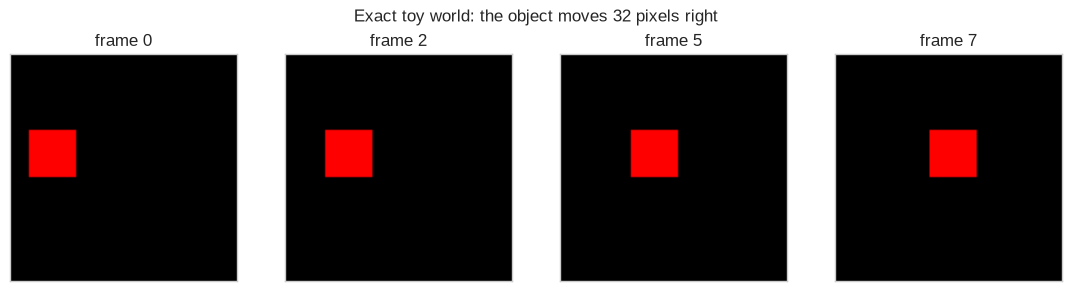

In [28]:
if MAIN:
    toy_video = make_world_video("red_square", 8, 32, dx=32, frames=8, size=96)
frame_slots = [0, 2, 5, 7]
if MAIN:
    fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), constrained_layout=True)
if MAIN:
    for axis, frame_slot in zip(axes, frame_slots):
        rgb = ((toy_video[frame_slot].permute(1, 2, 0) + 1.0) / 2.0).clamp(0, 1)
        axis.imshow(rgb)
        axis.set_title(f"frame {frame_slot}")
        axis.set_xticks([]); axis.set_yticks([])
if MAIN:
    fig.suptitle("Exact toy world: the object moves 32 pixels right")
if MAIN:
    toy_video_path = controls_assets_dir / "jepa_world_model_toy_video.png"
if MAIN:
    fig.savefig(toy_video_path, dpi=170, bbox_inches="tight")
if MAIN:
    plt.show()

<img src="../../exercises/part2_vjepa/media/jepa_world_model_toy_video.png" alt="Expected deterministic video strip" width="950">

Predict how padding changes token count and patch specificity.

### Exercise 2: Map Object Boxes to V-JEPA Tokens

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Implement the image-to-token geometry used by the causal intervention. Select every token whose cell
center falls inside the padded object box.

<details>
<summary>Expected output</summary>

```text
        All tests in `test_bbox_to_vjepa_tokens_ground_truth` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

A 96-pixel image and a 12-token grid give 8-pixel cells. Test cell centers, not top-left corners,
against the padded box.

</details>

<details>
<summary>Common bugs</summary>

- transposing x and y;
- using row indices without flattening;
- selecting only the unpadded object interior;
- returning duplicate token indices.

</details>

<details>
<summary>Interpretation</summary>

The patch has a preregistered spatial target. Selecting tokens after observing the intervention
would make the causal result circular.

</details>

<details>
<summary>Solution</summary>

```python
        def bbox_to_vjepa_tokens(
    bbox: tuple[int, int, int, int],
    *,
    image_size: int = 96,
    token_grid: int = 12,
    pad: int = 4,
) -> list[int]:
    """Map an image-space object box to the corresponding 12x12 V-JEPA token grid."""

    x0, y0, x1, y1 = bbox
    cell = image_size / token_grid
    tokens = []
    for gy in range(token_grid):
        for gx in range(token_grid):
            cx = (gx + 0.5) * cell
            cy = (gy + 0.5) * cell
            if x0 - pad <= cx <= x1 + pad and y0 - pad <= cy <= y1 + pad:
                tokens.append(gy * token_grid + gx)
    return tokens or [token_grid * token_grid // 2]
```

</details>

In [29]:
def bbox_to_vjepa_tokens(
    bbox: tuple[int, int, int, int],
    *,
    image_size: int = 96,
    token_grid: int = 12,
    pad: int = 4,
) -> list[int]:
    """Map an image-space object box to the corresponding 12x12 V-JEPA token grid."""

    x0, y0, x1, y1 = bbox
    cell = image_size / token_grid
    tokens = []
    for gy in range(token_grid):
        for gx in range(token_grid):
            cx = (gx + 0.5) * cell
            cy = (gy + 0.5) * cell
            if x0 - pad <= cx <= x1 + pad and y0 - pad <= cy <= y1 + pad:
                tokens.append(gy * token_grid + gx)
    return tokens or [token_grid * token_grid // 2]
if MAIN:

    controls_tests.test_bbox_to_vjepa_tokens_ground_truth(bbox_to_vjepa_tokens)

All tests in `test_bbox_to_vjepa_tokens_ground_truth` passed!


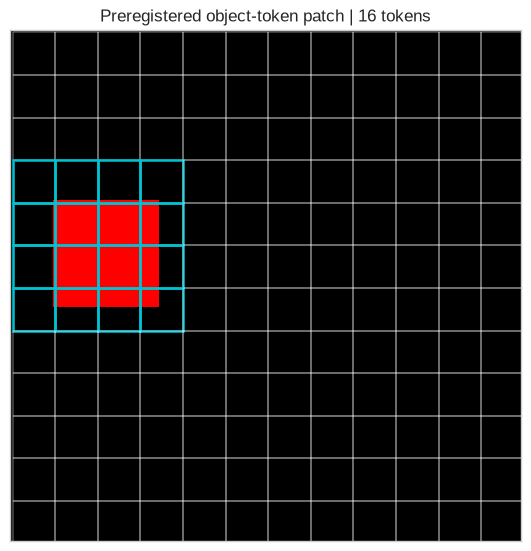

In [30]:
box = (8, 32, 28, 52)
if MAIN:
    selected_tokens = bbox_to_vjepa_tokens(box)
if MAIN:
    frame = ((toy_video[0].permute(1, 2, 0) + 1.0) / 2.0).clamp(0, 1)
if MAIN:
    fig, axis = plt.subplots(figsize=(5.4, 5.4), constrained_layout=True)
if MAIN:
    axis.imshow(frame)
if MAIN:
    for token in range(12 * 12):
        row, col = divmod(token, 12)
        color = "#00c2d1" if token in selected_tokens else "#ffffff"
        width = 1.8 if token in selected_tokens else 0.35
        axis.add_patch(Rectangle((col * 8, row * 8), 8, 8, fill=False, edgecolor=color, linewidth=width))
if MAIN:
    axis.set_title(f"Preregistered object-token patch | {len(selected_tokens)} tokens")
if MAIN:
    axis.set_xticks([]); axis.set_yticks([])
if MAIN:
    token_grid_path = controls_assets_dir / "jepa_world_model_token_grid.png"
if MAIN:
    fig.savefig(token_grid_path, dpi=170, bbox_inches="tight")
if MAIN:
    plt.show()

<img src="../../exercises/part2_vjepa/media/jepa_world_model_token_grid.png" alt="Expected image-to-token mapping" width="950">

Predict a paired-cosine input with a shape error and a high-similarity background shortcut.

### Exercise 3: Measure Paired Latent Similarity

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Implement row-wise cosine similarity. Pairing matters: each predicted latent is compared with its
own target, not every target in the batch.

<details>
<summary>Expected output</summary>

```text
        All tests in `test_paired_cosine_toy_oracle` passed!
All tests in `test_paired_cosine_rejects_shape_mismatch` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Multiply paired rows, sum over the final dimension, and divide by the product of row norms. Reject
shape mismatch before arithmetic.

</details>

<details>
<summary>Common bugs</summary>

- computing a full similarity matrix;
- allowing broadcasting;
- omitting the norm clamp;
- leaving integer inputs uncast.

</details>

<details>
<summary>Interpretation</summary>

Cosine measures direction but ignores scale. The live masked-prediction gate therefore also uses MSE
and a copy baseline.

</details>

<details>
<summary>Solution</summary>

```python
        def paired_cosine(left: t.Tensor, right: t.Tensor, *, eps: float = 1e-8) -> t.Tensor:
    """Return row-wise cosine similarities for two equally-shaped embedding batches."""

    if left.shape != right.shape:
        raise ValueError("left and right must have the same shape.")
    if left.ndim < 2:
        raise ValueError("left and right must have shape (..., d_model).")
    left_float = left.float()
    right_float = right.float()
    numerator = (left_float * right_float).sum(dim=-1)
    denominator = left_float.norm(dim=-1) * right_float.norm(dim=-1)
    return numerator / denominator.clamp_min(eps)
```

</details>

In [31]:
def paired_cosine(left: t.Tensor, right: t.Tensor, *, eps: float = 1e-8) -> t.Tensor:
    """Return row-wise cosine similarities for two equally-shaped embedding batches."""

    if left.shape != right.shape:
        raise ValueError("left and right must have the same shape.")
    if left.ndim < 2:
        raise ValueError("left and right must have shape (..., d_model).")
    left_float = left.float()
    right_float = right.float()
    numerator = (left_float * right_float).sum(dim=-1)
    denominator = left_float.norm(dim=-1) * right_float.norm(dim=-1)
    return numerator / denominator.clamp_min(eps)
if MAIN:

    controls_tests.test_paired_cosine_toy_oracle(paired_cosine)

if MAIN:
    controls_tests.test_paired_cosine_rejects_shape_mismatch(paired_cosine)

All tests in `test_paired_cosine_toy_oracle` passed!
All tests in `test_paired_cosine_rejects_shape_mismatch` passed!


Predict how identical features can have high cosine while failing rank and variance checks.

### Exercise 4: Reject Representation Collapse

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Implement a collapse diagnostic using feature variance and the entropy-based effective rank of the
centered singular-value spectrum.

<details>
<summary>Expected output</summary>

```text
        All tests in `test_collapse_diagnostics_rejects_identical_features` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Flatten all non-example dimensions, center over examples, square singular values into a spectrum,
normalize to probabilities, and exponentiate spectral entropy.

</details>

<details>
<summary>Common bugs</summary>

- measuring variance before converting to float;
- forgetting to center;
- using raw singular values instead of squared energy;
- allowing NaNs to pass.

</details>

<details>
<summary>Interpretation</summary>

A low prediction loss can be trivial if every target collapses to one vector. Non-collapse is
necessary, though not sufficient, for world-state evidence.

</details>

<details>
<summary>Solution</summary>

```python
        def collapse_diagnostics_report(
    features: t.Tensor,
    *,
    min_feature_std: float = 0.1,
    min_effective_rank: float = 3.0,
) -> CollapseDiagnosticsReport:
    """Check that a latent representation is finite and not collapsed to one direction."""

    if features.ndim < 2:
        raise ValueError("features must have at least example and feature dimensions.")
    flat = features.float().reshape(features.shape[0], -1)
    finite_features = bool(t.isfinite(flat).all().item())
    feature_std = flat.std().item()
    centered = flat - flat.mean(dim=0, keepdim=True)
    singular_values = t.linalg.svdvals(centered)
    spectrum = singular_values.pow(2)
    probabilities = spectrum / spectrum.sum().clamp_min(1e-12)
    entropy = -(probabilities * probabilities.clamp_min(1e-12).log()).sum()
    effective_rank = entropy.exp().item()
    return CollapseDiagnosticsReport(
        finite_features=finite_features,
        feature_std=feature_std,
        effective_rank=effective_rank,
        non_collapsed=(
            finite_features
            and feature_std >= min_feature_std
            and effective_rank >= min_effective_rank
        ),
    )
```

</details>

In [32]:
def collapse_diagnostics_report(
    features: t.Tensor,
    *,
    min_feature_std: float = 0.1,
    min_effective_rank: float = 3.0,
) -> CollapseDiagnosticsReport:
    """Check that a latent representation is finite and not collapsed to one direction."""

    if features.ndim < 2:
        raise ValueError("features must have at least example and feature dimensions.")
    flat = features.float().reshape(features.shape[0], -1)
    finite_features = bool(t.isfinite(flat).all().item())
    feature_std = flat.std().item()
    centered = flat - flat.mean(dim=0, keepdim=True)
    singular_values = t.linalg.svdvals(centered)
    spectrum = singular_values.pow(2)
    probabilities = spectrum / spectrum.sum().clamp_min(1e-12)
    entropy = -(probabilities * probabilities.clamp_min(1e-12).log()).sum()
    effective_rank = entropy.exp().item()
    return CollapseDiagnosticsReport(
        finite_features=finite_features,
        feature_std=feature_std,
        effective_rank=effective_rank,
        non_collapsed=(
            finite_features
            and feature_std >= min_feature_std
            and effective_rank >= min_effective_rank
        ),
    )
if MAIN:

    controls_tests.test_collapse_diagnostics_rejects_identical_features(collapse_diagnostics_report)

All tests in `test_collapse_diagnostics_rejects_identical_features` passed!


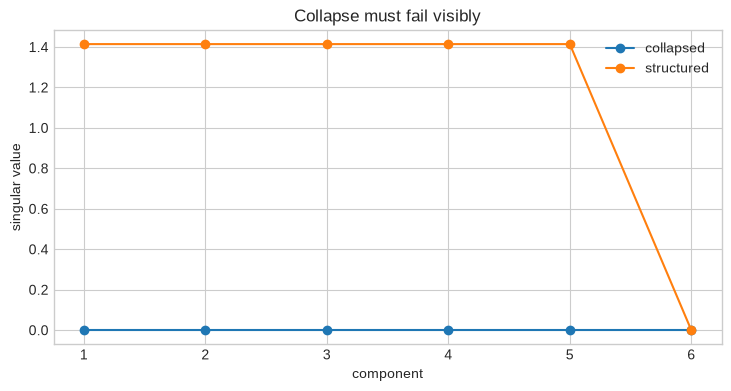

In [33]:
if MAIN:
    structured = t.cat([t.eye(6), t.eye(6)], dim=0)
if MAIN:
    collapsed = t.ones_like(structured)
if MAIN:
    structured_report = collapse_diagnostics_report(structured, min_effective_rank=3.0)
if MAIN:
    collapsed_report = collapse_diagnostics_report(collapsed, min_effective_rank=3.0)
spectrum_rows = []
if MAIN:
    for name, values in [("structured", structured), ("collapsed", collapsed)]:
        singular = t.linalg.svdvals(values - values.mean(dim=0, keepdim=True))
        for index, value in enumerate(singular):
            spectrum_rows.append((name, index + 1, float(value)))
if MAIN:
    spectrum = pd.DataFrame(spectrum_rows, columns=["representation", "component", "singular_value"])
if MAIN:
    fig, axis = plt.subplots(figsize=(7.2, 3.8), constrained_layout=True)
if MAIN:
    for name, group in spectrum.groupby("representation"):
        axis.plot(group.component, group.singular_value, marker="o", label=name)
if MAIN:
    axis.set(xlabel="component", ylabel="singular value", title="Collapse must fail visibly")
if MAIN:
    axis.legend()
if MAIN:
    collapse_path = controls_assets_dir / "jepa_world_model_collapse_control.png"
if MAIN:
    fig.savefig(collapse_path, dpi=170, bbox_inches="tight")
if MAIN:
    plt.show()
if MAIN:
    structured_report, collapsed_report

<img src="../../exercises/part2_vjepa/media/jepa_world_model_collapse_control.png" alt="Expected collapse control" width="950">

Predict the shuffled-label held-out baseline before state decoding.

### Exercise 5: Grade Held-Out State Probes

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Implement the report that converts held-out probe logits into accuracy. The live probe is trained on
150 clips and evaluated on 50 held-out clips; shuffled labels are the matched control.

<details>
<summary>Expected output</summary>

```text
        All tests in `test_state_probe_report_rejects_shuffled_labels` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Take `argmax` over classes, flatten labels, check one label per row, then compare accuracy with the
declared threshold.

</details>

<details>
<summary>Common bugs</summary>

- reporting training accuracy;
- fitting preprocessing on held-out rows;
- comparing logits directly to integer labels;
- accepting a score that survives label shuffling.

</details>

<details>
<summary>Interpretation</summary>

Probe success establishes decodability. It becomes stronger only when an intervention later moves
the decoded state selectively.

</details>

<details>
<summary>Solution</summary>

```python
        def world_state_probe_report(
    probe_logits: t.Tensor,
    labels: t.Tensor,
    *,
    min_accuracy: float = 0.9,
) -> WorldStateProbeReport:
    """Check whether a latent world-model state predicts held-out labels."""

    if probe_logits.ndim != 2:
        raise ValueError("probe_logits must have shape (examples, classes).")
    flattened_labels = labels.flatten().long()
    if flattened_labels.numel() != probe_logits.shape[0]:
        raise ValueError("labels must have one value per example.")

    predictions = probe_logits.argmax(dim=-1)
    accuracy = predictions.eq(flattened_labels).float().mean().item()
    return WorldStateProbeReport(
        accuracy=accuracy,
        predicts_state=accuracy >= min_accuracy,
    )
```

</details>

In [34]:
def world_state_probe_report(
    probe_logits: t.Tensor,
    labels: t.Tensor,
    *,
    min_accuracy: float = 0.9,
) -> WorldStateProbeReport:
    """Check whether a latent world-model state predicts held-out labels."""

    if probe_logits.ndim != 2:
        raise ValueError("probe_logits must have shape (examples, classes).")
    flattened_labels = labels.flatten().long()
    if flattened_labels.numel() != probe_logits.shape[0]:
        raise ValueError("labels must have one value per example.")

    predictions = probe_logits.argmax(dim=-1)
    accuracy = predictions.eq(flattened_labels).float().mean().item()
    return WorldStateProbeReport(
        accuracy=accuracy,
        predicts_state=accuracy >= min_accuracy,
    )
if MAIN:

    controls_tests.test_state_probe_report_rejects_shuffled_labels(world_state_probe_report)

All tests in `test_state_probe_report_rejects_shuffled_labels` passed!


Predict what happens when actions are shuffled in a predictor that ignores action.

### Exercise 6: Demand Action-Conditioned Prediction

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Implement a rollout gate. A learned transition only passes when its held-out loss beats both copying
the current latent and supplying a shuffled action.

<details>
<summary>Expected output</summary>

```text
        All tests in `test_latent_rollout_report_rejects_copy_and_shuffled_controls` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Compute two independent ratios: trained loss over copy loss, and trained loss over shuffled-action
loss. Both must pass.

</details>

<details>
<summary>Common bugs</summary>

- comparing training losses;
- using an easier shuffled batch;
- accepting improvement over copy but not shuffled action;
- hiding very small losses without a log scale.

</details>

<details>
<summary>Interpretation</summary>

If shuffling actions does not hurt, the predictor has learned temporal similarity rather than an
action-conditioned transition.

</details>

<details>
<summary>Solution</summary>

```python
        def latent_rollout_report(
    rollout_loss: float,
    copy_baseline_loss: float,
    shuffled_action_loss: float,
    *,
    max_rollout_to_copy: float = 0.8,
    max_rollout_to_shuffled: float = 0.8,
) -> LatentRolloutReport:
    """Check that an action-conditioned latent rollout beats copy and shuffled-action baselines."""

    rollout = float(rollout_loss)
    copy = float(copy_baseline_loss)
    shuffled = float(shuffled_action_loss)
    beats_copy = rollout <= copy * max_rollout_to_copy
    shuffled_fails = rollout <= shuffled * max_rollout_to_shuffled
    return LatentRolloutReport(
        rollout_loss=rollout,
        copy_baseline_loss=copy,
        shuffled_action_loss=shuffled,
        beats_copy_baseline=beats_copy,
        shuffled_action_fails=shuffled_fails,
        rollout_passes=beats_copy and shuffled_fails,
    )
```

</details>

In [35]:
def latent_rollout_report(
    rollout_loss: float,
    copy_baseline_loss: float,
    shuffled_action_loss: float,
    *,
    max_rollout_to_copy: float = 0.8,
    max_rollout_to_shuffled: float = 0.8,
) -> LatentRolloutReport:
    """Check that an action-conditioned latent rollout beats copy and shuffled-action baselines."""

    rollout = float(rollout_loss)
    copy = float(copy_baseline_loss)
    shuffled = float(shuffled_action_loss)
    beats_copy = rollout <= copy * max_rollout_to_copy
    shuffled_fails = rollout <= shuffled * max_rollout_to_shuffled
    return LatentRolloutReport(
        rollout_loss=rollout,
        copy_baseline_loss=copy,
        shuffled_action_loss=shuffled,
        beats_copy_baseline=beats_copy,
        shuffled_action_fails=shuffled_fails,
        rollout_passes=beats_copy and shuffled_fails,
    )
if MAIN:

    controls_tests.test_latent_rollout_report_rejects_copy_and_shuffled_controls(latent_rollout_report)

All tests in `test_latent_rollout_report_rejects_copy_and_shuffled_controls` passed!


Predict which two conditions a persistence gate must satisfy.

### Exercise 7: Separate Occlusion From Absence

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Implement the object-permanence gate. The occluded latent must remain similar to the visible latent
and beat an otherwise matched absent-object video by a declared margin.

<details>
<summary>Expected output</summary>

```text
        All tests in `test_object_permanence_report_rejects_absent_and_different_object_controls` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Average each paired score family and require both an absolute occluded score and an
occluded-minus-absent gap.

</details>

<details>
<summary>Common bugs</summary>

- checking visible versus occluded only;
- using an absent video with a different background;
- reporting a high score without its gap;
- treating different-object similarity as permanence.

</details>

<details>
<summary>Interpretation</summary>

The absent control is intentionally hard: V-JEPA latents are globally similar, so the claim rests on
the *gap*, not on an impressive-looking cosine alone.

</details>

<details>
<summary>Solution</summary>

```python
        def object_permanence_report(
    visible_scores: t.Tensor,
    occluded_scores: t.Tensor,
    absent_scores: t.Tensor,
    *,
    min_occluded_score: float = 0.6,
    min_absent_gap: float = 0.3,
) -> ObjectPermanenceReport:
    """Check whether occluded objects stay represented more than absent objects."""

    visible_mean = visible_scores.float().mean().item()
    occluded_mean = occluded_scores.float().mean().item()
    absent_mean = absent_scores.float().mean().item()
    occluded_absent_gap = occluded_mean - absent_mean
    preserves_occluded_object = (
        occluded_mean >= min_occluded_score
        and occluded_absent_gap >= min_absent_gap
    )
    return ObjectPermanenceReport(
        visible_mean=visible_mean,
        occluded_mean=occluded_mean,
        absent_mean=absent_mean,
        occluded_absent_gap=occluded_absent_gap,
        preserves_occluded_object=preserves_occluded_object,
    )
```

</details>

In [36]:
def object_permanence_report(
    visible_scores: t.Tensor,
    occluded_scores: t.Tensor,
    absent_scores: t.Tensor,
    *,
    min_occluded_score: float = 0.6,
    min_absent_gap: float = 0.3,
) -> ObjectPermanenceReport:
    """Check whether occluded objects stay represented more than absent objects."""

    visible_mean = visible_scores.float().mean().item()
    occluded_mean = occluded_scores.float().mean().item()
    absent_mean = absent_scores.float().mean().item()
    occluded_absent_gap = occluded_mean - absent_mean
    preserves_occluded_object = (
        occluded_mean >= min_occluded_score
        and occluded_absent_gap >= min_absent_gap
    )
    return ObjectPermanenceReport(
        visible_mean=visible_mean,
        occluded_mean=occluded_mean,
        absent_mean=absent_mean,
        occluded_absent_gap=occluded_absent_gap,
        preserves_occluded_object=preserves_occluded_object,
    )
if MAIN:

    controls_tests.test_object_permanence_report_rejects_absent_and_different_object_controls(object_permanence_report)

All tests in `test_object_permanence_report_rejects_absent_and_different_object_controls` passed!


Predict why a targeted patch needs a same-size random patch control.

### Exercise 8: Make the State Causal

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-20 minutes on this exercise.
> ```

Implement the patch gate. Patching tokens from a right-position object into a left-position object
should move a held-out position probe; the same number of random source and target tokens should
not.

<details>
<summary>Expected output</summary>

```text
        All tests in `test_causal_latent_patch_report_rejects_random_control` passed!
```

</details>

<details>
<summary>Help - getting started</summary>

Average targeted and random effects, subtract to get the specificity gap, and require both a minimum
targeted effect and minimum gap.

</details>

<details>
<summary>Common bugs</summary>

- comparing different patch sizes;
- selecting object tokens after seeing the effect;
- reporting only the targeted effect;
- patching the pooled latent instead of local tokens.

</details>

<details>
<summary>Interpretation</summary>

The intervention is narrow: it changes a position-probe readout of frozen latent tokens. It does not
prove V-JEPA uses that state for planning or control.

</details>

<details>
<summary>Solution</summary>

```python
        def causal_latent_patch_report(
    object_patch_effects: t.Tensor,
    random_patch_effects: t.Tensor,
    *,
    min_object_patch_effect: float = 0.2,
    min_patch_random_gap: float = 0.1,
) -> CausalLatentPatchReport:
    """Compare targeted latent-token patches against same-size random-token patches."""

    if object_patch_effects.numel() == 0 or random_patch_effects.numel() == 0:
        raise ValueError("patch effect tensors must be non-empty.")
    object_effect = object_patch_effects.float().mean().item()
    random_effect = random_patch_effects.float().mean().item()
    gap = object_effect - random_effect
    return CausalLatentPatchReport(
        object_patch_effect=object_effect,
        random_patch_effect=random_effect,
        patch_random_gap=gap,
        causal_patch_passes=(
            object_effect >= min_object_patch_effect and gap >= min_patch_random_gap
        ),
    )
```

</details>

In [37]:
def causal_latent_patch_report(
    object_patch_effects: t.Tensor,
    random_patch_effects: t.Tensor,
    *,
    min_object_patch_effect: float = 0.2,
    min_patch_random_gap: float = 0.1,
) -> CausalLatentPatchReport:
    """Compare targeted latent-token patches against same-size random-token patches."""

    if object_patch_effects.numel() == 0 or random_patch_effects.numel() == 0:
        raise ValueError("patch effect tensors must be non-empty.")
    object_effect = object_patch_effects.float().mean().item()
    random_effect = random_patch_effects.float().mean().item()
    gap = object_effect - random_effect
    return CausalLatentPatchReport(
        object_patch_effect=object_effect,
        random_patch_effect=random_effect,
        patch_random_gap=gap,
        causal_patch_passes=(
            object_effect >= min_object_patch_effect and gap >= min_patch_random_gap
        ),
    )
if MAIN:

    controls_tests.test_causal_latent_patch_report_rejects_random_control(causal_latent_patch_report)

All tests in `test_causal_latent_patch_report_rejects_random_control` passed!


Predict which frozen-model result could falsify the world-state interpretation before reading
expected CUDA output.

## Part 2: Run the Pinned V-JEPA 2 Experiment

The expensive plumbing below is deliberately shared: loading the pinned
`facebook/vjepa2-vitl-fpc64-256` checkpoint, batching 800 video variants through CUDA, and training
the small held-out heads. The experiment returns every learner-facing video, latent, label,
baseline, and patch effect used in the figures.

The core reasoning remains visible: you wrote the world, token mapping, metrics, and control gates
yourself.

In [38]:
if MAIN:
    signature_result = controls_reference.run_vjepa2_world_model_signature_result(max_vram_gb=24.0)
if MAIN:
    controls_tests.validate_vjepa2_signature_visual_payload(signature_result)
if MAIN:
    print(
        signature_result["model_id"], "|",
        t.cuda.get_device_name(0), "| CUDA", t.version.cuda, "|",
        f"peak allocated VRAM {signature_result['peak_vram_gb']:.3f} GB",
    )

/home/bitwise/Documents/ARENA_3.0_Extended/.claude/worktrees/env-upgrade-54fd7e/.venv/lib/python3.14/site-packages/torchao/quantization/quant_api.py:1558: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.


All tests in `validate_vjepa2_signature_visual_payload` passed!
facebook/vjepa2-vitl-fpc64-256 | NVIDIA GeForce RTX 5090 Laptop GPU | CUDA 13.4 | peak allocated VRAM 0.678 GB


<details>
<summary>Expected output</summary>

```text
All tests in `validate_vjepa2_signature_visual_payload` passed!
facebook/vjepa2-vitl-fpc64-256 | NVIDIA GeForce RTX 5090 Laptop GPU | CUDA 13.2 | peak allocated VRAM about 0.75 GB
```

</details>

<details>
<summary>Help - what remains hidden?</summary>

Only checkpoint loading, batched feature extraction, and repetitive training loops. The inputs,
labels, learned-latent outputs, baselines, and interventions are returned and visualized below.

</details>

## Signature Result: See the World, Then Test the Latent

First inspect the actual finite world. Each row uses the same initial red-square state. The
next-state row moves right by the declared action; the occluded row hides an existing object; the
absent row shows the same occluder with no object behind it.

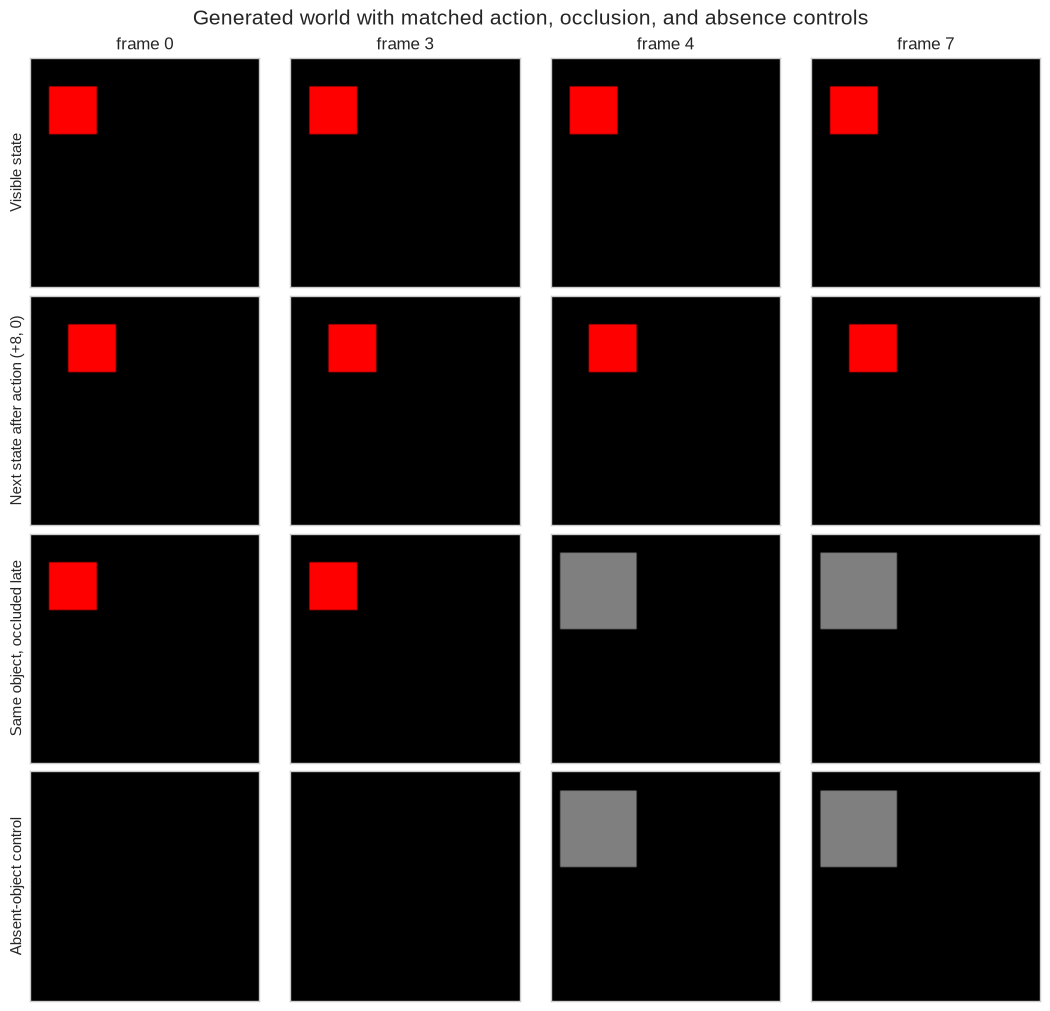

In [39]:
def video_frames_to_rgb(frames: t.Tensor) -> t.Tensor:
    return ((frames.permute(0, 2, 3, 1).float() + 1.0) / 2.0).clamp(0, 1)
if MAIN:

    display_case = signature_result["visual_payload"]["cases"][0]
conditions = [
    ("visible_frames", "Visible state"),
    ("next_frames", "Next state after action (+8, 0)"),
    ("occluded_frames", "Same object, occluded late"),
    ("absent_frames", "Absent-object control"),
]
if MAIN:
    fig, axes = plt.subplots(4, 4, figsize=(10.5, 10), constrained_layout=True)
if MAIN:
    for row, (key, label) in enumerate(conditions):
        frames = video_frames_to_rgb(display_case[key])
        for col, (frame_index, frame) in enumerate(zip(display_case["frame_indices"], frames)):
            axes[row, col].imshow(frame)
            axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
            if row == 0:
                axes[row, col].set_title(f"frame {frame_index}")
            if col == 0:
                axes[row, col].set_ylabel(label, fontsize=11)
if MAIN:
    fig.suptitle("Generated world with matched action, occlusion, and absence controls", fontsize=15)
if MAIN:
    live_video_path = controls_assets_dir / "jepa_world_model_live_video_strip.png"
if MAIN:
    fig.savefig(live_video_path, dpi=160, bbox_inches="tight")
if MAIN:
    plt.show()

<img src="../../exercises/part2_vjepa/media/jepa_world_model_live_video_strip.png" alt="Expected generated-video controls" width="950">

,claim,target,matched control,direction
0,masked prediction,0.000002,0.000070,lower is better
1,action rollout,0.000014,0.000035,lower is better
2,object 1-NN,1.000000,0.460000,higher is better
3,occlusion,0.962239,0.880990,higher is better
4,token patch,0.999978,0.000009,higher is better


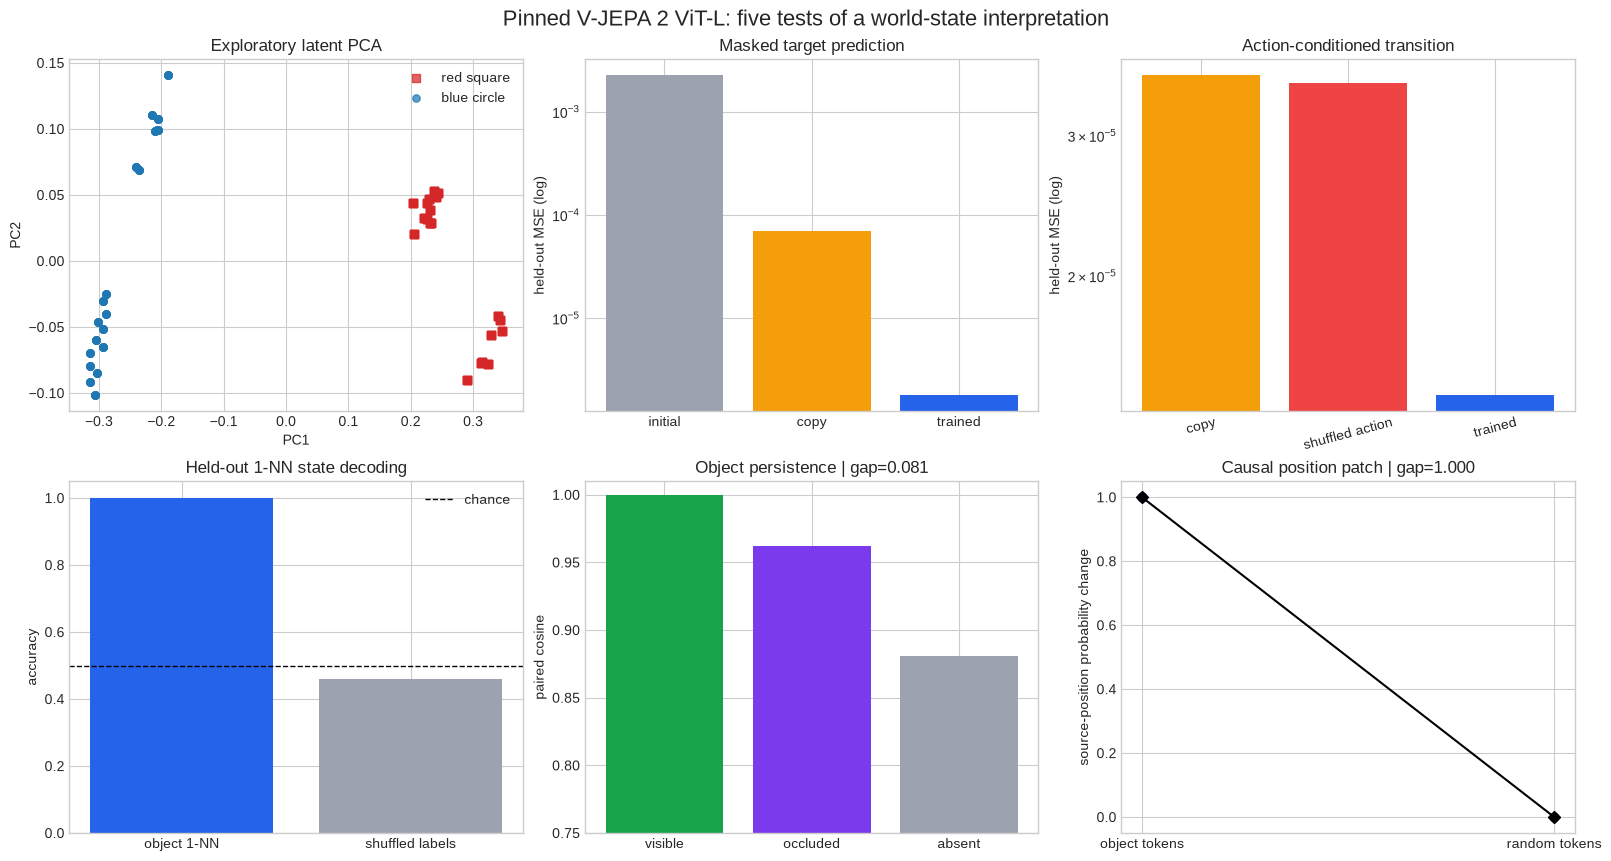

In [40]:
if MAIN:
    payload = signature_result["visual_payload"]
if MAIN:
    features = payload["pooled_features"].float()
if MAIN:
    centered = features - features.mean(dim=0, keepdim=True)
if MAIN:
    t.manual_seed(0)
if MAIN:
    _, _, components = t.pca_lowrank(centered, q=2, center=False, niter=4)
if MAIN:
    coordinates = centered @ components
if MAIN:

    permanence = signature_result["object_permanence"]
if MAIN:
    evidence_table = pd.DataFrame(
        [
            ("masked prediction", signature_result["masked_prediction_final_loss"], signature_result["masked_prediction_copy_baseline_loss"], "lower is better"),
            ("action rollout", signature_result["latent_rollout_final_loss"], signature_result["latent_rollout_shuffled_action_loss"], "lower is better"),
            ("object 1-NN", signature_result["state_probe_knn_accuracy"], signature_result["state_probe_shuffled_knn_accuracy"], "higher is better"),
            ("occlusion", permanence["occluded_mean"], permanence["absent_mean"], "higher is better"),
            ("token patch", signature_result["causal_latent_patching"]["object_patch_effect"], signature_result["causal_latent_patching"]["random_patch_effect"], "higher is better"),
        ],
        columns=["claim", "target", "matched control", "direction"],
    )
if MAIN:
    display(evidence_table.style.format({"target": "{:.6f}", "matched control": "{:.6f}"}))
if MAIN:

    fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), constrained_layout=True)
if MAIN:
    labels = payload["labels"]
if MAIN:
    for label, name, color, marker in [(0, "red square", "#d62728", "s"), (1, "blue circle", "#1f77b4", "o")]:
        selected = labels == label
        axes[0, 0].scatter(coordinates[selected, 0], coordinates[selected, 1], s=28, alpha=0.72, label=name, color=color, marker=marker)
if MAIN:
    axes[0, 0].set(title="Exploratory latent PCA", xlabel="PC1", ylabel="PC2")
if MAIN:
    axes[0, 0].legend()
if MAIN:

    masked_values = [
        signature_result["masked_prediction"]["initial_loss"],
        signature_result["masked_prediction_copy_baseline_loss"],
        signature_result["masked_prediction_final_loss"],
    ]
if MAIN:
    axes[0, 1].bar(["initial", "copy", "trained"], masked_values, color=["#9ca3af", "#f59e0b", "#2563eb"])
if MAIN:
    axes[0, 1].set_yscale("log")
if MAIN:
    axes[0, 1].set(title="Masked target prediction", ylabel="held-out MSE (log)")
if MAIN:

    rollout_values = [
        signature_result["latent_rollout_copy_baseline_loss"],
        signature_result["latent_rollout_shuffled_action_loss"],
        signature_result["latent_rollout_final_loss"],
    ]
if MAIN:
    axes[0, 2].bar(["copy", "shuffled action", "trained"], rollout_values, color=["#f59e0b", "#ef4444", "#2563eb"])
if MAIN:
    axes[0, 2].set_yscale("log")
if MAIN:
    axes[0, 2].tick_params(axis="x", rotation=15)
if MAIN:
    axes[0, 2].set(title="Action-conditioned transition", ylabel="held-out MSE (log)")
if MAIN:

    probe_values = [signature_result["state_probe_knn_accuracy"], signature_result["state_probe_shuffled_knn_accuracy"]]
if MAIN:
    axes[1, 0].bar(["object 1-NN", "shuffled labels"], probe_values, color=["#2563eb", "#9ca3af"])
if MAIN:
    axes[1, 0].axhline(0.5, color="black", linestyle="--", linewidth=1, label="chance")
if MAIN:
    axes[1, 0].set_ylim(0, 1.05)
if MAIN:
    axes[1, 0].set(title="Held-out 1-NN state decoding", ylabel="accuracy")
if MAIN:
    axes[1, 0].legend()
if MAIN:

    axes[1, 1].bar(
        ["visible", "occluded", "absent"],
        [permanence["visible_mean"], permanence["occluded_mean"], permanence["absent_mean"]],
        color=["#16a34a", "#7c3aed", "#9ca3af"],
    )
if MAIN:
    axes[1, 1].set_ylim(0.75, 1.01)
if MAIN:
    axes[1, 1].set(title=f"Object persistence | gap={permanence['occluded_absent_gap']:.3f}", ylabel="paired cosine")
if MAIN:

    object_effects = payload["object_patch_effects"].numpy()
if MAIN:
    random_effects = payload["random_patch_effects"].numpy()
if MAIN:
    axes[1, 2].scatter(np.zeros_like(object_effects), object_effects, color="#2563eb", alpha=0.7, label="object tokens")
if MAIN:
    axes[1, 2].scatter(np.ones_like(random_effects), random_effects, color="#9ca3af", alpha=0.7, label="same-size random")
if MAIN:
    axes[1, 2].plot([0, 1], [object_effects.mean(), random_effects.mean()], color="black", marker="D", linewidth=1.5)
if MAIN:
    axes[1, 2].set_xticks([0, 1], ["object tokens", "random tokens"])
if MAIN:
    axes[1, 2].set(title=f"Causal position patch | gap={object_effects.mean() - random_effects.mean():.3f}", ylabel="source-position probability change")
if MAIN:

    fig.suptitle("Pinned V-JEPA 2 ViT-L: five tests of a world-state interpretation", fontsize=16)
if MAIN:
    live_signature_path = controls_assets_dir / "jepa_world_model_live_signature.png"
if MAIN:
    fig.savefig(live_signature_path, dpi=180, bbox_inches="tight")
if MAIN:
    plt.show()

<img src="../../exercises/part2_vjepa/media/jepa_world_model_live_signature.png" alt="Expected V-JEPA 2 world-state evidence" width="950">

<details>
<summary>Interpretation</summary>

The five panels answer different failure modes. PCA is exploratory only. Held-out probes reject
non-decoding; copy and shuffled-action losses reject static similarity; the absent video rejects
occluder/background shortcuts; and the same-size random patch rejects generic token corruption. The
targeted patch is the causal evidence, but only for a position-probe readout in this controlled
world.

</details>

Commit case, condition, frame and padding before revealing the selected token overlay.

## Try It Yourself

Change `play_case`, `play_condition`, `play_frame_slot`, or `play_pad`. The cell redraws a real
input from the CUDA run and overlays the exact tokens your patch rule would select. A useful
perturbation is to increase `play_pad` until background tokens dominate; the patch result should
then be treated as less specific.

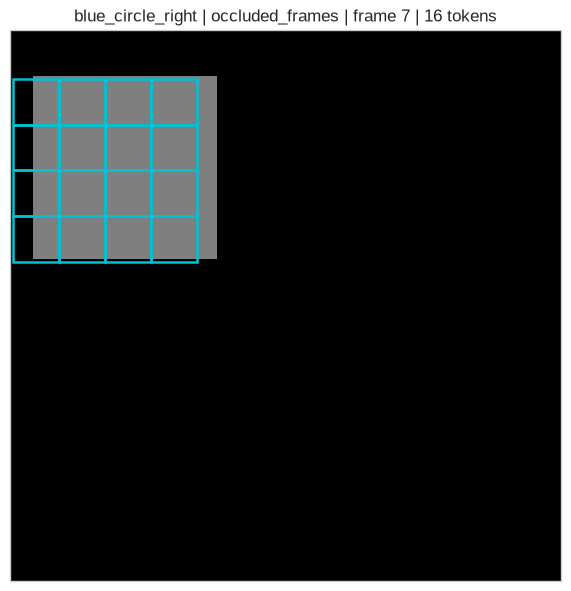

In [41]:
play_case = "blue_circle_right"  # red_square_right | blue_circle_right
play_condition = "occluded_frames"  # visible_frames | next_frames | occluded_frames | absent_frames
play_frame_slot = 3  # 0..3 indexes the retained frames [0, 3, 4, 7]
play_pad = 4
if MAIN:

    case = next(item for item in payload["cases"] if item["case_id"] == play_case)
if MAIN:
    bbox = tuple(case["bbox"])
if MAIN:
    if play_condition == "next_frames":
        dx, dy = case["action"]
        bbox = (bbox[0] + dx, bbox[1] + dy, bbox[2] + dx, bbox[3] + dy)
if MAIN:
    play_tokens = bbox_to_vjepa_tokens(bbox, pad=play_pad)
if MAIN:
    frame = video_frames_to_rgb(case[play_condition])[play_frame_slot]
if MAIN:
    fig, axis = plt.subplots(figsize=(5.8, 5.8), constrained_layout=True)
if MAIN:
    axis.imshow(frame)
if MAIN:
    for token in play_tokens:
        row, col = divmod(token, 12)
        axis.add_patch(Rectangle((col * 8, row * 8), 8, 8, fill=False, edgecolor="#00c2d1", linewidth=1.8))
if MAIN:
    axis.set_title(f"{play_case} | {play_condition} | frame {case['frame_indices'][play_frame_slot]} | {len(play_tokens)} tokens")
if MAIN:
    axis.set_xticks([]); axis.set_yticks([])
if MAIN:
    plt.show()

## Bonus: Hunt an Anomaly

Find a case where one piece of evidence succeeds and another fails:

- an occluded clip with high cosine but a small occluded-minus-absent gap;
- a position probe that decodes well but cannot be moved by object-token patching;
- a transition predictor that beats copy but not shuffled actions;
- a large token padding that makes random/background patches competitive;
- a PCA view that looks separated while shuffled-label held-out accuracy remains near chance.

Report which claim survives. Do not average incompatible failures into one “world-model score.”

## Limitations: What this does not show

This section supports a scoped claim about frozen V-JEPA 2 ViT-L latents on deterministic generated
shape videos. It does **not** establish planning, reward prediction, real-video object permanence,
V-JEPA fine-tuning, V-JEPA 2-AC action tokens, dense V-JEPA 2.1 features, or superiority to
VideoMAE, DINO, CLIP, diffusion, or autoregressive world models. The transition head is trained on
frozen features; V-JEPA itself is not retrained here.

## Reading

- Meta FAIR, **V-JEPA 2** model and paper materials.
- Assran et al., **V-JEPA: Latent Feature Prediction for Self-Supervised Learning in Video**.
- Li et al., **Emergent World Representations: Exploring a Sequence Model Trained on a Synthetic Task**.

## Verification Appendix

In [42]:
if MAIN:
    verification_report_path = controls_section_dir / "verification_report.json"
if MAIN:
    committed_evidence = json.loads(verification_report_path.read_text())
if MAIN:
    assert committed_evidence["notebook_id"] == controls_EXERCISE_ID, (
        "The committed evidence should belong to this JEPA exercise."
    )

def controls_run_smoke_test(cpu: bool = True) -> dict:
    return controls_reference.run_smoke_test(cpu=cpu)


def controls_run_gpu_test(max_vram_gb: float = 24.0) -> dict:
    return controls_reference.run_gpu_test(max_vram_gb=max_vram_gb)


def controls_run_full_experiment(max_vram_gb: float = 24.0) -> dict:
    return controls_reference.run_full_experiment(max_vram_gb=max_vram_gb)
if MAIN:


    controls_tests.test_notebook_contract(controls_run_smoke_test)
if MAIN:
    controls_tests.test_committed_verification_report_vjepa_world_controls()
if MAIN:
    controls_tests.test_exercise_notebook_declares_full_verification_contract()
if MAIN:
    print("Live V-JEPA 2 evidence and the committed CUDA report both passed.")

All tests in `test_notebook_contract` passed!
All tests in `test_committed_verification_report_vjepa_world_controls` passed!
All tests in `test_exercise_notebook_declares_full_verification_contract` passed!
Live V-JEPA 2 evidence and the committed CUDA report both passed.


<details>
<summary>Expected output</summary>

```text
All tests in `test_notebook_contract` passed!
All tests in `test_committed_verification_report_vjepa_world_controls` passed!
All tests in `test_exercise_notebook_declares_full_verification_contract` passed!
Live V-JEPA 2 evidence and the committed CUDA report both passed.
```

</details>

# Bonus

## Keep the claims separate when you explain the result

Compare your initial forecast with each signature result and its matched controls. Explain why
future-mask retrieval can retain clip identity without establishing predictive dynamics. Then
separately explain what an occluded-minus-absent gap and a targeted-minus-random token intervention
support in the pinned frozen-model world. Preserve the original negative findings and limitations.